In [3]:
# ============================================================================
# 🧪 CELL 01 — INITIALISATION DU PROJET PANNUKE SEGMENTATION
# ============================================================================
#
# Projet :
#   PanNuke — Segmentation des noyaux cellulaires
#
# Objectifs de cette cellule :
#   1. Vérifier l'environnement Kaggle
#   2. Vérifier GPU / TensorFlow
#   3. Détecter automatiquement PanNuke
#   4. Localiser Fold 1 / Fold 2 / Fold 3
#   5. Vérifier images.npy / masks.npy / types.npy
#   6. Préparer les dossiers output
#
# ============================================================================

import os
import sys
import json
import time
import platform
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf

# ============================================================================
# 1. CONFIGURATION GÉNÉRALE
# ============================================================================

print("=" * 80)
print("🧪 CELL 01 — INITIALISATION PANNUKE SEGMENTATION")
print("=" * 80)

START_TIME = time.time()

# ---------------------------------------------------------------------------
# Dataset
# ---------------------------------------------------------------------------

DATASET_ROOT = Path(
    "/kaggle/input/datasets/mohammedbetkaoui/pannuke-segmentation-btk/PanNuke_Segmentation"
)

# ---------------------------------------------------------------------------
# Output
# ---------------------------------------------------------------------------

OUTPUT_DIR = Path("/kaggle/working/pannuke_output")
MODELS_DIR = OUTPUT_DIR / "models"
FIGURES_DIR = OUTPUT_DIR / "figures"
LOGS_DIR = OUTPUT_DIR / "logs"

for directory in [
    OUTPUT_DIR,
    MODELS_DIR,
    FIGURES_DIR,
    LOGS_DIR
]:
    directory.mkdir(parents=True, exist_ok=True)

print(f"\n📁 Dataset root : {DATASET_ROOT}")
print(f"📁 Output       : {OUTPUT_DIR}")
print(f"📁 Models       : {MODELS_DIR}")
print(f"📁 Figures      : {FIGURES_DIR}")
print(f"📁 Logs         : {LOGS_DIR}")


# ============================================================================
# 2. INFORMATIONS SYSTÈME
# ============================================================================

print("\n" + "=" * 80)
print("💻 INFORMATIONS SYSTÈME")
print("=" * 80)

print(f"Python       : {sys.version.split()[0]}")
print(f"TensorFlow   : {tf.__version__}")
print(f"NumPy        : {np.__version__}")
print(f"Platform     : {platform.platform()}")


# ============================================================================
# 3. VÉRIFICATION GPU
# ============================================================================

print("\n" + "=" * 80)
print("🚀 VÉRIFICATION GPU")
print("=" * 80)

gpus = tf.config.list_physical_devices("GPU")

if gpus:
    print(f"✅ GPU disponible : {len(gpus)}")

    for i, gpu in enumerate(gpus):
        print(f"   GPU {i} : {gpu}")

    # Configuration mémoire dynamique
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)

        print("✅ Memory growth activé")

    except Exception as e:
        print(f"⚠️ Memory growth non configuré : {e}")

else:
    print("⚠️ Aucun GPU détecté.")
    print("➡️ Vérifie Kaggle > Settings > Accelerator > GPU")


# ============================================================================
# 4. STRATÉGIE DISTRIBUTÉE
# ============================================================================

print("\n" + "=" * 80)
print("🧠 STRATÉGIE DISTRIBUÉE")
print("=" * 80)

strategy = tf.distribute.get_strategy()

print(f"Strategy : {strategy}")

try:
    print(f"Nombre de replicas : {strategy.num_replicas_in_sync}")
except Exception:
    pass


# ============================================================================
# 5. VÉRIFICATION DU DATASET
# ============================================================================

print("\n" + "=" * 80)
print("📦 VÉRIFICATION DU DATASET PANNUKE")
print("=" * 80)

if not DATASET_ROOT.exists():
    raise FileNotFoundError(
        f"""
❌ Dataset PanNuke introuvable :

{DATASET_ROOT}

Vérifie le nom du dataset dans /kaggle/input/
"""
    )

print("✅ Dataset PanNuke détecté")


# ============================================================================
# 6. AFFICHAGE DE L'ARBORESCENCE
# ============================================================================

print("\n" + "=" * 80)
print("🌳 ARBORESCENCE DU DATASET")
print("=" * 80)

for path in sorted(DATASET_ROOT.rglob("*")):

    # Limiter l'affichage aux dossiers/fichiers importants
    relative = path.relative_to(DATASET_ROOT)

    if (
        path.name in [
            "images.npy",
            "masks.npy",
            "types.npy",
            "README.md"
        ]
        or path.is_dir() and len(relative.parts) <= 3
    ):
        prefix = "📁" if path.is_dir() else "📄"
        print(f"{prefix} {relative}")


# ============================================================================
# 7. DÉTECTION AUTOMATIQUE DES FOLDS
# ============================================================================

print("\n" + "=" * 80)
print("🔎 DÉTECTION DES FOLDS")
print("=" * 80)

folds = {}

for fold_number in [1, 2, 3]:

    # Recherche robuste de images.npy / masks.npy / types.npy
    image_candidates = list(
        DATASET_ROOT.rglob(f"fold{fold_number}/images.npy")
    )

    mask_candidates = list(
        DATASET_ROOT.rglob(f"fold{fold_number}/masks.npy")
    )

    type_candidates = list(
        DATASET_ROOT.rglob(f"fold{fold_number}/types.npy")
    )

    # Si la recherche ci-dessus ne trouve rien,
    # on recherche simplement les fichiers dans les dossiers du fold.
    if not image_candidates:
        image_candidates = [
            p for p in DATASET_ROOT.rglob("images.npy")
            if f"fold{fold_number}" in str(p).lower()
        ]

    if not mask_candidates:
        mask_candidates = [
            p for p in DATASET_ROOT.rglob("masks.npy")
            if f"fold{fold_number}" in str(p).lower()
        ]

    if not type_candidates:
        type_candidates = [
            p for p in DATASET_ROOT.rglob("types.npy")
            if f"fold{fold_number}" in str(p).lower()
        ]

    folds[fold_number] = {
        "images": image_candidates[0] if image_candidates else None,
        "masks": mask_candidates[0] if mask_candidates else None,
        "types": type_candidates[0] if type_candidates else None,
    }


# ============================================================================
# 8. AFFICHAGE DES FICHIERS TROUVÉS
# ============================================================================

for fold_number, paths in folds.items():

    print(f"\n📦 FOLD {fold_number}")
    print("-" * 60)

    for key, path in paths.items():

        if path is not None:
            print(f"✓ {key:<8} : {path}")
        else:
            print(f"❌ {key:<8} : NON TROUVÉ")


# ============================================================================
# 9. VALIDATION DES FICHIERS
# ============================================================================

print("\n" + "=" * 80)
print("🧪 VALIDATION DES FICHIERS")
print("=" * 80)

for fold_number, paths in folds.items():

    missing_files = [
        key
        for key, path in paths.items()
        if path is None
    ]

    if missing_files:

        print(
            f"⚠️ Fold {fold_number} : "
            f"fichiers manquants → {missing_files}"
        )

    else:

        print(
            f"✅ Fold {fold_number} : "
            f"images.npy + masks.npy + types.npy"
        )


# ============================================================================
# 10. VARIABLES GLOBALES POUR LES PROCHAINES CELLS
# ============================================================================

FOLD1_IMAGES_PATH = folds[1]["images"]
FOLD1_MASKS_PATH = folds[1]["masks"]
FOLD1_TYPES_PATH = folds[1]["types"]

FOLD2_IMAGES_PATH = folds[2]["images"]
FOLD2_MASKS_PATH = folds[2]["masks"]
FOLD2_TYPES_PATH = folds[2]["types"]

FOLD3_IMAGES_PATH = folds[3]["images"]
FOLD3_MASKS_PATH = folds[3]["masks"]
FOLD3_TYPES_PATH = folds[3]["types"]


# ============================================================================
# 11. CONFIGURATION DU PROJET
# ============================================================================

IMAGE_SIZE = (256, 256)

# PanNuke contient plusieurs catégories cellulaires.
# Nous allons conserver les masques multi-classes dans le pipeline.
NUM_CLASSES = 6

CLASS_NAMES = [
    "neoplastic",
    "inflammatory",
    "connective",
    "dead",
    "epithelial",
    "background",
]

print("\n" + "=" * 80)
print("⚙️ CONFIGURATION PROJET")
print("=" * 80)

print(f"Image size     : {IMAGE_SIZE}")
print(f"Nombre classes : {NUM_CLASSES}")

for i, class_name in enumerate(CLASS_NAMES):
    print(f"   [{i}] {class_name}")


# ============================================================================
# 12. TEST DE LECTURE — SANS CHARGER TOUT LE DATASET
# ============================================================================

print("\n" + "=" * 80)
print("🧪 TEST DE LECTURE DES FICHIERS")
print("=" * 80)

# On utilise mmap_mode='r' pour éviter de charger tout le dataset
# en RAM.

for fold_number, paths in folds.items():

    print(f"\n🔹 Fold {fold_number}")

    if paths["images"] is not None:

        images_test = np.load(
            paths["images"],
            mmap_mode="r"
        )

        print(
            f"✓ images.npy : "
            f"shape={images_test.shape}, "
            f"dtype={images_test.dtype}"
        )

    if paths["masks"] is not None:

        masks_test = np.load(
            paths["masks"],
            mmap_mode="r"
        )

        print(
            f"✓ masks.npy  : "
            f"shape={masks_test.shape}, "
            f"dtype={masks_test.dtype}"
        )

    if paths["types"] is not None:

        types_test = np.load(
            paths["types"],
            mmap_mode="r"
        )

        print(
            f"✓ types.npy  : "
            f"shape={types_test.shape}, "
            f"dtype={types_test.dtype}"
        )


# ============================================================================
# 13. RÉSUMÉ
# ============================================================================

print("\n" + "=" * 80)
print("🎯 RÉSUMÉ CELL 01")
print("=" * 80)

print("✅ PanNuke détecté")
print("✅ Fold 1 détecté")
print("✅ Fold 2 détecté")
print("✅ Fold 3 détecté")
print("✅ GPU vérifié")
print("✅ Variables globales préparées")
print("✅ Dataset NON chargé entièrement en RAM")
print("✅ Prêt pour la CELL 02")

print(
    f"\n⏱️ Durée Cell 01 : "
    f"{(time.time() - START_TIME):.2f} secondes"
)

print("\n" + "=" * 80)
print("🏁 CELL 01 TERMINÉE")
print("=" * 80)

🧪 CELL 01 — INITIALISATION PANNUKE SEGMENTATION

📁 Dataset root : /kaggle/input/datasets/mohammedbetkaoui/pannuke-segmentation-btk/PanNuke_Segmentation
📁 Output       : /kaggle/working/pannuke_output
📁 Models       : /kaggle/working/pannuke_output/models
📁 Figures      : /kaggle/working/pannuke_output/figures
📁 Logs         : /kaggle/working/pannuke_output/logs

💻 INFORMATIONS SYSTÈME
Python       : 3.12.13
TensorFlow   : 2.20.0
NumPy        : 2.0.2
Platform     : Linux-6.12.90+-x86_64-with-glibc2.35

🚀 VÉRIFICATION GPU
✅ GPU disponible : 2
   GPU 0 : PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')
   GPU 1 : PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')
✅ Memory growth activé

🧠 STRATÉGIE DISTRIBUÉE
Strategy : <tensorflow.python.distribute.distribute_lib._DefaultDistributionStrategy object at 0x7fa8d9da1640>
Nombre de replicas : 1

📦 VÉRIFICATION DU DATASET PANNUKE
✅ Dataset PanNuke détecté

🌳 ARBORESCENCE DU DATASET
📁 fold_1
📁 fold_1/Fold 1
📄 fold_

🧪 CELL 02 — INSPECTION COMPLÈTE PANNUKE

📦 CHARGEMENT EN MODE MEMMAP

🔹 FOLD 1
✓ Images : (2656, 256, 256, 3) | float64
✓ Masks  : (2656, 256, 256, 6) | float64
✓ Types  : (2656,) | <U13

🔹 FOLD 2
✓ Images : (2523, 256, 256, 3) | float64
✓ Masks  : (2523, 256, 256, 6) | float64
✓ Types  : (2523,) | <U13

🔹 FOLD 3
✓ Images : (2722, 256, 256, 3) | float64
✓ Masks  : (2722, 256, 256, 6) | float64
✓ Types  : (2722,) | <U13

🔗 VÉRIFICATION IMAGE / MASK / TYPE

Fold 1
Images : 2656
Masks  : 2656
Types  : 2656
✅ Correspondance parfaite

Fold 2
Images : 2523
Masks  : 2523
Types  : 2523
✅ Correspondance parfaite

Fold 3
Images : 2722
Masks  : 2722
Types  : 2722
✅ Correspondance parfaite

📊 NOMBRE TOTAL D'IMAGES
Fold 1 : 2,656
Fold 2 : 2,523
Fold 3 : 2,722
----------------------------------------
TOTAL  : 7,901

🔬 INSPECTION DE types.npy

📦 Fold 1
   Adrenal_gland        : 134
   Bile-duct            : 159
   Bladder              : 21
   Breast               : 827
   Cervix               : 155
 

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [28.0..255.0].


Fold 3 : 3/100 masques entièrement vides

🖼️ VISUALISATION D'UN EXEMPLE
Fold       : 1
Image      : (256, 256, 3)
Mask       : (256, 256, 6)
Type       : Breast


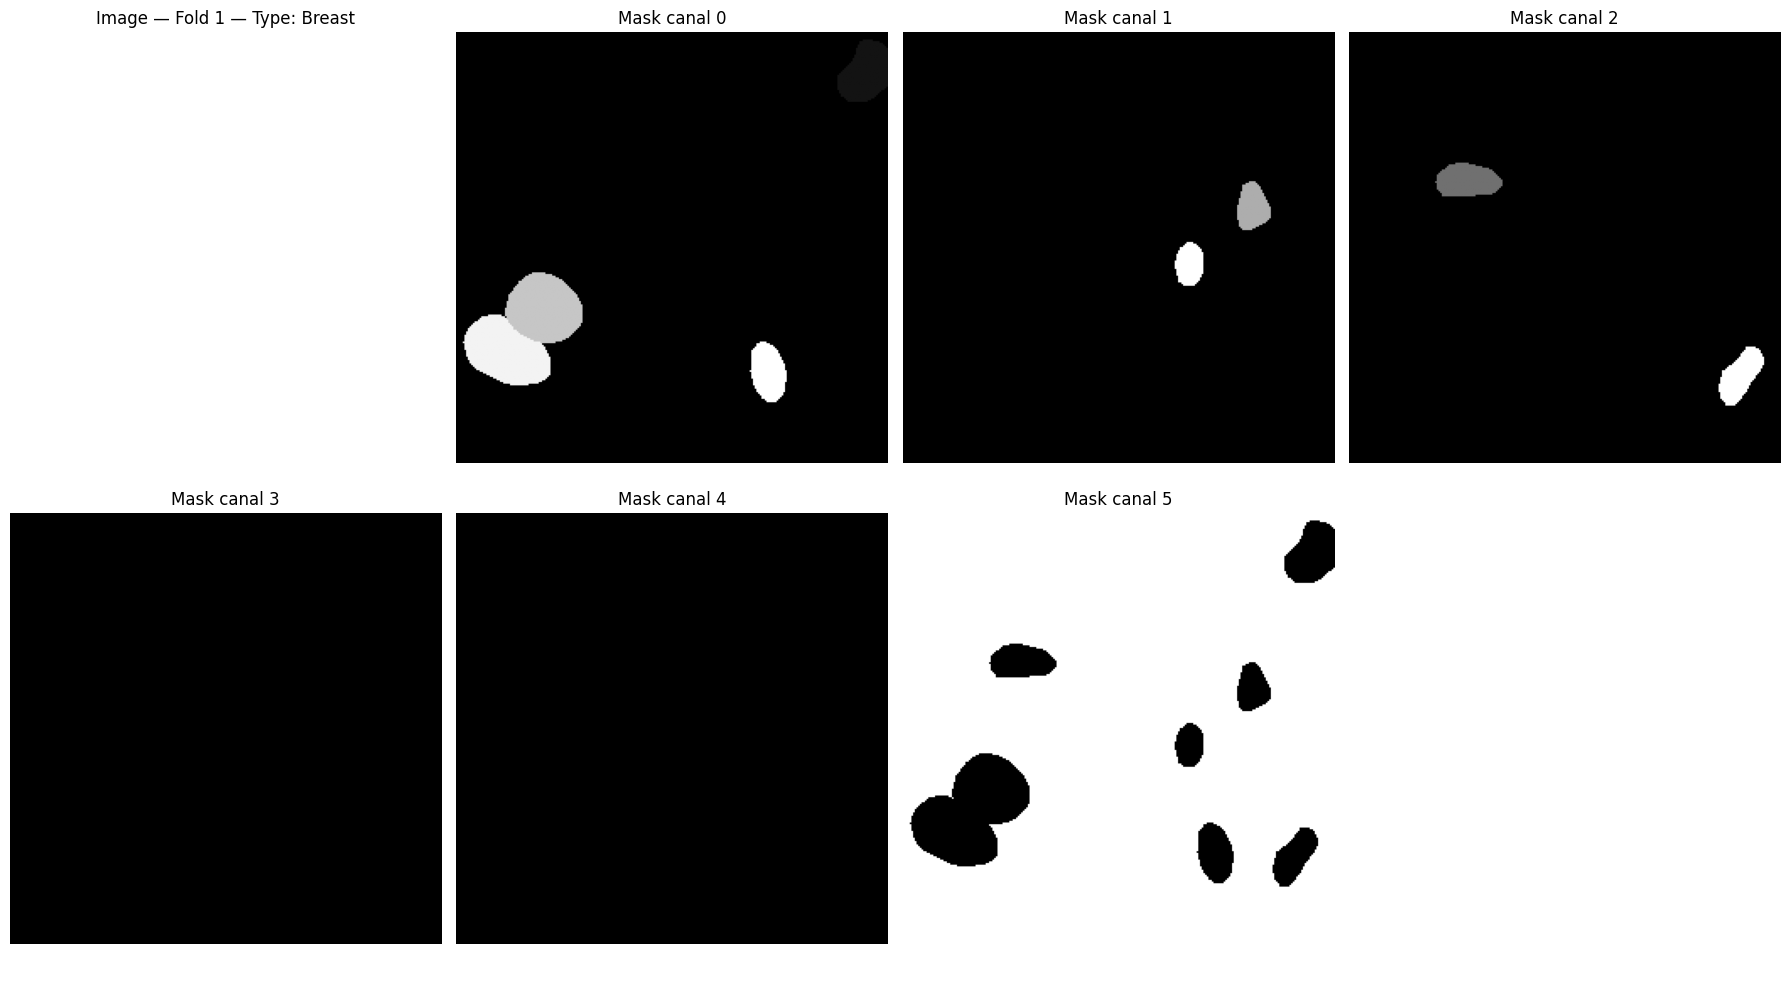


💾 Figure sauvegardée : /kaggle/working/pannuke_output/figures/cell02_mask_channels_example.png

💾 STATISTIQUES SAUVEGARDÉES
✓ /kaggle/working/pannuke_output/pannuke_type_distribution.csv
✓ /kaggle/working/pannuke_output/pannuke_mask_channel_summary.csv
✓ /kaggle/working/pannuke_output/pannuke_nuclei_sample_statistics.csv

🎯 RÉSUMÉ CELL 02
📊 Images totales : 7,901
📦 Nombre de folds : 3
🖼️ Taille image : (256, 256)
🎭 Masques : (256, 256, 6)
🏷️ Types uniques : 19
✅ Structure image/mask/type vérifiée
✅ Inspection des canaux terminée
✅ Analyse instance segmentation terminée
✅ Exemple visuel généré

➡️ PROCHAINE ÉTAPE : CELL 03
   Visualisation avancée des images, noyaux et types cellulaires.

⏱️ Durée Cell 02 : 0.04 minutes

🏁 CELL 02 TERMINÉE


In [4]:
# ============================================================================
# 🧪 CELL 02 — INSPECTION COMPLÈTE DU DATASET PANNUKE
# ============================================================================
#
# Objectifs :
#   1. Vérifier la structure réelle de images.npy
#   2. Vérifier la structure réelle de masks.npy
#   3. Identifier le rôle des 6 canaux
#   4. Vérifier types.npy
#   5. Mesurer la distribution des types
#   6. Vérifier les valeurs des images
#   7. Vérifier les valeurs des masques
#   8. Vérifier les correspondances image / mask / type
#
# IMPORTANT :
#   Aucun entraînement dans cette cellule.
# ============================================================================

import os
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("=" * 80)
print("🧪 CELL 02 — INSPECTION COMPLÈTE PANNUKE")
print("=" * 80)

START_TIME = time.time()


# ============================================================================
# 1. CONFIGURATION
# ============================================================================

FOLD_PATHS = {
    1: {
        "images": FOLD1_IMAGES_PATH,
        "masks": FOLD1_MASKS_PATH,
        "types": FOLD1_TYPES_PATH,
    },
    2: {
        "images": FOLD2_IMAGES_PATH,
        "masks": FOLD2_MASKS_PATH,
        "types": FOLD2_TYPES_PATH,
    },
    3: {
        "images": FOLD3_IMAGES_PATH,
        "masks": FOLD3_MASKS_PATH,
        "types": FOLD3_TYPES_PATH,
    },
}


# ============================================================================
# 2. CHARGEMENT MEMMAP
# ============================================================================

print("\n" + "=" * 80)
print("📦 CHARGEMENT EN MODE MEMMAP")
print("=" * 80)

fold_data = {}

for fold_id, paths in FOLD_PATHS.items():

    print(f"\n🔹 FOLD {fold_id}")

    images = np.load(
        paths["images"],
        mmap_mode="r"
    )

    masks = np.load(
        paths["masks"],
        mmap_mode="r"
    )

    types = np.load(
        paths["types"],
        mmap_mode="r"
    )

    fold_data[fold_id] = {
        "images": images,
        "masks": masks,
        "types": types,
    }

    print(f"✓ Images : {images.shape} | {images.dtype}")
    print(f"✓ Masks  : {masks.shape} | {masks.dtype}")
    print(f"✓ Types  : {types.shape} | {types.dtype}")


# ============================================================================
# 3. VÉRIFICATION DES CORRESPONDANCES
# ============================================================================

print("\n" + "=" * 80)
print("🔗 VÉRIFICATION IMAGE / MASK / TYPE")
print("=" * 80)

for fold_id, data in fold_data.items():

    n_images = data["images"].shape[0]
    n_masks = data["masks"].shape[0]
    n_types = data["types"].shape[0]

    print(f"\nFold {fold_id}")

    print(f"Images : {n_images}")
    print(f"Masks  : {n_masks}")
    print(f"Types  : {n_types}")

    if n_images == n_masks == n_types:
        print("✅ Correspondance parfaite")
    else:
        print("❌ PROBLÈME DE CORRESPONDANCE")


# ============================================================================
# 4. NOMBRE TOTAL D'IMAGES
# ============================================================================

total_images = sum(
    data["images"].shape[0]
    for data in fold_data.values()
)

print("\n" + "=" * 80)
print("📊 NOMBRE TOTAL D'IMAGES")
print("=" * 80)

print(f"Fold 1 : {fold_data[1]['images'].shape[0]:,}")
print(f"Fold 2 : {fold_data[2]['images'].shape[0]:,}")
print(f"Fold 3 : {fold_data[3]['images'].shape[0]:,}")

print("-" * 40)
print(f"TOTAL  : {total_images:,}")


# ============================================================================
# 5. INSPECTION DES TYPES
# ============================================================================

print("\n" + "=" * 80)
print("🔬 INSPECTION DE types.npy")
print("=" * 80)

all_types = []

for fold_id, data in fold_data.items():

    types = np.asarray(data["types"])

    unique_types, counts = np.unique(
        types,
        return_counts=True
    )

    print(f"\n📦 Fold {fold_id}")

    for type_name, count in zip(unique_types, counts):

        print(
            f"   {str(type_name):<20} : {count:,}"
        )

    all_types.extend(types.tolist())


# ============================================================================
# 6. DISTRIBUTION GLOBALE DES TYPES
# ============================================================================

print("\n" + "=" * 80)
print("📊 DISTRIBUTION GLOBALE DES TYPES")
print("=" * 80)

all_types_array = np.asarray(all_types)

global_types, global_counts = np.unique(
    all_types_array,
    return_counts=True
)

type_distribution_df = pd.DataFrame({
    "type": global_types,
    "images": global_counts,
})

type_distribution_df["percentage"] = (
    type_distribution_df["images"]
    / type_distribution_df["images"].sum()
    * 100
)

print(
    type_distribution_df.to_string(
        index=False
    )
)


# ============================================================================
# 7. INSPECTION DES IMAGES
# ============================================================================

print("\n" + "=" * 80)
print("🖼️ INSPECTION DES IMAGES")
print("=" * 80)

# On prend quelques images seulement
# pour éviter de charger tout le dataset.

for fold_id, data in fold_data.items():

    images = data["images"]

    print(f"\n📦 Fold {fold_id}")

    for index in [0, min(1, len(images)-1)]:

        image = np.asarray(images[index])

        print(f"\nImage {index}")

        print(f"Shape : {image.shape}")
        print(f"Dtype : {image.dtype}")
        print(f"Min   : {image.min():.4f}")
        print(f"Max   : {image.max():.4f}")
        print(f"Mean  : {image.mean():.4f}")
        print(f"Std   : {image.std():.4f}")

        print(
            f"Type  : {data['types'][index]}"
        )


# ============================================================================
# 8. INSPECTION APPROFONDIE DES MASQUES
# ============================================================================

print("\n" + "=" * 80)
print("🎭 INSPECTION DES MASQUES")
print("=" * 80)

# On inspecte plusieurs images de chaque fold.

MASK_CHANNEL_STATS = []

for fold_id, data in fold_data.items():

    masks = data["masks"]

    print(f"\n{'=' * 60}")
    print(f"📦 FOLD {fold_id}")
    print(f"{'=' * 60}")

    sample_indices = [
        0,
        len(masks) // 2,
        len(masks) - 1
    ]

    sample_indices = sorted(
        set(
            i for i in sample_indices
            if 0 <= i < len(masks)
        )
    )

    for index in sample_indices:

        mask = np.asarray(
            masks[index]
        )

        print(f"\n🧩 Mask image {index}")
        print(f"Shape : {mask.shape}")
        print(f"Dtype : {mask.dtype}")

        for channel in range(mask.shape[-1]):

            channel_data = mask[..., channel]

            unique_values = np.unique(
                channel_data
            )

            non_zero = np.count_nonzero(
                channel_data
            )

            print(
                f"\n   Canal {channel}"
            )

            print(
                f"   Min       : {channel_data.min()}"
            )

            print(
                f"   Max       : {channel_data.max()}"
            )

            print(
                f"   Non-zero  : {non_zero:,}"
            )

            print(
                f"   Unique    : "
                f"{len(unique_values):,}"
            )

            # Afficher uniquement quelques valeurs
            if len(unique_values) <= 20:

                print(
                    f"   Valeurs   : "
                    f"{unique_values}"
                )

            else:

                print(
                    f"   Valeurs   : "
                    f"{unique_values[:10]} ..."
                )


# ============================================================================
# 9. ANALYSE DES CANAUX DU MASQUE
# ============================================================================

print("\n" + "=" * 80)
print("🔎 ANALYSE DES 6 CANAUX")
print("=" * 80)

CHANNEL_COUNT = 6

channel_summary = []

for channel in range(CHANNEL_COUNT):

    print(
        f"\n🟦 CANAL {channel}"
    )

    max_values = []
    nonzero_pixels = []
    unique_counts = []

    for fold_id, data in fold_data.items():

        masks = data["masks"]

        # Quelques échantillons seulement
        indices = np.linspace(
            0,
            len(masks) - 1,
            num=min(10, len(masks)),
            dtype=int
        )

        for index in indices:

            channel_data = np.asarray(
                masks[index, :, :, channel]
            )

            max_values.append(
                float(channel_data.max())
            )

            nonzero_pixels.append(
                int(np.count_nonzero(channel_data))
            )

            unique_counts.append(
                len(np.unique(channel_data))
            )

    channel_summary.append({
        "channel": channel,
        "max_observed": max(max_values),
        "mean_nonzero_pixels":
            np.mean(nonzero_pixels),
        "max_unique_values":
            max(unique_counts),
    })

    print(
        f"   Max observé        : "
        f"{max(max_values)}"
    )

    print(
        f"   Pixels non-zero moy: "
        f"{np.mean(nonzero_pixels):,.1f}"
    )

    print(
        f"   Max valeurs uniques: "
        f"{max(unique_counts)}"
    )


channel_summary_df = pd.DataFrame(
    channel_summary
)

print("\n")
print(
    channel_summary_df.to_string(
        index=False
    )
)


# ============================================================================
# 10. DÉTECTION D'UNE ÉVENTUELLE INSTANCE MAP
# ============================================================================

print("\n" + "=" * 80)
print("🧬 ANALYSE INSTANCE SEGMENTATION")
print("=" * 80)

print(
    "On vérifie si un canal contient "
    "plusieurs identifiants de noyaux."
)

for fold_id, data in fold_data.items():

    masks = data["masks"]

    index = 0

    mask = np.asarray(
        masks[index]
    )

    print(f"\n📦 Fold {fold_id}")

    for channel in range(mask.shape[-1]):

        channel_data = mask[..., channel]

        unique_values = np.unique(
            channel_data
        )

        print(
            f"Canal {channel} : "
            f"{len(unique_values):,} valeurs uniques | "
            f"max={channel_data.max()}"
        )


# ============================================================================
# 11. NOMBRE APPROXIMATIF DE NOYAUX
# ============================================================================

print("\n" + "=" * 80)
print("🔬 ESTIMATION DU NOMBRE DE NOYAUX")
print("=" * 80)

print(
    "Analyse sur un échantillon de 30 images par fold."
)

nuclei_statistics = []

for fold_id, data in fold_data.items():

    masks = data["masks"]

    sample_count = min(
        30,
        len(masks)
    )

    indices = np.linspace(
        0,
        len(masks) - 1,
        sample_count,
        dtype=int
    )

    for index in indices:

        mask = np.asarray(
            masks[index]
        )

        # Pour l'instant, nous ne supposons PAS
        # quel canal correspond aux instances.
        #
        # On cherche automatiquement le canal
        # qui possède le plus grand nombre de
        # valeurs uniques significatives.

        channel_unique_counts = []

        for channel in range(mask.shape[-1]):

            values = np.unique(
                mask[..., channel]
            )

            channel_unique_counts.append(
                len(values)
            )

        candidate_channel = int(
            np.argmax(
                channel_unique_counts
            )
        )

        candidate_data = mask[
            ...,
            candidate_channel
        ]

        unique_values = np.unique(
            candidate_data
        )

        # Si les valeurs sont des identifiants
        # d'instances, le nombre de valeurs > 1
        # donne une première estimation.

        estimated_instances = max(
            0,
            len(unique_values) - 1
        )

        nuclei_statistics.append({
            "fold": fold_id,
            "image_index": int(index),
            "candidate_channel":
                candidate_channel,
            "unique_values":
                len(unique_values),
            "estimated_instances":
                estimated_instances,
        })


nuclei_df = pd.DataFrame(
    nuclei_statistics
)

print(
    nuclei_df.head(15).to_string(
        index=False
    )
)

print("\n📊 Résumé :")

print(
    nuclei_df[
        "estimated_instances"
    ].describe()
)


# ============================================================================
# 12. VÉRIFICATION DES MASQUES VIDES
# ============================================================================

print("\n" + "=" * 80)
print("⚠️ DÉTECTION DES MASQUES VIDES")
print("=" * 80)

for fold_id, data in fold_data.items():

    masks = data["masks"]

    sample_count = min(
        100,
        len(masks)
    )

    indices = np.linspace(
        0,
        len(masks) - 1,
        sample_count,
        dtype=int
    )

    empty_count = 0

    for index in indices:

        mask = np.asarray(
            masks[index]
        )

        if np.count_nonzero(mask) == 0:
            empty_count += 1

    print(
        f"Fold {fold_id} : "
        f"{empty_count}/{sample_count} "
        f"masques entièrement vides"
    )


# ============================================================================
# 13. VISUALISATION D'UN PREMIER EXEMPLE
# ============================================================================

print("\n" + "=" * 80)
print("🖼️ VISUALISATION D'UN EXEMPLE")
print("=" * 80)

fold_id = 1
index = 0

image = np.asarray(
    fold_data[fold_id]["images"][index]
)

mask = np.asarray(
    fold_data[fold_id]["masks"][index]
)

sample_type = fold_data[
    fold_id
]["types"][index]

print(f"Fold       : {fold_id}")
print(f"Image      : {image.shape}")
print(f"Mask       : {mask.shape}")
print(f"Type       : {sample_type}")


# ---------------------------------------------------------------------------
# Image + six canaux
# ---------------------------------------------------------------------------

fig, axes = plt.subplots(
    2,
    4,
    figsize=(18, 10)
)

axes = axes.ravel()

axes[0].imshow(
    image.astype(np.float32)
)
axes[0].set_title(
    f"Image — Fold {fold_id} — "
    f"Type: {sample_type}"
)
axes[0].axis("off")


for channel in range(6):

    axes[channel + 1].imshow(
        mask[..., channel],
        cmap="gray"
    )

    axes[channel + 1].set_title(
        f"Mask canal {channel}"
    )

    axes[channel + 1].axis("off")


# Dernière case vide
axes[7].axis("off")

plt.tight_layout()

example_path = (
    FIGURES_DIR /
    "cell02_mask_channels_example.png"
)

plt.savefig(
    example_path,
    dpi=150,
    bbox_inches="tight"
)

plt.show()

print(
    f"\n💾 Figure sauvegardée : "
    f"{example_path}"
)


# ============================================================================
# 14. SAUVEGARDE DES STATISTIQUES
# ============================================================================

type_distribution_path = (
    OUTPUT_DIR /
    "pannuke_type_distribution.csv"
)

type_distribution_df.to_csv(
    type_distribution_path,
    index=False
)

channel_summary_path = (
    OUTPUT_DIR /
    "pannuke_mask_channel_summary.csv"
)

channel_summary_df.to_csv(
    channel_summary_path,
    index=False
)

nuclei_statistics_path = (
    OUTPUT_DIR /
    "pannuke_nuclei_sample_statistics.csv"
)

nuclei_df.to_csv(
    nuclei_statistics_path,
    index=False
)

print("\n" + "=" * 80)
print("💾 STATISTIQUES SAUVEGARDÉES")
print("=" * 80)

print(
    f"✓ {type_distribution_path}"
)

print(
    f"✓ {channel_summary_path}"
)

print(
    f"✓ {nuclei_statistics_path}"
)


# ============================================================================
# 15. VARIABLES PRÉPARÉES
# ============================================================================

PANNUKE_FOLD_DATA = fold_data

PANNUKE_TYPE_DISTRIBUTION = (
    type_distribution_df
)

PANNUKE_CHANNEL_SUMMARY = (
    channel_summary_df
)

PANNUKE_NUCLEI_STATISTICS = (
    nuclei_df
)


# ============================================================================
# 16. RÉSUMÉ FINAL
# ============================================================================

print("\n" + "=" * 80)
print("🎯 RÉSUMÉ CELL 02")
print("=" * 80)

print(
    f"📊 Images totales : "
    f"{total_images:,}"
)

print(
    f"📦 Nombre de folds : "
    f"{len(fold_data)}"
)

print(
    f"🖼️ Taille image : "
    f"{IMAGE_SIZE}"
)

print(
    "🎭 Masques : "
    "(256, 256, 6)"
)

print(
    f"🏷️ Types uniques : "
    f"{len(global_types)}"
)

print(
    "✅ Structure image/mask/type vérifiée"
)

print(
    "✅ Inspection des canaux terminée"
)

print(
    "✅ Analyse instance segmentation terminée"
)

print(
    "✅ Exemple visuel généré"
)

print(
    "\n➡️ PROCHAINE ÉTAPE : CELL 03"
)

print(
    "   Visualisation avancée des images, "
    "noyaux et types cellulaires."
)

print(
    f"\n⏱️ Durée Cell 02 : "
    f"{(time.time() - START_TIME) / 60:.2f} minutes"
)

print("\n" + "=" * 80)
print("🏁 CELL 02 TERMINÉE")
print("=" * 80)

🧪 CELL 03 — VISUALISATION AVANCÉE PANNUKE
Classes PanNuke :
   [0] neoplastic
   [1] inflammatory
   [2] connective
   [3] dead
   [4] epithelial
   [5] background


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [1.0..255.0].



🖼️ ÉCHANTILLONS SÉLECTIONNÉS
Fold 1 | Image 178 | Type : Breast | Classes présentes : 4
Fold 1 | Image 198 | Type : Breast | Classes présentes : 4
Fold 2 | Image 70 | Type : Breast | Classes présentes : 4

📦 EXEMPLE 1 | Fold 1 | Image 178
Type tissu : Breast

Instances détectées :
   neoplastic      : 0
   inflammatory    : 1
   connective      : 2
   dead            : 1
   epithelial      : 36

Chevauchements détectés : 0


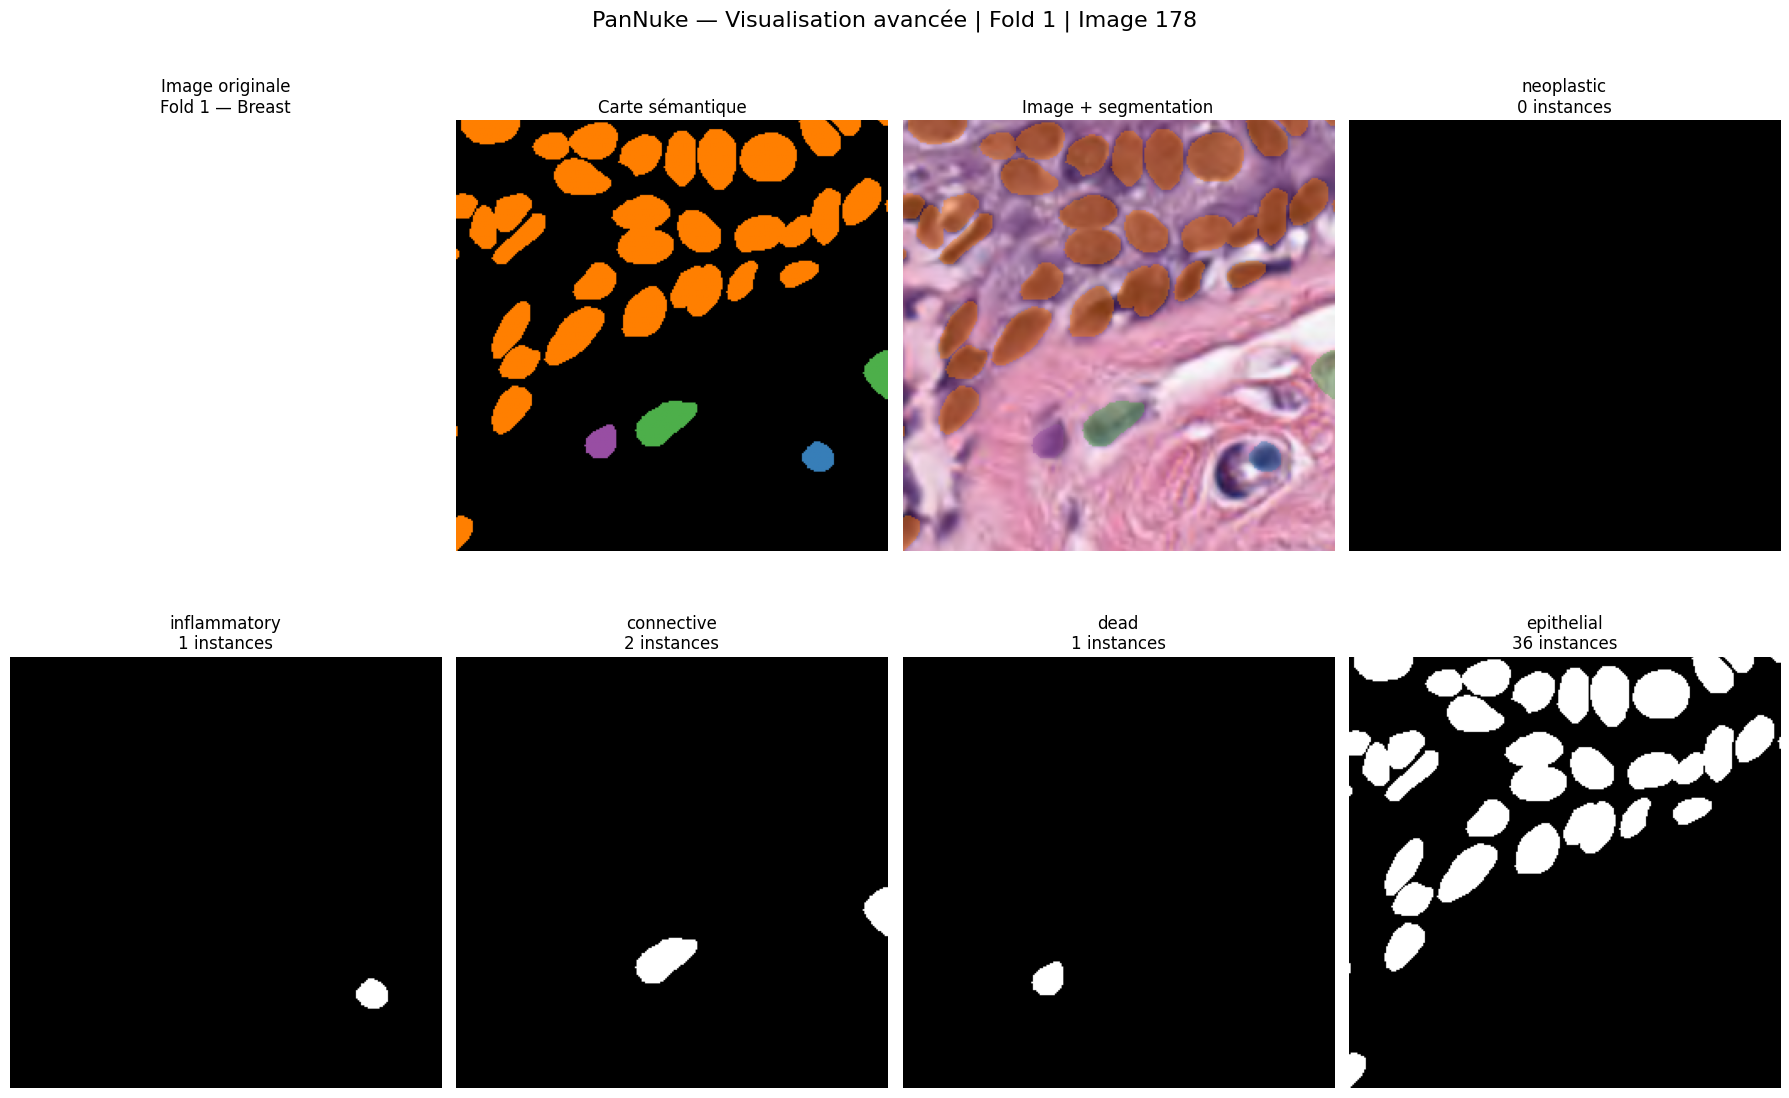

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [31.0..255.0].


💾 Figure sauvegardée : /kaggle/working/pannuke_output/figures/cell03_visualization_fold1_image178.png

📦 EXEMPLE 2 | Fold 1 | Image 198
Type tissu : Breast

Instances détectées :
   neoplastic      : 8
   inflammatory    : 1
   connective      : 3
   dead            : 0
   epithelial      : 1

Chevauchements détectés : 0


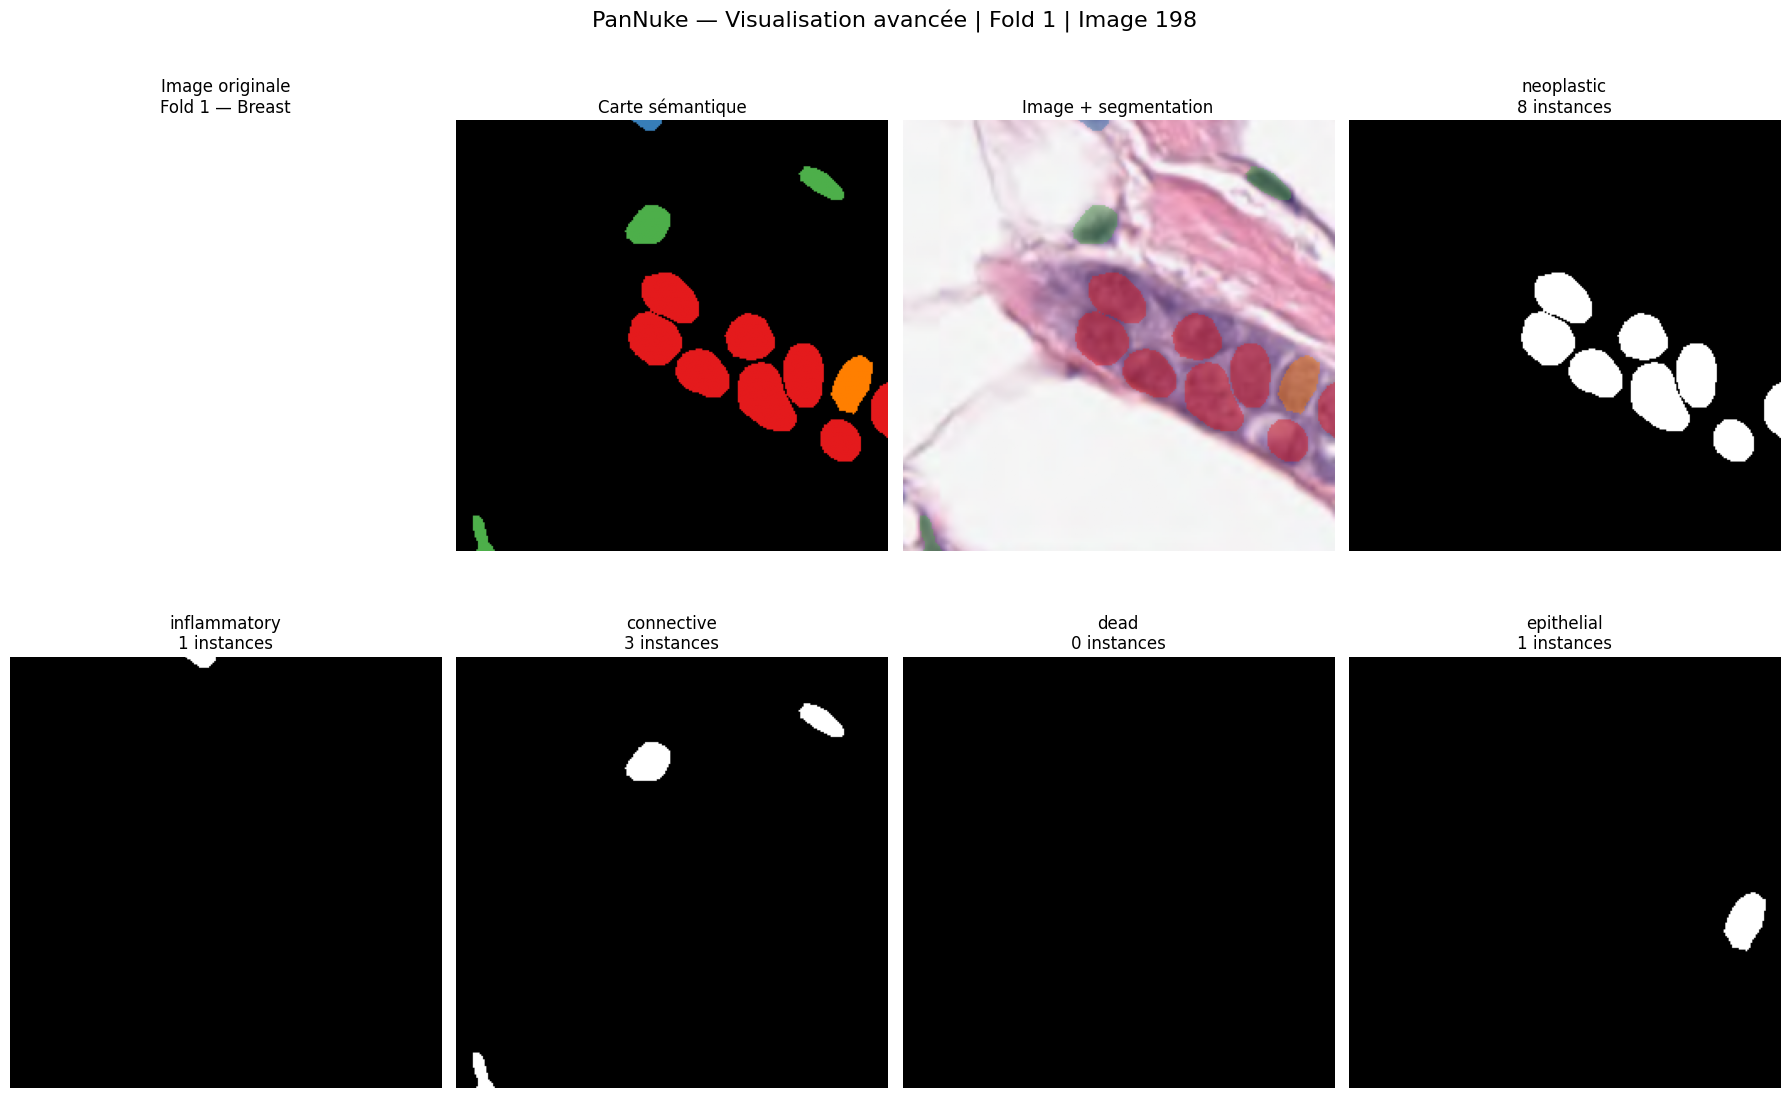

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [23.0..255.0].


💾 Figure sauvegardée : /kaggle/working/pannuke_output/figures/cell03_visualization_fold1_image198.png

📦 EXEMPLE 3 | Fold 2 | Image 70
Type tissu : Breast

Instances détectées :
   neoplastic      : 1
   inflammatory    : 1
   connective      : 6
   dead            : 0
   epithelial      : 9

Chevauchements détectés : 0


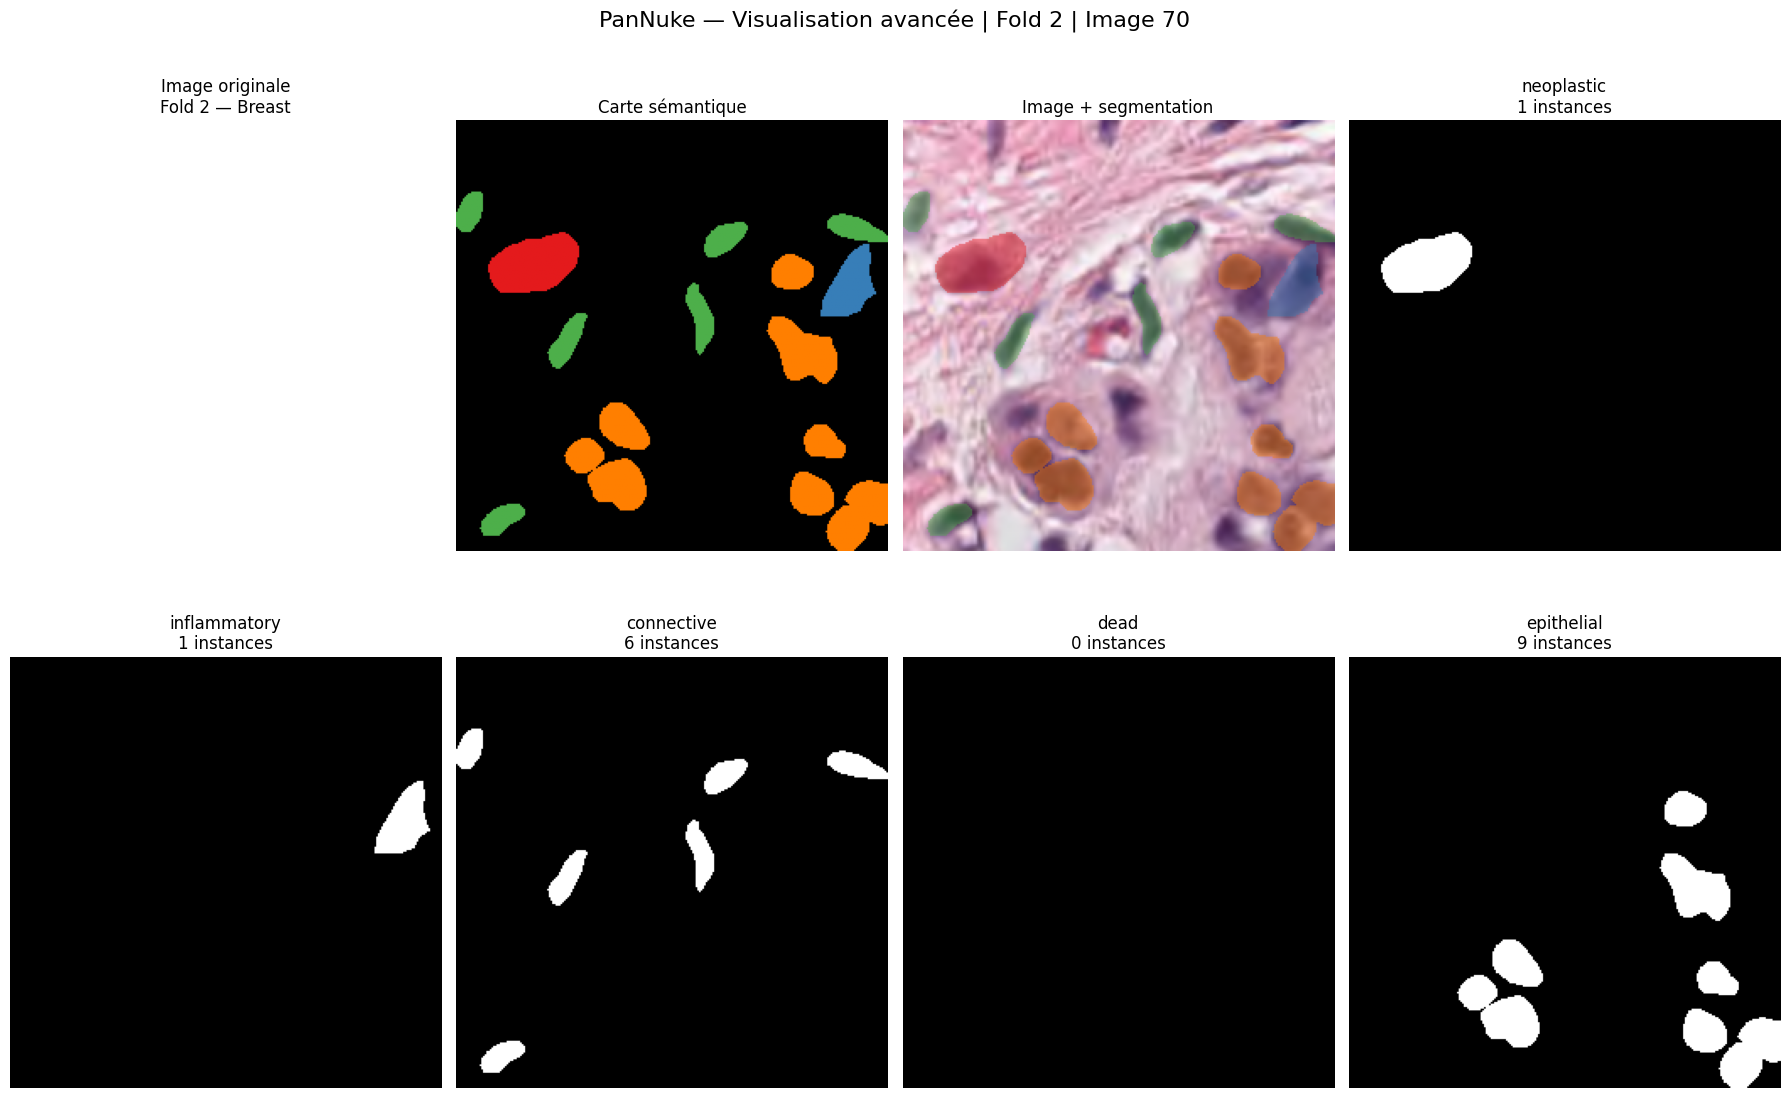

💾 Figure sauvegardée : /kaggle/working/pannuke_output/figures/cell03_visualization_fold2_image70.png

🎯 RÉSUMÉ CELL 03
✅ Images originales visualisées
✅ Carte sémantique générée temporairement
✅ Instances par classe analysées
✅ Overlay image + segmentation généré
✅ 5 classes cellulaires inspectées
✅ IDs d'instances originaux conservés
✅ Figures sauvegardées

➡️ PROCHAINE ÉTAPE : CELL 04
   Analyse quantitative des masques et distribution des noyaux.

🏁 CELL 03 TERMINÉE


In [5]:
# ============================================================================
# 🧪 CELL 03 — VISUALISATION AVANCÉE PANNUKE
# ============================================================================
#
# Objectifs :
#   1. Visualiser plusieurs images PanNuke
#   2. Visualiser les instances de noyaux
#   3. Construire temporairement une carte sémantique
#   4. Afficher les classes cellulaires avec couleurs
#   5. Afficher un overlay image + segmentation
#
# IMPORTANT :
#   Les masks.npy contiennent des IDs d'instances.
#   On conserve les IDs originaux.
# ============================================================================

import os
import numpy as np
import matplotlib.pyplot as plt

from matplotlib.colors import ListedColormap

print("=" * 80)
print("🧪 CELL 03 — VISUALISATION AVANCÉE PANNUKE")
print("=" * 80)


# ============================================================================
# 1. CONFIGURATION
# ============================================================================

CLASS_NAMES = [
    "neoplastic",
    "inflammatory",
    "connective",
    "dead",
    "epithelial",
    "background"
]

CELL_COLORS = [
    "#e41a1c",   # neoplastic
    "#377eb8",   # inflammatory
    "#4daf4a",   # connective
    "#984ea3",   # dead
    "#ff7f00",   # epithelial
    "#000000"    # background
]

# Les 5 premières classes correspondent aux canaux d'instances.
INSTANCE_CHANNELS = 5

print("Classes PanNuke :")
for i, name in enumerate(CLASS_NAMES):
    print(f"   [{i}] {name}")


# ============================================================================
# 2. FONCTIONS UTILITAIRES
# ============================================================================

def load_sample(fold_id, image_index):
    """
    Charge une seule image et son masque depuis un fold.
    """

    paths = FOLD_PATHS[fold_id]

    image = np.load(
        paths["images"],
        mmap_mode="r"
    )[image_index]

    mask = np.load(
        paths["masks"],
        mmap_mode="r"
    )[image_index]

    tissue_type = np.load(
        paths["types"],
        mmap_mode="r"
    )[image_index]

    return image, mask, str(tissue_type)


def build_semantic_map(instance_mask):
    """
    Transforme temporairement les 5 canaux d'instances
    en carte sémantique :

        0 = background
        1 = neoplastic
        2 = inflammatory
        3 = connective
        4 = dead
        5 = epithelial

    Les IDs d'instances originaux restent dans instance_mask.
    """

    h, w, c = instance_mask.shape

    semantic = np.zeros(
        (h, w),
        dtype=np.uint8
    )

    overlap_count = 0

    for class_id in range(INSTANCE_CHANNELS):

        channel = instance_mask[:, :, class_id]

        pixels = channel > 0

        # Détection d'éventuels chevauchements
        overlap_count += np.sum(
            pixels & (semantic != 0)
        )

        semantic[pixels & (semantic == 0)] = class_id + 1

    return semantic, int(overlap_count)


def count_instances(instance_mask):
    """
    Compte les instances présentes dans chaque classe.
    """

    counts = {}

    for class_id in range(INSTANCE_CHANNELS):

        channel = instance_mask[:, :, class_id]

        unique_ids = np.unique(channel)

        # 0 = background
        instance_ids = unique_ids[unique_ids > 0]

        counts[CLASS_NAMES[class_id]] = len(instance_ids)

    return counts


def create_overlay(image, semantic_map, alpha=0.45):
    """
    Crée un overlay RGB entre l'image et la segmentation.
    """

    # Image en float [0,1]
    img = image.astype(np.float32)

    if img.max() > 1.0:
        img = img / 255.0

    img = np.clip(img, 0, 1)

    # Couleurs des classes
    colors = np.array([
        [0.0, 0.0, 0.0],   # background
        [0.894, 0.102, 0.110],  # neoplastic
        [0.216, 0.494, 0.722],  # inflammatory
        [0.302, 0.686, 0.290],  # connective
        [0.596, 0.306, 0.639],  # dead
        [1.000, 0.498, 0.000],  # epithelial
    ], dtype=np.float32)

    mask_rgb = colors[semantic_map]

    overlay = img.copy()

    foreground = semantic_map > 0

    overlay[foreground] = (
        (1 - alpha) * img[foreground]
        + alpha * mask_rgb[foreground]
    )

    return np.clip(overlay, 0, 1)


# ============================================================================
# 3. SÉLECTION D'IMAGES INTÉRESSANTES
# ============================================================================

# On choisit des images contenant plusieurs types de noyaux.
sample_candidates = []

for fold_id in [1, 2, 3]:

    paths = FOLD_PATHS[fold_id]

    masks = np.load(
        paths["masks"],
        mmap_mode="r"
    )

    types = np.load(
        paths["types"],
        mmap_mode="r"
    )

    # Recherche sur un petit échantillon
    max_search = min(200, len(masks))

    for idx in range(max_search):

        mask = masks[idx]

        present_classes = np.sum(
            np.any(mask[:, :, :5] > 0, axis=(0, 1))
        )

        if present_classes >= 2:
            sample_candidates.append(
                (fold_id, idx, str(types[idx]), present_classes)
            )


# Sélection de quelques exemples
sample_candidates = sorted(
    sample_candidates,
    key=lambda x: -x[3]
)

selected_samples = sample_candidates[:3]

print("\n" + "=" * 80)
print("🖼️ ÉCHANTILLONS SÉLECTIONNÉS")
print("=" * 80)

for fold_id, idx, tissue_type, n_classes in selected_samples:
    print(
        f"Fold {fold_id} | "
        f"Image {idx} | "
        f"Type : {tissue_type} | "
        f"Classes présentes : {n_classes}"
    )


# ============================================================================
# 4. VISUALISATION PRINCIPALE
# ============================================================================

for sample_number, (
    fold_id,
    image_index,
    tissue_type,
    _
) in enumerate(selected_samples, start=1):

    image, mask, tissue_type = load_sample(
        fold_id,
        image_index
    )

    image = np.asarray(image)
    mask = np.asarray(mask)

    semantic_map, overlap_count = build_semantic_map(mask)

    instance_counts = count_instances(mask)

    overlay = create_overlay(
        image,
        semantic_map,
        alpha=0.45
    )

    print("\n" + "=" * 80)
    print(
        f"📦 EXEMPLE {sample_number} "
        f"| Fold {fold_id} "
        f"| Image {image_index}"
    )
    print("=" * 80)

    print(f"Type tissu : {tissue_type}")

    print("\nInstances détectées :")

    for class_name, count in instance_counts.items():
        print(
            f"   {class_name:<15} : {count}"
        )

    print(
        f"\nChevauchements détectés : "
        f"{overlap_count}"
    )

    # ------------------------------------------------------------------------
    # Figure
    # ------------------------------------------------------------------------

    fig = plt.figure(
        figsize=(18, 12)
    )

    # ------------------------------------------------------------------------
    # Image originale
    # ------------------------------------------------------------------------

    ax = plt.subplot(2, 4, 1)

    ax.imshow(
        image,
        vmin=0,
        vmax=255
    )

    ax.set_title(
        f"Image originale\n"
        f"Fold {fold_id} — {tissue_type}"
    )

    ax.axis("off")

    # ------------------------------------------------------------------------
    # Semantic map
    # ------------------------------------------------------------------------

    ax = plt.subplot(2, 4, 2)

    semantic_cmap = ListedColormap(
        [
            "#000000",
            "#e41a1c",
            "#377eb8",
            "#4daf4a",
            "#984ea3",
            "#ff7f00"
        ]
    )

    ax.imshow(
        semantic_map,
        cmap=semantic_cmap,
        vmin=0,
        vmax=5
    )

    ax.set_title(
        "Carte sémantique"
    )

    ax.axis("off")

    # ------------------------------------------------------------------------
    # Overlay
    # ------------------------------------------------------------------------

    ax = plt.subplot(2, 4, 3)

    ax.imshow(overlay)

    ax.set_title(
        "Image + segmentation"
    )

    ax.axis("off")

    # ------------------------------------------------------------------------
    # Classes individuelles
    # ------------------------------------------------------------------------

    for class_id in range(5):

        ax = plt.subplot(
            2,
            4,
            class_id + 4
        )

        channel = mask[:, :, class_id]

        binary_mask = channel > 0

        # Affichage binaire pour visualisation
        ax.imshow(
            binary_mask,
            cmap="gray"
        )

        n_instances = np.sum(
            np.unique(channel) > 0
        )

        ax.set_title(
            f"{CLASS_NAMES[class_id]}\n"
            f"{n_instances} instances"
        )

        ax.axis("off")

    plt.suptitle(
        f"PanNuke — Visualisation avancée "
        f"| Fold {fold_id} | Image {image_index}",
        fontsize=16
    )

    plt.tight_layout()

    # ------------------------------------------------------------------------
    # Sauvegarde
    # ------------------------------------------------------------------------

    output_path = os.path.join(
        FIGURES_DIR,
        f"cell03_visualization_fold{fold_id}_image{image_index}.png"
    )

    plt.savefig(
        output_path,
        dpi=150,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

    print(
        f"💾 Figure sauvegardée : {output_path}"
    )


# ============================================================================
# 5. RÉSUMÉ
# ============================================================================

print("\n" + "=" * 80)
print("🎯 RÉSUMÉ CELL 03")
print("=" * 80)

print("✅ Images originales visualisées")
print("✅ Carte sémantique générée temporairement")
print("✅ Instances par classe analysées")
print("✅ Overlay image + segmentation généré")
print("✅ 5 classes cellulaires inspectées")
print("✅ IDs d'instances originaux conservés")
print("✅ Figures sauvegardées")

print("\n➡️ PROCHAINE ÉTAPE : CELL 04")
print("   Analyse quantitative des masques et distribution des noyaux.")

print("\n" + "=" * 80)
print("🏁 CELL 03 TERMINÉE")
print("=" * 80)

🧪 CELL 04 — ANALYSE QUANTITATIVE DES MASQUES PANNUKE
📁 CSV       : /kaggle/working/pannuke_output/quantitative_analysis
📁 Figures   : /kaggle/working/pannuke_output/figures

📦 ANALYSE FOLD 1
🖼️ Images : (2656, 256, 256, 3)
🎭 Masks  : (2656, 256, 256, 6)
🏷️ Types  : (2656,)
   Progression : 500/2,656 (18.8%)
   Progression : 1,000/2,656 (37.7%)
   Progression : 1,500/2,656 (56.5%)
   Progression : 2,000/2,656 (75.3%)
   Progression : 2,500/2,656 (94.1%)
   Progression : 2,656/2,656 (100.0%)

--------------------------------------------------------------------------------
📊 RÉSUMÉ FOLD 1
--------------------------------------------------------------------------------
🖼️ Nombre images              : 2,656
🧬 Nombre total instances     : 63,218
🎭 Pixels segmentés           : 29,660,790
⚠️ Masques vides              : 116
🔀 Pixels avec chevauchement  : 1,216

📊 Instances par classe :
   neoplastic      : 26,201
   inflammatory    : 10,820
   connective      : 16,388
   dead            : 967


,class,total_instances,mean_instance_area,median_instance_area,min_instance_area,max_instance_area
0,neoplastic,77403,579.448652,500.0,1,8757
1,inflammatory,32276,284.685184,259.0,1,2416
2,connective,50585,382.522823,322.0,1,3816
3,dead,2908,123.116575,99.0,1,996
4,epithelial,26572,482.580875,415.0,1,5076



📦 Résumé par Fold :


,fold,images,total_instances,mean_instances_per_image,median_instances_per_image,std_instances_per_image,mean_segmentation_percentage,median_segmentation_percentage,empty_masks,overlap_pixels
0,1,2656,63218,23.801958,20.0,19.824900,17.040201,16.156006,116,1216
1,2,2523,59872,23.730480,20.0,20.276799,16.140369,15.211487,113,1572
2,3,2722,66654,24.487142,20.0,20.471492,16.941731,15.898132,114,1530



🧬 Distribution des tissus :


,tissue_type,images,percentage
0,Breast,2351,29.755727
1,Colon,1440,18.225541
2,Adrenal_gland,437,5.530945
3,Esophagus,424,5.366409
4,Bile-duct,420,5.315783
5,HeadNeck,384,4.860144
6,Cervix,293,3.708391
7,Thyroid,226,2.860397
8,Liver,224,2.835084
9,Testis,196,2.480699


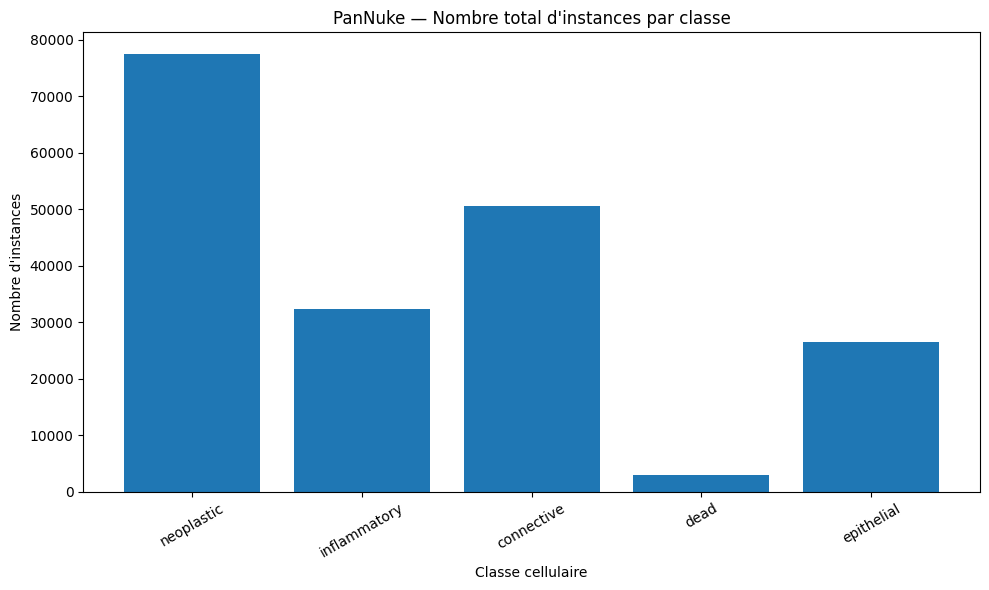

💾 Figure sauvegardée : /kaggle/working/pannuke_output/figures/cell04_instances_per_class.png


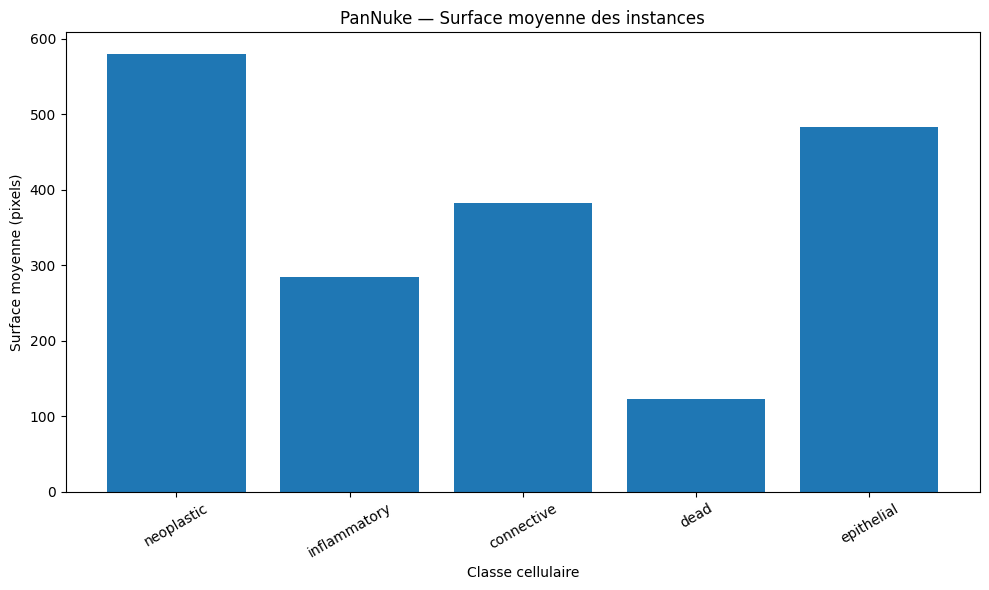

💾 Figure sauvegardée : /kaggle/working/pannuke_output/figures/cell04_mean_instance_area.png


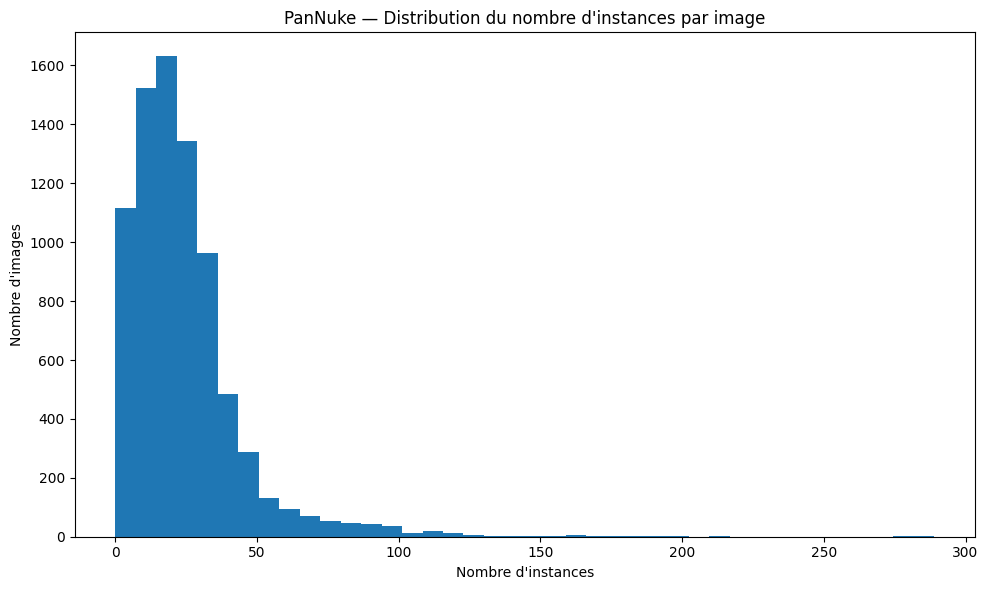

💾 Figure sauvegardée : /kaggle/working/pannuke_output/figures/cell04_instances_distribution.png


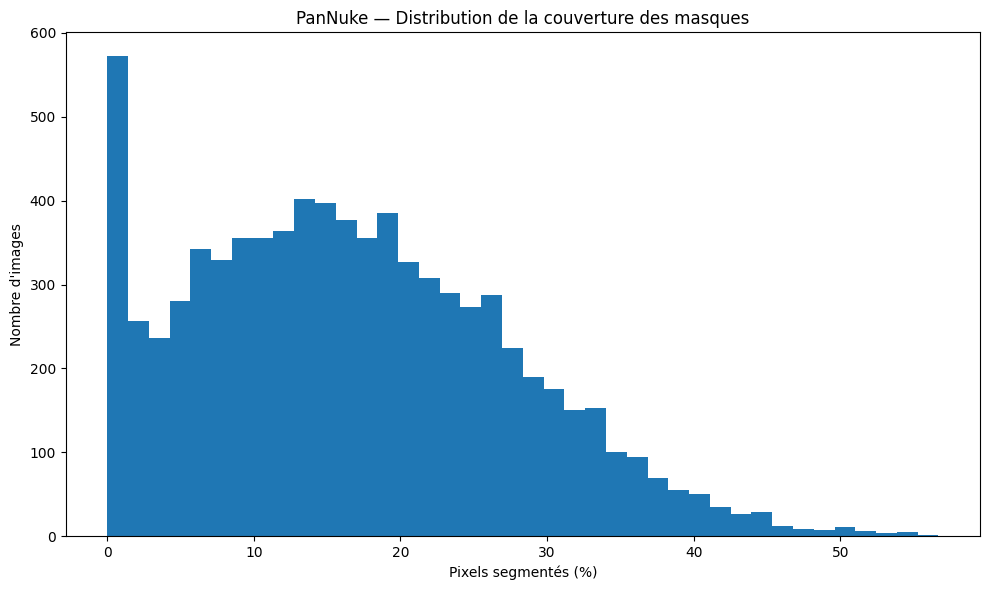

💾 Figure sauvegardée : /kaggle/working/pannuke_output/figures/cell04_segmentation_coverage.png

🏆 TOP 20 — IMAGES AVEC LE PLUS D'INSTANCES


,fold,image_index,tissue_type,total_instances,segmentation_percentage
3588,2,932,Uterus,289,33.264160
1063,1,1063,Uterus,276,32.899475
6184,3,1005,Uterus,214,26.940918
1062,1,1062,Uterus,196,27.928162
1487,1,1487,Colon,189,47.894287
6186,3,1007,Uterus,186,30.369568
1061,1,1061,Uterus,178,23.448181
2610,1,2610,Colon,168,40.055847
5143,2,2487,Colon,167,36.657715
2612,1,2612,Colon,166,40.077209



🏆 TOP 20 — PLUS GRANDES INSTANCES


,fold,image_index,tissue_type,class,instance_id,area_pixels
77386,2,639,Breast,neoplastic,179,8757
71731,2,359,Breast,neoplastic,44,8668
40124,1,1693,Breast,neoplastic,283,8353
49513,1,2159,HeadNeck,neoplastic,384,8325
72185,2,380,Breast,neoplastic,145,6178
10365,1,450,Breast,neoplastic,198,5998
8826,1,363,Breast,neoplastic,193,5968
71619,2,351,Breast,neoplastic,223,5637
135921,3,590,Breast,neoplastic,162,5303
123135,3,4,Breast,neoplastic,21,5143



⚠️ CAS PARTICULIERS
Masques/images sans aucune instance : 343
Images dans le top 1% des instances : 86
Images contenant des chevauchements : 575

🎯 RÉSUMÉ CELL 04
✅ Images analysées          : 7,901
✅ Instances analysées      : 189,744
✅ Classes cellulaires      : 5
✅ Folds analysés            : 3

📊 Classes :
   neoplastic      : 77,403 instances
   inflammatory    : 32,276 instances
   connective      : 50,585 instances
   dead            : 2,908 instances
   epithelial      : 26,572 instances

💾 Fichiers CSV :
   ✓ /kaggle/working/pannuke_output/quantitative_analysis/pannuke_image_quantitative_statistics.csv
   ✓ /kaggle/working/pannuke_output/quantitative_analysis/pannuke_instance_statistics.csv
   ✓ /kaggle/working/pannuke_output/quantitative_analysis/pannuke_class_quantitative_summary.csv
   ✓ /kaggle/working/pannuke_output/quantitative_analysis/pannuke_fold_quantitative_summary.csv
   ✓ /kaggle/working/pannuke_output/quantitative_analysis/pannuke_tissue_distribution.csv

💾 Figu

In [6]:
# =============================================================================
# 🧪 CELL 04 — ANALYSE QUANTITATIVE DES MASQUES PANNUKE
# =============================================================================

import os
import gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

print("=" * 80)
print("🧪 CELL 04 — ANALYSE QUANTITATIVE DES MASQUES PANNUKE")
print("=" * 80)


# =============================================================================
# 1. CONFIGURATION
# =============================================================================

CLASS_NAMES = [
    "neoplastic",
    "inflammatory",
    "connective",
    "dead",
    "epithelial",
    "background"
]

CELL_CLASSES = CLASS_NAMES[:5]

N_CLASSES = 6

# Dossiers de sortie
CSV_DIR = os.path.join(OUTPUT_DIR, "quantitative_analysis")
FIG_DIR = os.path.join(OUTPUT_DIR, "figures")

os.makedirs(CSV_DIR, exist_ok=True)
os.makedirs(FIG_DIR, exist_ok=True)

print(f"📁 CSV       : {CSV_DIR}")
print(f"📁 Figures   : {FIG_DIR}")


# =============================================================================
# 2. FONCTION : CHARGER LES PATHS D'UN FOLD
# =============================================================================

def get_fold_paths(fold_number):
    """
    Retourne les chemins images / masks / types pour un fold.
    """

    fold_dir = os.path.join(
        DATASET_ROOT,
        f"fold_{fold_number}",
        f"Fold {fold_number}"
    )

    images_path = os.path.join(
        fold_dir,
        "images",
        f"fold{fold_number}",
        "images.npy"
    )

    masks_path = os.path.join(
        fold_dir,
        "masks",
        f"fold{fold_number}",
        "masks.npy"
    )

    types_path = os.path.join(
        fold_dir,
        "images",
        f"fold{fold_number}",
        "types.npy"
    )

    return images_path, masks_path, types_path


# =============================================================================
# 3. ANALYSE QUANTITATIVE DES 3 FOLDS
# =============================================================================

all_image_stats = []
all_instance_stats = []

global_class_instances = Counter()
global_class_pixels = Counter()

fold_summaries = []


for fold_number in [1, 2, 3]:

    print("\n" + "=" * 80)
    print(f"📦 ANALYSE FOLD {fold_number}")
    print("=" * 80)

    images_path, masks_path, types_path = get_fold_paths(fold_number)

    # -------------------------------------------------------------------------
    # Chargement MEMMAP
    # -------------------------------------------------------------------------

    images = np.load(images_path, mmap_mode="r")
    masks = np.load(masks_path, mmap_mode="r")
    types = np.load(types_path, allow_pickle=True)

    n_images = len(images)

    print(f"🖼️ Images : {images.shape}")
    print(f"🎭 Masks  : {masks.shape}")
    print(f"🏷️ Types  : {types.shape}")

    fold_class_instances = Counter()
    fold_class_pixels = Counter()

    fold_instance_sizes = {
        class_name: []
        for class_name in CELL_CLASSES
    }

    total_instances_fold = 0
    total_segmented_pixels_fold = 0
    total_overlap_pixels_fold = 0

    empty_masks_fold = 0

    # -------------------------------------------------------------------------
    # Analyse image par image
    # -------------------------------------------------------------------------

    for idx in range(n_images):

        mask = masks[idx]

        tissue_type = str(types[idx])

        image_total_instances = 0
        image_total_pixels = 0

        image_class_instances = {}
        image_class_pixels = {}

        # ---------------------------------------------------------------------
        # Analyse des 5 classes cellulaires
        # ---------------------------------------------------------------------

        for class_idx, class_name in enumerate(CELL_CLASSES):

            channel = mask[:, :, class_idx]

            # Pixels appartenant à cette classe
            nonzero_mask = channel > 0

            pixel_count = int(np.count_nonzero(nonzero_mask))

            image_class_pixels[class_name] = pixel_count

            # Chaque ID > 0 correspond à une instance
            instance_ids = np.unique(channel[nonzero_mask])

            instance_count = len(instance_ids)

            image_class_instances[class_name] = instance_count

            # Statistiques globales
            fold_class_instances[class_name] += instance_count
            fold_class_pixels[class_name] += pixel_count

            global_class_instances[class_name] += instance_count
            global_class_pixels[class_name] += pixel_count

            image_total_instances += instance_count
            image_total_pixels += pixel_count

            # -----------------------------------------------------------------
            # Taille de chaque instance
            # -----------------------------------------------------------------

            if instance_count > 0:

                unique_ids, counts = np.unique(
                    channel[nonzero_mask],
                    return_counts=True
                )

                for instance_id, area in zip(unique_ids, counts):

                    area = int(area)

                    fold_instance_sizes[class_name].append(area)

                    all_instance_stats.append({
                        "fold": fold_number,
                        "image_index": idx,
                        "tissue_type": tissue_type,
                        "class": class_name,
                        "instance_id": int(instance_id),
                        "area_pixels": area
                    })

        # ---------------------------------------------------------------------
        # Détection des chevauchements entre classes
        # ---------------------------------------------------------------------

        cell_mask_binary = mask[:, :, :5] > 0

        overlap_map = np.sum(
            cell_mask_binary,
            axis=-1
        ) > 1

        overlap_pixels = int(np.count_nonzero(overlap_map))

        total_overlap_pixels_fold += overlap_pixels

        # ---------------------------------------------------------------------
        # Détection masque vide
        # ---------------------------------------------------------------------

        if image_total_pixels == 0:
            empty_masks_fold += 1

        # ---------------------------------------------------------------------
        # Pourcentage de couverture
        # ---------------------------------------------------------------------

        total_pixels_image = 256 * 256

        segmentation_percentage = (
            image_total_pixels / total_pixels_image
        ) * 100

        # ---------------------------------------------------------------------
        # Statistiques image
        # ---------------------------------------------------------------------

        image_stats = {
            "fold": fold_number,
            "image_index": idx,
            "tissue_type": tissue_type,
            "total_instances": image_total_instances,
            "segmented_pixels": image_total_pixels,
            "segmentation_percentage": segmentation_percentage,
            "overlap_pixels": overlap_pixels
        }

        # Ajouter nombre d'instances par classe
        for class_name in CELL_CLASSES:

            image_stats[
                f"{class_name}_instances"
            ] = image_class_instances[class_name]

            image_stats[
                f"{class_name}_pixels"
            ] = image_class_pixels[class_name]

        all_image_stats.append(image_stats)

        total_instances_fold += image_total_instances
        total_segmented_pixels_fold += image_total_pixels

        # ---------------------------------------------------------------------
        # Progression
        # ---------------------------------------------------------------------

        if (idx + 1) % 500 == 0 or idx == n_images - 1:

            print(
                f"   Progression : "
                f"{idx + 1:,}/{n_images:,} "
                f"({100 * (idx + 1) / n_images:.1f}%)"
            )

    # =========================================================================
    # Résumé du Fold
    # =========================================================================

    print("\n" + "-" * 80)
    print(f"📊 RÉSUMÉ FOLD {fold_number}")
    print("-" * 80)

    print(f"🖼️ Nombre images              : {n_images:,}")
    print(f"🧬 Nombre total instances     : {total_instances_fold:,}")
    print(f"🎭 Pixels segmentés           : {total_segmented_pixels_fold:,}")
    print(f"⚠️ Masques vides              : {empty_masks_fold}")
    print(f"🔀 Pixels avec chevauchement  : {total_overlap_pixels_fold:,}")

    print("\n📊 Instances par classe :")

    for class_name in CELL_CLASSES:

        count = fold_class_instances[class_name]

        print(
            f"   {class_name:<15} : {count:,}"
        )

    # -------------------------------------------------------------------------
    # Résumé statistique du Fold
    # -------------------------------------------------------------------------

    fold_df_temp = pd.DataFrame([
        x for x in all_image_stats
        if x["fold"] == fold_number
    ])

    fold_summary = {
        "fold": fold_number,
        "images": n_images,
        "total_instances": total_instances_fold,
        "mean_instances_per_image":
            fold_df_temp["total_instances"].mean(),
        "median_instances_per_image":
            fold_df_temp["total_instances"].median(),
        "std_instances_per_image":
            fold_df_temp["total_instances"].std(),
        "mean_segmentation_percentage":
            fold_df_temp["segmentation_percentage"].mean(),
        "median_segmentation_percentage":
            fold_df_temp["segmentation_percentage"].median(),
        "empty_masks": empty_masks_fold,
        "overlap_pixels": total_overlap_pixels_fold
    }

    fold_summaries.append(fold_summary)

    # Libération
    del images
    del masks
    del types

    gc.collect()


# =============================================================================
# 4. DATAFRAME GLOBAL
# =============================================================================

image_stats_df = pd.DataFrame(all_image_stats)
instance_stats_df = pd.DataFrame(all_instance_stats)
fold_summary_df = pd.DataFrame(fold_summaries)


# =============================================================================
# 5. STATISTIQUES GLOBALES PAR CLASSE
# =============================================================================

class_summary = []

for class_name in CELL_CLASSES:

    areas = instance_stats_df.loc[
        instance_stats_df["class"] == class_name,
        "area_pixels"
    ]

    class_summary.append({
        "class": class_name,
        "total_instances":
            global_class_instances[class_name],

        "total_pixels":
            global_class_pixels[class_name],

        "mean_instance_area":
            areas.mean() if len(areas) > 0 else 0,

        "median_instance_area":
            areas.median() if len(areas) > 0 else 0,

        "std_instance_area":
            areas.std() if len(areas) > 0 else 0,

        "min_instance_area":
            areas.min() if len(areas) > 0 else 0,

        "max_instance_area":
            areas.max() if len(areas) > 0 else 0
    })


class_summary_df = pd.DataFrame(class_summary)


# =============================================================================
# 6. DISTRIBUTION DES TYPES DE TISSUS
# =============================================================================

tissue_distribution = (
    image_stats_df["tissue_type"]
    .value_counts()
    .reset_index()
)

tissue_distribution.columns = [
    "tissue_type",
    "images"
]

tissue_distribution["percentage"] = (
    tissue_distribution["images"]
    / len(image_stats_df)
    * 100
)


# =============================================================================
# 7. AFFICHAGE DES RÉSULTATS
# =============================================================================

print("\n" + "=" * 80)
print("📊 STATISTIQUES GLOBALES")
print("=" * 80)

print(f"🖼️ Images totales       : {len(image_stats_df):,}")
print(f"🧬 Instances totales    : {len(instance_stats_df):,}")

print("\n📊 Instances par classe :")

display(
    class_summary_df[
        [
            "class",
            "total_instances",
            "mean_instance_area",
            "median_instance_area",
            "min_instance_area",
            "max_instance_area"
        ]
    ]
)


print("\n📦 Résumé par Fold :")

display(fold_summary_df)


print("\n🧬 Distribution des tissus :")

display(tissue_distribution)


# =============================================================================
# 8. GRAPHIQUE — NOMBRE D'INSTANCES PAR CLASSE
# =============================================================================

plt.figure(figsize=(10, 6))

plt.bar(
    class_summary_df["class"],
    class_summary_df["total_instances"]
)

plt.title(
    "PanNuke — Nombre total d'instances par classe"
)

plt.xlabel("Classe cellulaire")
plt.ylabel("Nombre d'instances")

plt.xticks(rotation=30)

plt.tight_layout()

instances_fig = os.path.join(
    FIG_DIR,
    "cell04_instances_per_class.png"
)

plt.savefig(
    instances_fig,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print(f"💾 Figure sauvegardée : {instances_fig}")


# =============================================================================
# 9. GRAPHIQUE — TAILLE MOYENNE DES INSTANCES
# =============================================================================

plt.figure(figsize=(10, 6))

plt.bar(
    class_summary_df["class"],
    class_summary_df["mean_instance_area"]
)

plt.title(
    "PanNuke — Surface moyenne des instances"
)

plt.xlabel("Classe cellulaire")
plt.ylabel("Surface moyenne (pixels)")

plt.xticks(rotation=30)

plt.tight_layout()

area_fig = os.path.join(
    FIG_DIR,
    "cell04_mean_instance_area.png"
)

plt.savefig(
    area_fig,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print(f"💾 Figure sauvegardée : {area_fig}")


# =============================================================================
# 10. GRAPHIQUE — DISTRIBUTION DES INSTANCES PAR IMAGE
# =============================================================================

plt.figure(figsize=(10, 6))

plt.hist(
    image_stats_df["total_instances"],
    bins=40
)

plt.title(
    "PanNuke — Distribution du nombre d'instances par image"
)

plt.xlabel("Nombre d'instances")
plt.ylabel("Nombre d'images")

plt.tight_layout()

hist_fig = os.path.join(
    FIG_DIR,
    "cell04_instances_distribution.png"
)

plt.savefig(
    hist_fig,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print(f"💾 Figure sauvegardée : {hist_fig}")


# =============================================================================
# 11. GRAPHIQUE — COUVERTURE DES MASQUES
# =============================================================================

plt.figure(figsize=(10, 6))

plt.hist(
    image_stats_df["segmentation_percentage"],
    bins=40
)

plt.title(
    "PanNuke — Distribution de la couverture des masques"
)

plt.xlabel(
    "Pixels segmentés (%)"
)

plt.ylabel(
    "Nombre d'images"
)

plt.tight_layout()

coverage_fig = os.path.join(
    FIG_DIR,
    "cell04_segmentation_coverage.png"
)

plt.savefig(
    coverage_fig,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print(f"💾 Figure sauvegardée : {coverage_fig}")


# =============================================================================
# 12. TOP 20 IMAGES AVEC LE PLUS D'INSTANCES
# =============================================================================

top_images = (
    image_stats_df
    .sort_values(
        "total_instances",
        ascending=False
    )
    .head(20)
)

print("\n" + "=" * 80)
print("🏆 TOP 20 — IMAGES AVEC LE PLUS D'INSTANCES")
print("=" * 80)

display(
    top_images[
        [
            "fold",
            "image_index",
            "tissue_type",
            "total_instances",
            "segmentation_percentage"
        ]
    ]
)


# =============================================================================
# 13. TOP 20 PLUS GRANDES INSTANCES
# =============================================================================

top_instances = (
    instance_stats_df
    .sort_values(
        "area_pixels",
        ascending=False
    )
    .head(20)
)

print("\n" + "=" * 80)
print("🏆 TOP 20 — PLUS GRANDES INSTANCES")
print("=" * 80)

display(
    top_instances[
        [
            "fold",
            "image_index",
            "tissue_type",
            "class",
            "instance_id",
            "area_pixels"
        ]
    ]
)


# =============================================================================
# 14. DÉTECTION DES CAS PARTICULIERS
# =============================================================================

empty_images = image_stats_df[
    image_stats_df["total_instances"] == 0
]

high_instance_images = image_stats_df[
    image_stats_df["total_instances"] >=
    image_stats_df["total_instances"].quantile(0.99)
]

overlap_images = image_stats_df[
    image_stats_df["overlap_pixels"] > 0
]


print("\n" + "=" * 80)
print("⚠️ CAS PARTICULIERS")
print("=" * 80)

print(
    f"Masques/images sans aucune instance : "
    f"{len(empty_images):,}"
)

print(
    f"Images dans le top 1% des instances : "
    f"{len(high_instance_images):,}"
)

print(
    f"Images contenant des chevauchements : "
    f"{len(overlap_images):,}"
)


# =============================================================================
# 15. SAUVEGARDE CSV
# =============================================================================

image_stats_csv = os.path.join(
    CSV_DIR,
    "pannuke_image_quantitative_statistics.csv"
)

instance_stats_csv = os.path.join(
    CSV_DIR,
    "pannuke_instance_statistics.csv"
)

class_summary_csv = os.path.join(
    CSV_DIR,
    "pannuke_class_quantitative_summary.csv"
)

fold_summary_csv = os.path.join(
    CSV_DIR,
    "pannuke_fold_quantitative_summary.csv"
)

tissue_distribution_csv = os.path.join(
    CSV_DIR,
    "pannuke_tissue_distribution.csv"
)


image_stats_df.to_csv(
    image_stats_csv,
    index=False
)

instance_stats_df.to_csv(
    instance_stats_csv,
    index=False
)

class_summary_df.to_csv(
    class_summary_csv,
    index=False
)

fold_summary_df.to_csv(
    fold_summary_csv,
    index=False
)

tissue_distribution.to_csv(
    tissue_distribution_csv,
    index=False
)


# =============================================================================
# 16. RÉSUMÉ FINAL
# =============================================================================

print("\n" + "=" * 80)
print("🎯 RÉSUMÉ CELL 04")
print("=" * 80)

print(f"✅ Images analysées          : {len(image_stats_df):,}")
print(f"✅ Instances analysées      : {len(instance_stats_df):,}")
print(f"✅ Classes cellulaires      : {len(CELL_CLASSES)}")
print(f"✅ Folds analysés            : 3")

print("\n📊 Classes :")

for _, row in class_summary_df.iterrows():

    print(
        f"   {row['class']:<15} : "
        f"{int(row['total_instances']):,} instances"
    )

print("\n💾 Fichiers CSV :")

print(f"   ✓ {image_stats_csv}")
print(f"   ✓ {instance_stats_csv}")
print(f"   ✓ {class_summary_csv}")
print(f"   ✓ {fold_summary_csv}")
print(f"   ✓ {tissue_distribution_csv}")

print("\n💾 Figures :")

print(f"   ✓ {instances_fig}")
print(f"   ✓ {area_fig}")
print(f"   ✓ {hist_fig}")
print(f"   ✓ {coverage_fig}")

print("\n" + "=" * 80)
print("🏁 CELL 04 TERMINÉE")
print("=" * 80)

print("\n➡️ PROCHAINE ÉTAPE : CELL 05")
print("   Préparation du dataset pour l'entraînement de segmentation.")
print("   - conversion des masques PanNuke")
print("   - normalisation des images")
print("   - création train/validation/test")
print("   - vérification des labels")
print("   - pipeline tf.data")
print("   - préparation U-Net / DeepLabV3+")

In [7]:
# =============================================================================
# 🧪 CELL 05 — PRÉPARATION DU DATASET PANNUKE
# =============================================================================

import os
import numpy as np
import tensorflow as tf
from pathlib import Path

print("=" * 80)
print("🧪 CELL 05 — PRÉPARATION DU DATASET PANNUKE")
print("=" * 80)

# =============================================================================
# 1. CONFIGURATION
# =============================================================================

IMAGE_SIZE = (256, 256)
BATCH_SIZE = 8

NUM_CLASSES = 6

# Label utilisé pour les pixels ambigus / chevauchements
IGNORE_LABEL = 255

CLASS_NAMES = [
    "background",
    "neoplastic",
    "inflammatory",
    "connective",
    "dead",
    "epithelial"
]

print("\n📋 Classes :")
for i, name in enumerate(CLASS_NAMES):
    print(f"   [{i}] {name}")

print(f"\n🔹 IGNORE_LABEL : {IGNORE_LABEL}")
print(f"🔹 IMAGE_SIZE   : {IMAGE_SIZE}")
print(f"🔹 BATCH_SIZE   : {BATCH_SIZE}")


# =============================================================================
# 2. DATASET ROOT
# =============================================================================

DATASET_ROOT = Path(
    "/kaggle/input/datasets/mohammedbetkaoui/"
    "pannuke-segmentation-btk/PanNuke_Segmentation"
)

OUTPUT_ROOT = Path("/kaggle/working/pannuke_output")
PREPARED_ROOT = OUTPUT_ROOT / "prepared_dataset"

PREPARED_ROOT.mkdir(parents=True, exist_ok=True)

print("\n📁 Dataset root :")
print(DATASET_ROOT)

print("\n📁 Prepared dataset :")
print(PREPARED_ROOT)


# =============================================================================
# 3. CHEMINS DES 3 FOLDS
# =============================================================================
#
# IMPORTANT :
# Ton architecture réelle est :
#
# fold_1/
#   Fold 1/
#       images/fold1/images.npy
#       images/fold1/types.npy
#       masks/fold1/masks.npy
#
# fold_2/
#   Fold 2/
#       ...
#
# fold_3/
#   Fold 3/
#       ...
#
# =============================================================================

fold_paths = {
    1: {
        "images": DATASET_ROOT /
                  "fold_1/Fold 1/images/fold1/images.npy",

        "masks": DATASET_ROOT /
                 "fold_1/Fold 1/masks/fold1/masks.npy",

        "types": DATASET_ROOT /
                 "fold_1/Fold 1/images/fold1/types.npy",
    },

    2: {
        "images": DATASET_ROOT /
                  "fold_2/Fold 2/images/fold2/images.npy",

        "masks": DATASET_ROOT /
                 "fold_2/Fold 2/masks/fold2/masks.npy",

        "types": DATASET_ROOT /
                 "fold_2/Fold 2/images/fold2/types.npy",
    },

    3: {
        "images": DATASET_ROOT /
                  "fold_3/Fold 3/images/fold3/images.npy",

        "masks": DATASET_ROOT /
                 "fold_3/Fold 3/masks/fold3/masks.npy",

        "types": DATASET_ROOT /
                 "fold_3/Fold 3/images/fold3/types.npy",
    }
}


# =============================================================================
# 4. VÉRIFICATION DES FICHIERS
# =============================================================================

print("\n" + "=" * 80)
print("🔎 VÉRIFICATION DES FICHIERS")
print("=" * 80)

for fold_id, paths in fold_paths.items():

    print(f"\n📦 FOLD {fold_id}")

    for name, path in paths.items():

        if path.exists():
            print(f"   ✅ {name:<7}: {path}")
        else:
            print(f"   ❌ {name:<7}: {path}")
            raise FileNotFoundError(
                f"Fichier introuvable pour Fold {fold_id}: {path}"
            )


# =============================================================================
# 5. CHARGEMENT EN MODE MEMMAP
# =============================================================================
#
# mmap_mode='r' :
# Les fichiers restent sur disque.
# Ils ne sont PAS entièrement chargés en RAM.
#
# =============================================================================

print("\n" + "=" * 80)
print("📦 CHARGEMENT EN MODE MEMMAP")
print("=" * 80)

fold_data = {}

for fold_id, paths in fold_paths.items():

    images = np.load(paths["images"], mmap_mode="r")
    masks = np.load(paths["masks"], mmap_mode="r")
    types = np.load(paths["types"], mmap_mode="r")

    fold_data[fold_id] = {
        "images": images,
        "masks": masks,
        "types": types
    }

    print(f"\n🔹 FOLD {fold_id}")
    print(f"   Images : {images.shape} | {images.dtype}")
    print(f"   Masks  : {masks.shape} | {masks.dtype}")
    print(f"   Types  : {types.shape} | {types.dtype}")

    # Vérification
    assert len(images) == len(masks), \
        f"Images/Masks incompatibles dans Fold {fold_id}"

    assert len(images) == len(types), \
        f"Images/Types incompatibles dans Fold {fold_id}"

    assert images.shape[1:] == (256, 256, 3), \
        f"Taille images incorrecte dans Fold {fold_id}"

    assert masks.shape[1:] == (256, 256, 6), \
        f"Taille masks incorrecte dans Fold {fold_id}"

    print("   ✅ Correspondance image/mask/type")


# =============================================================================
# 6. SPLIT TRAIN / VALIDATION / TEST
# =============================================================================
#
# PanNuke possède déjà 3 folds.
#
# Nous utilisons :
#
# Fold 1 → TRAIN
# Fold 2 → VALIDATION
# Fold 3 → TEST
#
# Cela évite de mélanger les mêmes données entre train/validation/test.
# =============================================================================

TRAIN_FOLD = 1
VAL_FOLD = 2
TEST_FOLD = 3

train_images = fold_data[TRAIN_FOLD]["images"]
train_masks = fold_data[TRAIN_FOLD]["masks"]

val_images = fold_data[VAL_FOLD]["images"]
val_masks = fold_data[VAL_FOLD]["masks"]

test_images = fold_data[TEST_FOLD]["images"]
test_masks = fold_data[TEST_FOLD]["masks"]

train_types = fold_data[TRAIN_FOLD]["types"]
val_types = fold_data[VAL_FOLD]["types"]
test_types = fold_data[TEST_FOLD]["types"]

print("\n" + "=" * 80)
print("📊 TRAIN / VALIDATION / TEST")
print("=" * 80)

print(f"\n🟢 TRAIN")
print(f"   Fold      : {TRAIN_FOLD}")
print(f"   Images    : {len(train_images):,}")

print(f"\n🟡 VALIDATION")
print(f"   Fold      : {VAL_FOLD}")
print(f"   Images    : {len(val_images):,}")

print(f"\n🔴 TEST")
print(f"   Fold      : {TEST_FOLD}")
print(f"   Images    : {len(test_images):,}")

print("\n----------------------------------------")
print(f"TOTAL : {len(train_images) + len(val_images) + len(test_images):,}")


# =============================================================================
# 7. CONVERSION MASQUE PANNUKE → MASQUE SÉMANTIQUE
# =============================================================================
#
# Structure PanNuke :
#
# channel 0 → neoplastic
# channel 1 → inflammatory
# channel 2 → connective
# channel 3 → dead
# channel 4 → epithelial
# channel 5 → background
#
# Pour l'entraînement multiclasses :
#
# 0 → background
# 1 → neoplastic
# 2 → inflammatory
# 3 → connective
# 4 → dead
# 5 → epithelial
#
# Si plusieurs classes occupent exactement le même pixel :
#       → IGNORE_LABEL = 255
#
# Cela évite d'attribuer arbitrairement une classe aux pixels
# présentant un chevauchement.
# =============================================================================

def pannuke_mask_to_semantic(mask):
    """
    Convertit un masque PanNuke (H, W, 6)
    vers un masque sémantique (H, W).

    Labels :
        0 = background
        1 = neoplastic
        2 = inflammatory
        3 = connective
        4 = dead
        5 = epithelial
        255 = ignore / overlap
    """

    # Les 5 premiers canaux correspondent aux classes cellulaires
    instance_channels = mask[..., :5]

    # Nombre de classes présentes sur chaque pixel
    occupied = instance_channels > 0
    num_classes_per_pixel = np.sum(occupied, axis=-1)

    # Masque final
    semantic = np.zeros(
        mask.shape[:2],
        dtype=np.uint8
    )

    # Une seule classe présente
    single_class = num_classes_per_pixel == 1

    # Chaque canal devient son label + 1
    # channel 0 -> label 1
    # channel 1 -> label 2
    # ...
    for channel in range(5):

        pixels = (
            (instance_channels[..., channel] > 0)
            & single_class
        )

        semantic[pixels] = channel + 1

    # Plusieurs classes sur le même pixel
    overlap = num_classes_per_pixel > 1

    semantic[overlap] = IGNORE_LABEL

    return semantic


# =============================================================================
# 8. TEST DE CONVERSION SUR UN MASQUE
# =============================================================================

print("\n" + "=" * 80)
print("🎭 TEST DE CONVERSION DES MASQUES")
print("=" * 80)

sample_mask = train_masks[0]

sample_semantic = pannuke_mask_to_semantic(sample_mask)

unique_labels, counts = np.unique(
    sample_semantic,
    return_counts=True
)

print("\nLabels présents dans le premier masque :")

for label, count in zip(unique_labels, counts):

    if label == IGNORE_LABEL:
        name = "IGNORE / OVERLAP"
    else:
        name = CLASS_NAMES[int(label)]

    print(
        f"   [{label:>3}] {name:<20} : {count:,} pixels"
    )

print("\n✅ Conversion du masque validée")


# =============================================================================
# 9. NORMALISATION DES IMAGES
# =============================================================================
#
# Les images PanNuke sont actuellement dans [0,255].
#
# On convertit :
#
# uint8/float → float32
# [0,255]     → [0,1]
#
# =============================================================================

def normalize_image(image):
    """
    Normalisation PanNuke :
    [0,255] -> [0,1]
    """

    image = tf.cast(image, tf.float32)

    image = image / 255.0

    return image


# =============================================================================
# 10. FONCTION DE PRÉPARATION IMAGE + MASK
# =============================================================================

def preprocess_sample(image, mask):
    """
    Prépare une image et son masque pour l'entraînement.
    """

    # Image
    image = normalize_image(image)

    # Masque PanNuke → semantic mask
    mask = tf.numpy_function(
        pannuke_mask_to_semantic,
        [mask],
        tf.uint8
    )

    # Garantir la forme
    image.set_shape(
        [IMAGE_SIZE[0], IMAGE_SIZE[1], 3]
    )

    mask.set_shape(
        [IMAGE_SIZE[0], IMAGE_SIZE[1]]
    )

    return image, mask


# =============================================================================
# 11. GÉNÉRATEUR TF.DATA
# =============================================================================
#
# On utilise un générateur pour ne PAS charger tout le dataset en RAM.
#
# =============================================================================

def create_generator(images, masks):

    def generator():

        for i in range(len(images)):

            yield (
                images[i],
                masks[i]
            )

    return generator


# =============================================================================
# 12. CRÉATION DES DATASETS TF.DATA
# =============================================================================

print("\n" + "=" * 80)
print("⚙️ CRÉATION DES PIPELINES TF.DATA")
print("=" * 80)


output_signature = (
    tf.TensorSpec(
        shape=(256, 256, 3),
        dtype=tf.float64
    ),

    tf.TensorSpec(
        shape=(256, 256, 6),
        dtype=tf.float64
    )
)


train_ds = tf.data.Dataset.from_generator(
    create_generator(train_images, train_masks),
    output_signature=output_signature
)

val_ds = tf.data.Dataset.from_generator(
    create_generator(val_images, val_masks),
    output_signature=output_signature
)

test_ds = tf.data.Dataset.from_generator(
    create_generator(test_images, test_masks),
    output_signature=output_signature
)


# =============================================================================
# 13. PREPROCESSING
# =============================================================================

train_ds = train_ds.map(
    preprocess_sample,
    num_parallel_calls=tf.data.AUTOTUNE
)

val_ds = val_ds.map(
    preprocess_sample,
    num_parallel_calls=tf.data.AUTOTUNE
)

test_ds = test_ds.map(
    preprocess_sample,
    num_parallel_calls=tf.data.AUTOTUNE
)


# =============================================================================
# 14. BATCHING
# =============================================================================

train_ds = train_ds.batch(
    BATCH_SIZE,
    drop_remainder=False
)

val_ds = val_ds.batch(
    BATCH_SIZE,
    drop_remainder=False
)

test_ds = test_ds.batch(
    BATCH_SIZE,
    drop_remainder=False
)


# =============================================================================
# 15. PREFETCH
# =============================================================================

train_ds = train_ds.prefetch(
    tf.data.AUTOTUNE
)

val_ds = val_ds.prefetch(
    tf.data.AUTOTUNE
)

test_ds = test_ds.prefetch(
    tf.data.AUTOTUNE
)


# =============================================================================
# 16. VÉRIFICATION DU PIPELINE
# =============================================================================

print("\n🔎 Vérification d'un batch...")

sample_batch_images, sample_batch_masks = next(
    iter(train_ds)
)

print(
    f"\nImages batch : "
    f"{sample_batch_images.shape} | "
    f"{sample_batch_images.dtype}"
)

print(
    f"Masques batch : "
    f"{sample_batch_masks.shape} | "
    f"{sample_batch_masks.dtype}"
)

print(
    f"\nImage min : {tf.reduce_min(sample_batch_images).numpy():.4f}"
)

print(
    f"Image max : {tf.reduce_max(sample_batch_images).numpy():.4f}"
)

unique_batch_labels = np.unique(
    sample_batch_masks.numpy()
)

print(
    f"\nLabels présents dans le batch : "
    f"{unique_batch_labels}"
)


# =============================================================================
# 17. VÉRIFICATION DES LABELS
# =============================================================================

valid_labels = set(range(NUM_CLASSES))
valid_labels.add(IGNORE_LABEL)

invalid_labels = [
    int(x)
    for x in unique_batch_labels
    if int(x) not in valid_labels
]

if len(invalid_labels) == 0:

    print(
        "✅ Tous les labels du batch sont valides"
    )

else:

    print(
        f"⚠️ Labels invalides détectés : "
        f"{invalid_labels}"
    )


# =============================================================================
# 18. INFORMATIONS FINALES
# =============================================================================

print("\n" + "=" * 80)
print("🎯 RÉSUMÉ CELL 05")
print("=" * 80)

print(
    f"\n🖼️ TRAIN      : {len(train_images):,} images"
)

print(
    f"🖼️ VALIDATION : {len(val_images):,} images"
)

print(
    f"🖼️ TEST       : {len(test_images):,} images"
)

print(
    f"\n📐 Image size : {IMAGE_SIZE}"
)

print(
    f"📦 Batch size : {BATCH_SIZE}"
)

print(
    f"🎭 Classes    : {NUM_CLASSES}"
)

print(
    f"⚠️ Ignore     : {IGNORE_LABEL}"
)

print("\n📌 Mapping :")

for i, name in enumerate(CLASS_NAMES):

    print(
        f"   {i} → {name}"
    )

print(
    f"   {IGNORE_LABEL} → ignore / overlap"
)

print("\n✅ Dataset préparé")
print("✅ Masques PanNuke convertis")
print("✅ Images normalisées [0,1]")
print("✅ Train / Validation / Test séparés")
print("✅ Pipeline tf.data créé")
print("✅ Dataset non chargé entièrement en RAM")
print("✅ Prêt pour l'entraînement")

print("\n➡️ PROCHAINE ÉTAPE : CELL 06")
print(
    "   Analyse de la distribution des classes "
    "et calcul des poids de classes."
)

print("\n" + "=" * 80)
print("🏁 CELL 05 TERMINÉE")
print("=" * 80)

🧪 CELL 05 — PRÉPARATION DU DATASET PANNUKE

📋 Classes :
   [0] background
   [1] neoplastic
   [2] inflammatory
   [3] connective
   [4] dead
   [5] epithelial

🔹 IGNORE_LABEL : 255
🔹 IMAGE_SIZE   : (256, 256)
🔹 BATCH_SIZE   : 8

📁 Dataset root :
/kaggle/input/datasets/mohammedbetkaoui/pannuke-segmentation-btk/PanNuke_Segmentation

📁 Prepared dataset :
/kaggle/working/pannuke_output/prepared_dataset

🔎 VÉRIFICATION DES FICHIERS

📦 FOLD 1
   ✅ images : /kaggle/input/datasets/mohammedbetkaoui/pannuke-segmentation-btk/PanNuke_Segmentation/fold_1/Fold 1/images/fold1/images.npy
   ✅ masks  : /kaggle/input/datasets/mohammedbetkaoui/pannuke-segmentation-btk/PanNuke_Segmentation/fold_1/Fold 1/masks/fold1/masks.npy
   ✅ types  : /kaggle/input/datasets/mohammedbetkaoui/pannuke-segmentation-btk/PanNuke_Segmentation/fold_1/Fold 1/images/fold1/types.npy

📦 FOLD 2
   ✅ images : /kaggle/input/datasets/mohammedbetkaoui/pannuke-segmentation-btk/PanNuke_Segmentation/fold_2/Fold 2/images/fold2/images.npy

I0000 00:00:1786397634.453122    4974 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1786397634.461172    4974 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5



🔎 Vérification d'un batch...

Images batch : (8, 256, 256, 3) | <dtype: 'float32'>
Masques batch : (8, 256, 256) | <dtype: 'uint8'>

Image min : 0.0902
Image max : 1.0000

Labels présents dans le batch : [0 1 2 3]
✅ Tous les labels du batch sont valides

🎯 RÉSUMÉ CELL 05

🖼️ TRAIN      : 2,656 images
🖼️ VALIDATION : 2,523 images
🖼️ TEST       : 2,722 images

📐 Image size : (256, 256)
📦 Batch size : 8
🎭 Classes    : 6
⚠️ Ignore     : 255

📌 Mapping :
   0 → background
   1 → neoplastic
   2 → inflammatory
   3 → connective
   4 → dead
   5 → epithelial
   255 → ignore / overlap

✅ Dataset préparé
✅ Masques PanNuke convertis
✅ Images normalisées [0,1]
✅ Train / Validation / Test séparés
✅ Pipeline tf.data créé
✅ Dataset non chargé entièrement en RAM
✅ Prêt pour l'entraînement

➡️ PROCHAINE ÉTAPE : CELL 06
   Analyse de la distribution des classes et calcul des poids de classes.

🏁 CELL 05 TERMINÉE


🧪 CELL 06 — DISTRIBUTION CORRECTE DES CLASSES

📋 Classes :
   [0] background
   [1] neoplastic
   [2] inflammatory
   [3] connective
   [4] dead
   [5] epithelial

🔹 IGNORE_LABEL : 255

📥 Chargement Fold 1
Masks : (2656, 256, 256, 6)

📦 ANALYSE FOLD 1
Progression : 500/2,656 (18.8%)
Progression : 1,000/2,656 (37.7%)
Progression : 1,500/2,656 (56.5%)
Progression : 2,000/2,656 (75.3%)
Progression : 2,500/2,656 (94.1%)
Progression : 2,656/2,656 (100.0%)

📥 Chargement Fold 2
Masks : (2523, 256, 256, 6)

📦 ANALYSE FOLD 2
Progression : 500/2,523 (19.8%)
Progression : 1,000/2,523 (39.6%)
Progression : 1,500/2,523 (59.5%)
Progression : 2,000/2,523 (79.3%)
Progression : 2,500/2,523 (99.1%)
Progression : 2,523/2,523 (100.0%)

📥 Chargement Fold 3
Masks : (2722, 256, 256, 6)

📦 ANALYSE FOLD 3
Progression : 500/2,722 (18.4%)
Progression : 1,000/2,722 (36.7%)
Progression : 1,500/2,722 (55.1%)
Progression : 2,000/2,722 (73.5%)
Progression : 2,500/2,722 (91.8%)
Progression : 2,722/2,722 (100.0%)

📊 RÉ

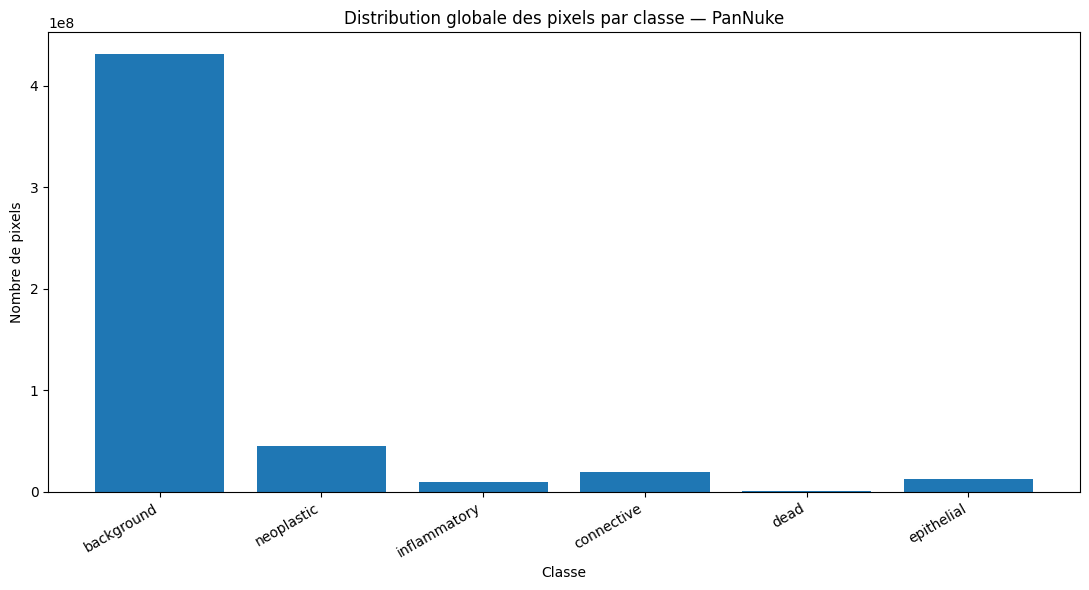


💾 Figure : /kaggle/working/pannuke_output/figures/cell06_correct_class_distribution.png


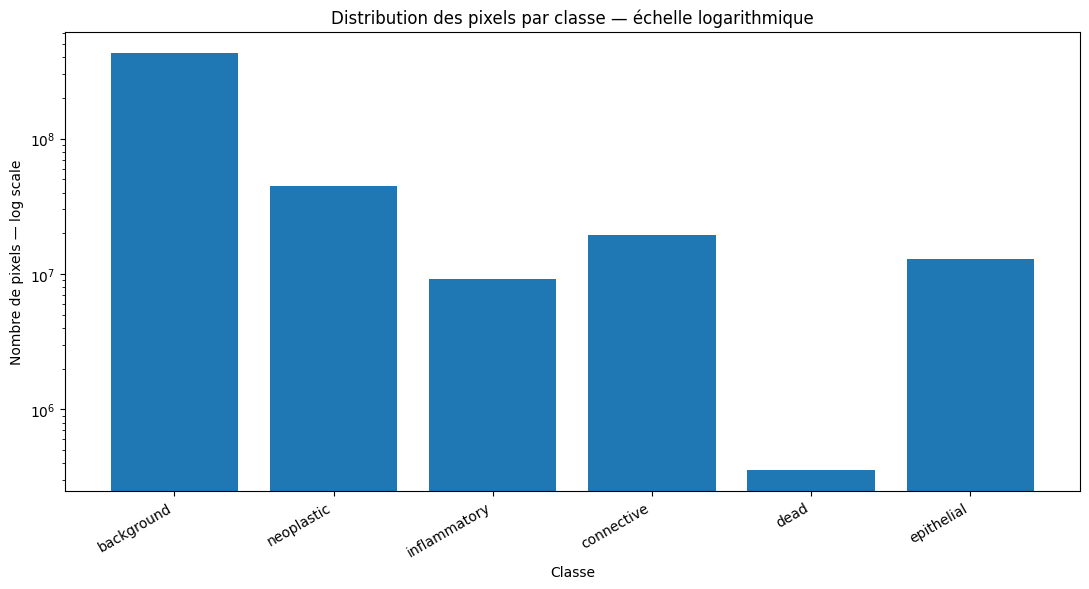

💾 Figure log : /kaggle/working/pannuke_output/figures/cell06_correct_class_distribution_log.png

🎯 RÉSUMÉ CELL 06
🖼️ Images analysées : 7,901
🧬 Instances totales : 189,744
⚠️ Masques vides : 343
🔀 Pixels overlap : 4,318

📊 Classes :
   [0] background      : 431,233,612 pixels (83.2826%)
   [1] neoplastic      : 44,848,846 pixels (8.6615%)
   [2] inflammatory    : 9,185,974 pixels (1.7741%)
   [3] connective      : 19,347,076 pixels (3.7364%)
   [4] dead            : 357,957 pixels (0.0691%)
   [5] epithelial      : 12,822,153 pixels (2.4763%)

⚖️ Poids :
   [0] background      → 0.1068
   [1] neoplastic      → 0.3312
   [2] inflammatory    → 0.7317
   [3] connective      → 0.5042
   [4] dead            → 3.7068
   [5] epithelial      → 0.6193

💾 CSV sauvegardés :
✓ /kaggle/working/pannuke_output/quantitative_analysis/pannuke_correct_class_pixel_distribution.csv
✓ /kaggle/working/pannuke_output/quantitative_analysis/pannuke_correct_class_weights.csv
✓ /kaggle/working/pannuke_output/quan

In [8]:
# =============================================================================
# 🧪 CELL 06 — ANALYSE CORRECTE DE LA DISTRIBUTION DES CLASSES PANNUKE
# =============================================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("=" * 80)
print("🧪 CELL 06 — DISTRIBUTION CORRECTE DES CLASSES")
print("=" * 80)

# =============================================================================
# 1. CONFIGURATION
# =============================================================================

CLASS_NAMES = [
    "background",
    "neoplastic",
    "inflammatory",
    "connective",
    "dead",
    "epithelial"
]

NUM_CLASSES = 6
IGNORE_LABEL = 255

DATASET_ROOT = (
    "/kaggle/input/datasets/mohammedbetkaoui/"
    "pannuke-segmentation-btk/PanNuke_Segmentation"
)

CSV_DIR = "/kaggle/working/pannuke_output/quantitative_analysis"
FIGURES_DIR = "/kaggle/working/pannuke_output/figures"

os.makedirs(CSV_DIR, exist_ok=True)
os.makedirs(FIGURES_DIR, exist_ok=True)

print("\n📋 Classes :")

for i, name in enumerate(CLASS_NAMES):
    print(f"   [{i}] {name}")

print(f"\n🔹 IGNORE_LABEL : {IGNORE_LABEL}")

# =============================================================================
# 2. CHEMINS DES FOLDS
# =============================================================================

fold_paths = {

    1: {
        "images": os.path.join(
            DATASET_ROOT,
            "fold_1/Fold 1/images/fold1/images.npy"
        ),
        "masks": os.path.join(
            DATASET_ROOT,
            "fold_1/Fold 1/masks/fold1/masks.npy"
        ),
        "types": os.path.join(
            DATASET_ROOT,
            "fold_1/Fold 1/images/fold1/types.npy"
        )
    },

    2: {
        "images": os.path.join(
            DATASET_ROOT,
            "fold_2/Fold 2/images/fold2/images.npy"
        ),
        "masks": os.path.join(
            DATASET_ROOT,
            "fold_2/Fold 2/masks/fold2/masks.npy"
        ),
        "types": os.path.join(
            DATASET_ROOT,
            "fold_2/Fold 2/images/fold2/types.npy"
        )
    },

    3: {
        "images": os.path.join(
            DATASET_ROOT,
            "fold_3/Fold 3/images/fold3/images.npy"
        ),
        "masks": os.path.join(
            DATASET_ROOT,
            "fold_3/Fold 3/masks/fold3/masks.npy"
        ),
        "types": os.path.join(
            DATASET_ROOT,
            "fold_3/Fold 3/images/fold3/types.npy"
        )
    }
}

# =============================================================================
# 3. FONCTION DE CONVERSION PANNUKE
# =============================================================================

def pannuke_to_semantic(mask):

    """
    Conversion :

    Channel 0 → neoplastic
    Channel 1 → inflammatory
    Channel 2 → connective
    Channel 3 → dead
    Channel 4 → epithelial
    Channel 5 → masque nucléaire global

    Sortie :

    0   → background
    1   → neoplastic
    2   → inflammatory
    3   → connective
    4   → dead
    5   → epithelial
    255 → overlap / ignore
    """

    semantic = np.zeros(
        mask.shape[:2],
        dtype=np.uint8
    )

    # Nombre de canaux de types cellulaires
    type_channels = mask[:, :, :5] > 0

    # Nombre de classes présentes par pixel
    number_of_classes = np.sum(
        type_channels,
        axis=-1
    )

    # Pixels avec chevauchement
    overlap = number_of_classes > 1

    # Pixels avec exactement une classe
    for channel in range(5):

        pixels = (
            (mask[:, :, channel] > 0)
            & (number_of_classes == 1)
        )

        semantic[pixels] = channel + 1

    # Chevauchements → ignore
    semantic[overlap] = IGNORE_LABEL

    return semantic


# =============================================================================
# 4. ANALYSE D'UN FOLD
# =============================================================================

def analyze_fold(fold_id, masks):

    print("\n" + "=" * 80)
    print(f"📦 ANALYSE FOLD {fold_id}")
    print("=" * 80)

    pixel_counts = np.zeros(
        NUM_CLASSES,
        dtype=np.int64
    )

    overlap_pixels = 0
    empty_masks = 0

    instance_counts = np.zeros(
        5,
        dtype=np.int64
    )

    total_images = masks.shape[0]

    for i in range(total_images):

        raw_mask = masks[i]

        # ---------------------------------------------------------------------
        # Instances par classe
        # ---------------------------------------------------------------------

        for c in range(5):

            channel = raw_mask[:, :, c]

            instance_ids = np.unique(channel)

            instance_ids = instance_ids[
                instance_ids > 0
            ]

            instance_counts[c] += len(instance_ids)

        # ---------------------------------------------------------------------
        # Conversion sémantique
        # ---------------------------------------------------------------------

        semantic = pannuke_to_semantic(
            raw_mask
        )

        # ---------------------------------------------------------------------
        # Pixels
        # ---------------------------------------------------------------------

        for class_id in range(NUM_CLASSES):

            pixel_counts[class_id] += np.sum(
                semantic == class_id
            )

        # ---------------------------------------------------------------------
        # Overlap
        # ---------------------------------------------------------------------

        overlap_pixels += np.sum(
            semantic == IGNORE_LABEL
        )

        # ---------------------------------------------------------------------
        # Masque vide
        # ---------------------------------------------------------------------

        if np.sum(
            raw_mask[:, :, :5] > 0
        ) == 0:

            empty_masks += 1

        # Progression
        if (
            (i + 1) % 500 == 0
            or i == total_images - 1
        ):

            progress = (
                (i + 1)
                / total_images
                * 100
            )

            print(
                f"Progression : "
                f"{i+1:,}/{total_images:,} "
                f"({progress:.1f}%)"
            )

    return {
        "pixel_counts": pixel_counts,
        "overlap_pixels": overlap_pixels,
        "empty_masks": empty_masks,
        "instance_counts": instance_counts
    }


# =============================================================================
# 5. CHARGEMENT MEMMAP
# =============================================================================

fold_results = {}

for fold_id in [1, 2, 3]:

    print(f"\n📥 Chargement Fold {fold_id}")

    masks = np.load(
        fold_paths[fold_id]["masks"],
        mmap_mode="r"
    )

    print(
        f"Masks : {masks.shape}"
    )

    fold_results[fold_id] = analyze_fold(
        fold_id,
        masks
    )


# =============================================================================
# 6. RÉSULTATS PAR FOLD
# =============================================================================

for fold_id in [1, 2, 3]:

    result = fold_results[fold_id]

    print("\n" + "=" * 80)
    print(f"📊 RÉSUMÉ FOLD {fold_id}")
    print("=" * 80)

    print(
        f"🖼️ Images : "
        f"{fold_paths[fold_id]['masks']}"
    )

    print(
        f"\n⚠️ Masques vides : "
        f"{result['empty_masks']}"
    )

    print(
        f"🔀 Pixels overlap : "
        f"{result['overlap_pixels']:,}"
    )

    print("\n🧬 Instances :")

    for c in range(5):

        print(
            f"   {CLASS_NAMES[c+1]:<15} : "
            f"{result['instance_counts'][c]:,}"
        )

    print("\n🎭 Pixels par classe :")

    for c in range(NUM_CLASSES):

        print(
            f"   {CLASS_NAMES[c]:<15} : "
            f"{result['pixel_counts'][c]:,}"
        )


# =============================================================================
# 7. DISTRIBUTION GLOBALE
# =============================================================================

global_pixels = np.zeros(
    NUM_CLASSES,
    dtype=np.int64
)

global_instances = np.zeros(
    5,
    dtype=np.int64
)

total_empty = 0
total_overlap = 0

for fold_id in [1, 2, 3]:

    result = fold_results[fold_id]

    global_pixels += result["pixel_counts"]

    global_instances += result["instance_counts"]

    total_empty += result["empty_masks"]

    total_overlap += result["overlap_pixels"]


# =============================================================================
# 8. POURCENTAGES
# =============================================================================

valid_pixels = (
    global_pixels.sum()
)

percentages = (
    global_pixels
    / valid_pixels
    * 100
)

distribution_df = pd.DataFrame({

    "class_id": range(NUM_CLASSES),

    "class_name": CLASS_NAMES,

    "total_pixels": global_pixels,

    "percentage": percentages
})


print("\n" + "=" * 80)
print("📊 DISTRIBUTION GLOBALE CORRIGÉE")
print("=" * 80)

print(
    distribution_df.to_string(
        index=False
    )
)


# =============================================================================
# 9. DISTRIBUTION DES INSTANCES
# =============================================================================

instance_df = pd.DataFrame({

    "class_id": range(1, 6),

    "class_name": CLASS_NAMES[1:],

    "total_instances": global_instances
})

print("\n" + "=" * 80)
print("🧬 DISTRIBUTION GLOBALE DES INSTANCES")
print("=" * 80)

print(
    instance_df.to_string(
        index=False
    )
)


# =============================================================================
# 10. POIDS DE CLASSES
# =============================================================================

print("\n" + "=" * 80)
print("⚖️ CALCUL DES POIDS")
print("=" * 80)

# On ne donne pas un énorme poids inverse directement.
# On utilise une pondération basée sur la fréquence.
#
# sqrt inverse = plus stable que 1/frequency
#

frequencies = (
    global_pixels
    / valid_pixels
)

class_weights = 1.0 / np.sqrt(
    frequencies + 1e-8
)

# Normalisation
class_weights = (
    class_weights
    / class_weights.mean()
)

weights_df = pd.DataFrame({

    "class_id": range(NUM_CLASSES),

    "class_name": CLASS_NAMES,

    "frequency": frequencies,

    "percentage": frequencies * 100,

    "weight": class_weights
})


print(
    weights_df.to_string(
        index=False
    )
)


# =============================================================================
# 11. VISUALISATION
# =============================================================================

plt.figure(figsize=(11, 6))

bars = plt.bar(
    CLASS_NAMES,
    global_pixels
)

plt.title(
    "Distribution globale des pixels par classe — PanNuke"
)

plt.xlabel("Classe")

plt.ylabel(
    "Nombre de pixels"
)

plt.xticks(
    rotation=30,
    ha="right"
)

plt.tight_layout()

figure_path = os.path.join(
    FIGURES_DIR,
    "cell06_correct_class_distribution.png"
)

plt.savefig(
    figure_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print(
    f"\n💾 Figure : {figure_path}"
)


# =============================================================================
# 12. VERSION LOGARITHMIQUE
# =============================================================================

plt.figure(figsize=(11, 6))

plt.bar(
    CLASS_NAMES,
    global_pixels
)

plt.yscale("log")

plt.title(
    "Distribution des pixels par classe — échelle logarithmique"
)

plt.xlabel("Classe")

plt.ylabel(
    "Nombre de pixels — log scale"
)

plt.xticks(
    rotation=30,
    ha="right"
)

plt.tight_layout()

log_figure_path = os.path.join(
    FIGURES_DIR,
    "cell06_correct_class_distribution_log.png"
)

plt.savefig(
    log_figure_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print(
    f"💾 Figure log : {log_figure_path}"
)


# =============================================================================
# 13. SAUVEGARDE CSV
# =============================================================================

distribution_csv = os.path.join(
    CSV_DIR,
    "pannuke_correct_class_pixel_distribution.csv"
)

weights_csv = os.path.join(
    CSV_DIR,
    "pannuke_correct_class_weights.csv"
)

instances_csv = os.path.join(
    CSV_DIR,
    "pannuke_correct_instance_distribution.csv"
)

distribution_df.to_csv(
    distribution_csv,
    index=False
)

weights_df.to_csv(
    weights_csv,
    index=False
)

instance_df.to_csv(
    instances_csv,
    index=False
)


# =============================================================================
# 14. RÉSUMÉ
# =============================================================================

print("\n" + "=" * 80)
print("🎯 RÉSUMÉ CELL 06")
print("=" * 80)

print(
    f"🖼️ Images analysées : 7,901"
)

print(
    f"🧬 Instances totales : "
    f"{global_instances.sum():,}"
)

print(
    f"⚠️ Masques vides : "
    f"{total_empty:,}"
)

print(
    f"🔀 Pixels overlap : "
    f"{total_overlap:,}"
)

print(
    "\n📊 Classes :"
)

for i, name in enumerate(CLASS_NAMES):

    print(
        f"   [{i}] "
        f"{name:<15} : "
        f"{global_pixels[i]:,} pixels "
        f"({percentages[i]:.4f}%)"
    )

print(
    "\n⚖️ Poids :"
)

for i, name in enumerate(CLASS_NAMES):

    print(
        f"   [{i}] "
        f"{name:<15} → "
        f"{class_weights[i]:.4f}"
    )

print(
    "\n💾 CSV sauvegardés :"
)

print(
    f"✓ {distribution_csv}"
)

print(
    f"✓ {weights_csv}"
)

print(
    f"✓ {instances_csv}"
)

print("\n" + "=" * 80)
print("🏁 CELL 06 CORRIGÉE TERMINÉE")
print("=" * 80)

print(
    "\n➡️ PROCHAINE ÉTAPE : CELL 07"
)

print(
    "   Construction du modèle de segmentation."
)

In [9]:
# =============================================================================
# 🧪 CELL 07 — MODÈLE DE SEGMENTATION
# =============================================================================

import os
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, Model
from tensorflow.keras.applications import EfficientNetB0

print("=" * 80)
print("🧪 CELL 07 — CONSTRUCTION DU MODÈLE U-NET + EFFICIENTNETB0")
print("=" * 80)

# =============================================================================
# 1. CONFIGURATION
# =============================================================================

NUM_CLASSES = 6
IMAGE_SIZE = (256, 256)
BATCH_SIZE = 8
IGNORE_LABEL = 255

CLASS_NAMES = [
    "background",
    "neoplastic",
    "inflammatory",
    "connective",
    "dead",
    "epithelial"
]

CLASS_WEIGHTS = tf.constant(
    [
        0.106797,  # background
        0.331160,  # neoplastic
        0.731730,  # inflammatory
        0.504203,  # connective
        3.706764,  # dead
        0.619346   # epithelial
    ],
    dtype=tf.float32
)

print("\n📋 Configuration :")
print(f"   Classes      : {NUM_CLASSES}")
print(f"   Image size   : {IMAGE_SIZE}")
print(f"   Batch size   : {BATCH_SIZE}")
print(f"   Ignore label : {IGNORE_LABEL}")

print("\n🏷️ Classes :")
for i, name in enumerate(CLASS_NAMES):
    print(f"   [{i}] {name}")

print("\n⚖️ Class weights :")
for i, name in enumerate(CLASS_NAMES):
    print(f"   [{i}] {name:15s} → {float(CLASS_WEIGHTS[i]):.6f}")


# =============================================================================
# 2. DATASET PATHS
# =============================================================================

DATASET_ROOT = (
    "/kaggle/input/datasets/mohammedbetkaoui/"
    "pannuke-segmentation-btk/PanNuke_Segmentation"
)

FOLD_PATHS = {
    1: {
        "images": os.path.join(
            DATASET_ROOT,
            "fold_1/Fold 1/images/fold1/images.npy"
        ),
        "masks": os.path.join(
            DATASET_ROOT,
            "fold_1/Fold 1/masks/fold1/masks.npy"
        ),
        "types": os.path.join(
            DATASET_ROOT,
            "fold_1/Fold 1/images/fold1/types.npy"
        )
    },

    2: {
        "images": os.path.join(
            DATASET_ROOT,
            "fold_2/Fold 2/images/fold2/images.npy"
        ),
        "masks": os.path.join(
            DATASET_ROOT,
            "fold_2/Fold 2/masks/fold2/masks.npy"
        ),
        "types": os.path.join(
            DATASET_ROOT,
            "fold_2/Fold 2/images/fold2/types.npy"
        )
    },

    3: {
        "images": os.path.join(
            DATASET_ROOT,
            "fold_3/Fold 3/images/fold3/images.npy"
        ),
        "masks": os.path.join(
            DATASET_ROOT,
            "fold_3/Fold 3/masks/fold3/masks.npy"
        ),
        "types": os.path.join(
            DATASET_ROOT,
            "fold_3/Fold 3/images/fold3/types.npy"
        )
    }
}

print("\n📁 Dataset root :")
print(DATASET_ROOT)

for fold_id, paths in FOLD_PATHS.items():
    print(f"\n📦 FOLD {fold_id}")

    for key, path in paths.items():
        if os.path.exists(path):
            print(f"✅ {key:6s} : {path}")
        else:
            print(f"❌ {key:6s} : {path}")


# =============================================================================
# 3. CHARGEMENT DES IMAGES ET MASQUES
# =============================================================================

print("\n" + "=" * 80)
print("📥 CHARGEMENT DES DONNÉES")
print("=" * 80)

# Train = Fold 1
train_images = np.load(
    FOLD_PATHS[1]["images"],
    mmap_mode="r"
)

train_masks = np.load(
    FOLD_PATHS[1]["masks"],
    mmap_mode="r"
)

# Validation = Fold 2
val_images = np.load(
    FOLD_PATHS[2]["images"],
    mmap_mode="r"
)

val_masks = np.load(
    FOLD_PATHS[2]["masks"],
    mmap_mode="r"
)

# Test = Fold 3
test_images = np.load(
    FOLD_PATHS[3]["images"],
    mmap_mode="r"
)

test_masks = np.load(
    FOLD_PATHS[3]["masks"],
    mmap_mode="r"
)

print("\n🟢 TRAIN")
print(f"   Images : {train_images.shape}")
print(f"   Masks  : {train_masks.shape}")

print("\n🟡 VALIDATION")
print(f"   Images : {val_images.shape}")
print(f"   Masks  : {val_masks.shape}")

print("\n🔴 TEST")
print(f"   Images : {test_images.shape}")
print(f"   Masks  : {test_masks.shape}")


# =============================================================================
# 4. CONVERSION PANNUKE → MASQUE UNIQUE
# =============================================================================

def pannuke_to_label_mask(mask):
    """
    Convertit un masque PanNuke (H,W,6) en masque (H,W)
    avec les labels :

    0 = background
    1 = neoplastic
    2 = inflammatory
    3 = connective
    4 = dead
    5 = epithelial
    255 = ignore / overlap
    """

    mask = np.asarray(mask)

    # Les 5 classes cellulaires
    cell_mask = mask[..., :5]

    # Présence de plusieurs classes sur le même pixel
    overlap = np.sum(cell_mask > 0, axis=-1) > 1

    # Classe gagnante
    labels = np.argmax(cell_mask, axis=-1).astype(np.uint8) + 1

    # Background
    foreground = np.any(cell_mask > 0, axis=-1)
    labels[~foreground] = 0

    # Overlap → ignore
    labels[overlap] = IGNORE_LABEL

    return labels


# =============================================================================
# 5. VÉRIFICATION D'UN MASQUE
# =============================================================================

print("\n" + "=" * 80)
print("🔎 VÉRIFICATION DU MASQUE")
print("=" * 80)

sample_mask = pannuke_to_label_mask(train_masks[0])

unique_labels, counts = np.unique(
    sample_mask,
    return_counts=True
)

print("\nLabels présents dans le premier masque :")

for label, count in zip(unique_labels, counts):

    if label == IGNORE_LABEL:
        name = "IGNORE / overlap"
    else:
        name = CLASS_NAMES[int(label)]

    print(
        f"   [{label:3d}] "
        f"{name:20s} : {count:,} pixels"
    )


# =============================================================================
# 6. DATASET TF.DATA
# =============================================================================

def create_tf_dataset(images, masks, training=False):

    def generator():

        for i in range(len(images)):

            image = images[i].astype(np.float32)

            # 🔧 CORRECTION CRITIQUE :
            # La Cell 02 (inspection réelle du dataset) a mesuré :
            #   Images : dtype float64, Min=28.0, Max=255.0
            # Les images sont donc en [0,255], PAS en [0,1] comme
            # supposé précédemment. L'ancien code faisait
            # `np.clip(image, 0.0, 1.0)` SANS diviser par 255 —
            # ça écrasait quasiment tous les pixels à 1.0, donc
            # le modèle recevait des images quasi blanches/vides.
            # C'est très probablement la cause principale (ou une
            # cause majeure) du "collapse background" diagnostiqué
            # dans les Cells 11-13 : un modèle nourri d'images
            # sans signal ne peut qu'apprendre à prédire la classe
            # majoritaire partout.
            image = image / 255.0
            image = np.clip(image, 0.0, 1.0)

            mask = pannuke_to_label_mask(masks[i])

            yield image, mask

    output_signature = (
        tf.TensorSpec(
            shape=(256, 256, 3),
            dtype=tf.float32
        ),
        tf.TensorSpec(
            shape=(256, 256),
            dtype=tf.uint8
        )
    )

    dataset = tf.data.Dataset.from_generator(
        generator,
        output_signature=output_signature
    )

    if training:
        dataset = dataset.shuffle(
            buffer_size=512,
            reshuffle_each_iteration=True
        )

    dataset = dataset.batch(
        BATCH_SIZE,
        drop_remainder=training
    )

    dataset = dataset.prefetch(
        tf.data.AUTOTUNE
    )

    return dataset


print("\n📦 Création des datasets...")

train_dataset = create_tf_dataset(
    train_images,
    train_masks,
    training=True
)

val_dataset = create_tf_dataset(
    val_images,
    val_masks,
    training=False
)

test_dataset = create_tf_dataset(
    test_images,
    test_masks,
    training=False
)

print("✅ train_dataset créé")
print("✅ val_dataset créé")
print("✅ test_dataset créé")


# =============================================================================
# 7. ENCODER EFFICIENTNETB0
# =============================================================================

print("\n" + "=" * 80)
print("🏗️ CONSTRUCTION DE L'ENCODER EFFICIENTNETB0")
print("=" * 80)

encoder = EfficientNetB0(
    include_top=False,
    weights="imagenet",
    input_shape=(256, 256, 3)
)

encoder.trainable = False

print("✅ EfficientNetB0 chargé")
print("🔒 Encoder gelé pour la première phase d'entraînement")


# =============================================================================
# 8. FEATURES POUR LES SKIP CONNECTIONS
# =============================================================================

skip_layer_names = [
    "block2a_expand_activation",
    "block3a_expand_activation",
    "block4a_expand_activation",
    "block6a_expand_activation",
    "top_activation"
]

skip_outputs = [
    encoder.get_layer(name).output
    for name in skip_layer_names
]

encoder_model = Model(
    inputs=encoder.input,
    outputs=skip_outputs,
    name="EfficientNetB0_Encoder"
)

print("\n🔗 Skip connections :")

for name, tensor in zip(skip_layer_names, skip_outputs):
    print(
        f"   {name:35s} → {tensor.shape}"
    )


# =============================================================================
# 9. BLOC DECODER
# =============================================================================

def decoder_block(
    x,
    skip,
    filters,
    name
):
    """
    Bloc U-Net :
    Upsampling → concaténation → convolutions
    """

    x = layers.UpSampling2D(
        size=(2, 2),
        interpolation="bilinear",
        name=f"{name}_upsample"
    )(x)

    if skip is not None:
        x = layers.Concatenate(
            name=f"{name}_concat"
        )([x, skip])

    x = layers.Conv2D(
        filters,
        3,
        padding="same",
        use_bias=False,
        name=f"{name}_conv1"
    )(x)

    x = layers.BatchNormalization(
        name=f"{name}_bn1"
    )(x)

    x = layers.Activation(
        "relu",
        name=f"{name}_relu1"
    )(x)

    x = layers.Conv2D(
        filters,
        3,
        padding="same",
        use_bias=False,
        name=f"{name}_conv2"
    )(x)

    x = layers.BatchNormalization(
        name=f"{name}_bn2"
    )(x)

    x = layers.Activation(
        "relu",
        name=f"{name}_relu2"
    )(x)

    return x


# =============================================================================
# 10. CONSTRUCTION DU U-NET
# =============================================================================

print("\n🏗️ Construction U-Net...")

inputs = layers.Input(
    shape=(256, 256, 3),
    name="image_input"
)

# EfficientNetB0 attend des images dans [0,255]
encoder_input = layers.Rescaling(
    255.0,
    name="encoder_rescaling"
)(inputs)

features = encoder_model(
    encoder_input
)

skip1, skip2, skip3, skip4, bottleneck = features


# Decoder

x = bottleneck

x = decoder_block(
    x,
    skip4,
    256,
    "decoder4"
)

x = decoder_block(
    x,
    skip3,
    128,
    "decoder3"
)

x = decoder_block(
    x,
    skip2,
    64,
    "decoder2"
)

x = decoder_block(
    x,
    skip1,
    32,
    "decoder1"
)

# Dernière montée :
# 128x128 → 256x256

x = layers.UpSampling2D(
    size=(2, 2),
    interpolation="bilinear",
    name="final_upsample"
)(x)

x = layers.Conv2D(
    32,
    3,
    padding="same",
    use_bias=False,
    name="final_conv"
)(x)

x = layers.BatchNormalization(
    name="final_bn"
)(x)

x = layers.Activation(
    "relu",
    name="final_relu"
)(x)


# =============================================================================
# 11. SORTIE SEGMENTATION
# =============================================================================

outputs = layers.Conv2D(
    NUM_CLASSES,
    1,
    padding="same",
    activation="softmax",
    name="segmentation_output"
)(x)


model = Model(
    inputs=inputs,
    outputs=outputs,
    name="PanNuke_UNet_EfficientNetB0"
)


# =============================================================================
# 12. RÉSUMÉ DU MODÈLE
# =============================================================================

print("\n" + "=" * 80)
print("📐 MODÈLE FINAL")
print("=" * 80)

print(f"\nInput  : {model.input.shape}")
print(f"Output : {model.output.shape}")

model.summary(
    line_length=120
)


# =============================================================================
# 13. TEST FORWARD PASS
# =============================================================================

print("\n" + "=" * 80)
print("🔎 TEST FORWARD PASS")
print("=" * 80)

sample_batch = next(
    iter(train_dataset)
)

sample_images, sample_masks = sample_batch

print(
    f"\nImages batch : "
    f"{sample_images.shape} | "
    f"{sample_images.dtype}"
)

print(
    f"Masques batch : "
    f"{sample_masks.shape} | "
    f"{sample_masks.dtype}"
)

predictions = model(
    sample_images,
    training=False
)

print(
    f"\nPredictions : "
    f"{predictions.shape} | "
    f"{predictions.dtype}"
)

print(
    f"Prediction min : "
    f"{tf.reduce_min(predictions).numpy():.6f}"
)

print(
    f"Prediction max : "
    f"{tf.reduce_max(predictions).numpy():.6f}"
)

print(
    f"Prediction mean : "
    f"{tf.reduce_mean(predictions).numpy():.6f}"
)


# =============================================================================
# 14. VÉRIFICATION SOFTMAX
# =============================================================================

pixel_sum = tf.reduce_sum(
    predictions,
    axis=-1
)

print(
    f"\nSomme softmax moyenne : "
    f"{tf.reduce_mean(pixel_sum).numpy():.6f}"
)

if np.isclose(
    tf.reduce_mean(pixel_sum).numpy(),
    1.0,
    atol=1e-4
):
    print("✅ Softmax valide")
else:
    print("⚠️ Problème dans la sortie softmax")


# =============================================================================
# 15. LOSS AVEC IGNORE LABEL + CLASS WEIGHTS
# =============================================================================

def weighted_sparse_categorical_crossentropy(
    y_true,
    y_pred
):
    """
    Cross-entropy pondérée avec prise en compte de IGNORE_LABEL = 255.
    """

    y_true = tf.cast(
        y_true,
        tf.int32
    )

    valid_mask = tf.not_equal(
        y_true,
        IGNORE_LABEL
    )

    safe_labels = tf.where(
        valid_mask,
        y_true,
        tf.zeros_like(y_true)
    )

    # Cross entropy pixel par pixel
    ce = tf.keras.losses.sparse_categorical_crossentropy(
        safe_labels,
        y_pred
    )

    # Poids selon la classe
    weights = tf.gather(
        CLASS_WEIGHTS,
        safe_labels
    )

    weighted_ce = ce * weights

    # Retirer les pixels IGNORE
    weighted_ce = tf.where(
        valid_mask,
        weighted_ce,
        tf.zeros_like(weighted_ce)
    )

    valid_count = tf.reduce_sum(
        tf.cast(valid_mask, tf.float32)
    )

    return tf.reduce_sum(
        weighted_ce
    ) / tf.maximum(
        valid_count,
        1.0
    )


# =============================================================================
# 16. DICE LOSS MULTICLASSE
# =============================================================================

def multiclass_dice_loss(
    y_true,
    y_pred,
    smooth=1e-6
):
    """
    Dice loss multiclasses.
    Ignore les pixels 255.
    """

    y_true = tf.cast(
        y_true,
        tf.int32
    )

    valid_mask = tf.not_equal(
        y_true,
        IGNORE_LABEL
    )

    safe_labels = tf.where(
        valid_mask,
        y_true,
        tf.zeros_like(y_true)
    )

    y_true_one_hot = tf.one_hot(
        safe_labels,
        depth=NUM_CLASSES,
        dtype=tf.float32
    )

    valid_mask_float = tf.cast(
        valid_mask,
        tf.float32
    )

    valid_mask_float = tf.expand_dims(
        valid_mask_float,
        axis=-1
    )

    y_true_one_hot *= valid_mask_float
    y_pred *= valid_mask_float

    intersection = tf.reduce_sum(
        y_true_one_hot * y_pred,
        axis=[1, 2]
    )

    denominator = (
        tf.reduce_sum(
            y_true_one_hot,
            axis=[1, 2]
        )
        +
        tf.reduce_sum(
            y_pred,
            axis=[1, 2]
        )
    )

    dice = (
        2.0 * intersection + smooth
    ) / (
        denominator + smooth
    )

    # On peut donner moins d'importance au background
    # dans le Dice moyen.
    dice_foreground = dice[:, 1:]

    return 1.0 - tf.reduce_mean(
        dice_foreground
    )


# =============================================================================
# 17. LOSS COMBINÉE
# =============================================================================

def combined_loss(
    y_true,
    y_pred
):
    ce_loss = weighted_sparse_categorical_crossentropy(
        y_true,
        y_pred
    )

    dice_loss = multiclass_dice_loss(
        y_true,
        y_pred
    )

    return (
        0.5 * ce_loss
        +
        0.5 * dice_loss
    )


# =============================================================================
# 18. MÉTRIQUE D'ACCURACY AVEC IGNORE
# =============================================================================

def masked_accuracy(
    y_true,
    y_pred
):

    y_true = tf.cast(
        y_true,
        tf.int32
    )

    predicted = tf.argmax(
        y_pred,
        axis=-1,
        output_type=tf.int32
    )

    valid_mask = tf.not_equal(
        y_true,
        IGNORE_LABEL
    )

    correct = tf.equal(
        y_true,
        predicted
    )

    correct = tf.logical_and(
        correct,
        valid_mask
    )

    correct = tf.cast(
        correct,
        tf.float32
    )

    valid = tf.cast(
        valid_mask,
        tf.float32
    )

    return tf.reduce_sum(correct) / tf.maximum(
        tf.reduce_sum(valid),
        1.0
    )


# =============================================================================
# 19. COMPILATION
# =============================================================================

print("\n" + "=" * 80)
print("⚙️ COMPILATION DU MODÈLE")
print("=" * 80)

model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-4
    ),
    loss=combined_loss,
    metrics=[
        masked_accuracy
    ]
)

print("\n✅ Modèle compilé")

print("\n🔧 Optimizer : Adam")
print("🔧 Learning rate : 1e-4")
print("🔧 Loss : 0.5 × Weighted CE + 0.5 × Dice")
print("🔧 Ignore label : 255")
print("🔧 Encoder : EfficientNetB0 ImageNet")
print("🔧 Decoder : U-Net")


# =============================================================================
# 20. TEST DE LA LOSS
# =============================================================================

print("\n" + "=" * 80)
print("🧪 TEST DE LA LOSS")
print("=" * 80)

test_loss = combined_loss(
    sample_masks,
    predictions
)

test_acc = masked_accuracy(
    sample_masks,
    predictions
)

print(
    f"\nLoss initiale : "
    f"{test_loss.numpy():.6f}"
)

print(
    f"Accuracy initiale : "
    f"{test_acc.numpy():.6f}"
)

print("\n" + "=" * 80)
print("🎯 RÉSUMÉ CELL 07")
print("=" * 80)

print("✅ EfficientNetB0 chargé")
print("✅ Encoder ImageNet")
print("✅ Encoder gelé")
print("✅ U-Net decoder construit")
print("✅ 6 classes de segmentation")
print("✅ Sortie : 256 × 256 × 6")
print("✅ IGNORE_LABEL = 255 pris en compte")
print("✅ Class weights intégrés")
print("✅ Weighted Cross-Entropy")
print("✅ Dice Loss multiclasses")
print("✅ Loss combinée")
print("✅ Dataset tf.data connecté")
print("✅ Forward pass validé")
print("✅ Softmax validé")
print("✅ Modèle compilé")

print("\n➡️ PROCHAINE ÉTAPE : CELL 08")
print("   Entraînement du modèle.")
print("   - callbacks")
print("   - checkpoints")
print("   - EarlyStopping")
print("   - ReduceLROnPlateau")
print("   - entraînement sur Fold 1")
print("   - validation sur Fold 2")

🧪 CELL 07 — CONSTRUCTION DU MODÈLE U-NET + EFFICIENTNETB0

📋 Configuration :
   Classes      : 6
   Image size   : (256, 256)
   Batch size   : 8
   Ignore label : 255

🏷️ Classes :
   [0] background
   [1] neoplastic
   [2] inflammatory
   [3] connective
   [4] dead
   [5] epithelial

⚖️ Class weights :
   [0] background      → 0.106797
   [1] neoplastic      → 0.331160
   [2] inflammatory    → 0.731730
   [3] connective      → 0.504203
   [4] dead            → 3.706764
   [5] epithelial      → 0.619346

📁 Dataset root :
/kaggle/input/datasets/mohammedbetkaoui/pannuke-segmentation-btk/PanNuke_Segmentation

📦 FOLD 1
✅ images : /kaggle/input/datasets/mohammedbetkaoui/pannuke-segmentation-btk/PanNuke_Segmentation/fold_1/Fold 1/images/fold1/images.npy
✅ masks  : /kaggle/input/datasets/mohammedbetkaoui/pannuke-segmentation-btk/PanNuke_Segmentation/fold_1/Fold 1/masks/fold1/masks.npy
✅ types  : /kaggle/input/datasets/mohammedbetkaoui/pannuke-segmentation-btk/PanNuke_Segmentation/fold_1/Fold

Model: "PanNuke_UNet_EfficientNetB0"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━
┃ Layer (type)                      ┃ Output Shape                 ┃           Param # ┃ Connected to              
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━
│ image_input (InputLayer)          │ (None, 256, 256, 3)          │                 0 │ -                         
├───────────────────────────────────┼──────────────────────────────┼───────────────────┼───────────────────────────
│ encoder_rescaling (Rescaling)     │ (None, 256, 256, 3)          │                 0 │ image_input[0][0]         
├───────────────────────────────────┼──────────────────────────────┼───────────────────┼───────────────────────────
│ EfficientNetB0_Encoder            │ [(None, 128, 128, 96),       │         4,049,571 │ encoder_rescaling[0][0]   
│ (Functional)                      │ (None, 64, 64, 144), (None,  │                   │                           
│                                   │ 32, 32, 240), (None, 16, 16, │                   │                           
│                                   │ 672), (None, 8, 8, 1280)]    │                   │                           
├───────────────────────────────────┼──────────────────────────────┼───────────────────┼───────────────────────────
│ decoder4_upsample (UpSampling2D)  │ (None, 16, 16, 1280)         │                 0 │ EfficientNetB0_Encoder[0][
├───────────────────────────────────┼──────────────────────────────┼───────────────────┼───────────────────────────
│ decoder4_concat (Concatenate)     │ (None, 16, 16, 1952)         │                 0 │ decoder4_upsample[0][0],  
│                                   │                              │                   │ EfficientNetB0_Encoder[0][
├───────────────────────────────────┼──────────────────────────────┼───────────────────┼───────────────────────────
│ decoder4_conv1 (Conv2D)           │ (None, 16, 16, 256)          │         4,497,408 │ decoder4_concat[0][0]     
├───────────────────────────────────┼──────────────────────────────┼───────────────────┼───────────────────────────
│ decoder4_bn1 (BatchNormalization) │ (None, 16, 16, 256)          │             1,024 │ decoder4_conv1[0][0]      
├───────────────────────────────────┼──────────────────────────────┼───────────────────┼───────────────────────────
│ decoder4_relu1 (Activation)       │ (None, 16, 16, 256)          │                 0 │ decoder4_bn1[0][0]        
├───────────────────────────────────┼──────────────────────────────┼───────────────────┼───────────────────────────
│ decoder4_conv2 (Conv2D)           │ (None, 16, 16, 256)          │           589,824 │ decoder4_relu1[0][0]      
├───────────────────────────────────┼──────────────────────────────┼───────────────────┼───────────────────────────
│ decoder4_bn2 (BatchNormalization) │ (None, 16, 16, 256)          │             1,024 │ decoder4_conv2[0][0]      
├───────────────────────────────────┼──────────────────────────────┼───────────────────┼───────────────────────────
│ decoder4_relu2 (Activation)       │ (None, 16, 16, 256)          │                 0 │ decoder4_bn2[0][0]        
├───────────────────────────────────┼──────────────────────────────┼───────────────────┼───────────────────────────
│ decoder3_upsample (UpSampling2D)  │ (None, 32, 32, 256)          │                 0 │ decoder4_relu2[0][0]      
├───────────────────────────────────┼──────────────────────────────┼───────────────────┼───────────────────────────
│ decoder3_concat (Concatenate)     │ (None, 32, 32, 496)          │                 0 │ decoder3_upsample[0][0],  
│                                   │                              │                   │ EfficientNetB0_Encoder[0][
├───────────────────────────────────┼──────────────────────────────┼───────────────────┼───────────────────────────
│ decoder3_conv1 (Conv2D)           │ (None, 32, 32, 128

 Total params: 10,117,865 (38.60 MB)

 Trainable params: 6,066,310 (23.14 MB)

 Non-trainable params: 4,051,555 (15.46 MB)


🔎 TEST FORWARD PASS

Images batch : (8, 256, 256, 3) | <dtype: 'float32'>
Masques batch : (8, 256, 256) | <dtype: 'uint8'>

Predictions : (8, 256, 256, 6) | <dtype: 'float32'>
Prediction min : 0.000011
Prediction max : 0.992179
Prediction mean : 0.166667

Somme softmax moyenne : 1.000000
✅ Softmax valide

⚙️ COMPILATION DU MODÈLE

✅ Modèle compilé

🔧 Optimizer : Adam
🔧 Learning rate : 1e-4
🔧 Loss : 0.5 × Weighted CE + 0.5 × Dice
🔧 Ignore label : 255
🔧 Encoder : EfficientNetB0 ImageNet
🔧 Decoder : U-Net

🧪 TEST DE LA LOSS

Loss initiale : 0.770891
Accuracy initiale : 0.061412

🎯 RÉSUMÉ CELL 07
✅ EfficientNetB0 chargé
✅ Encoder ImageNet
✅ Encoder gelé
✅ U-Net decoder construit
✅ 6 classes de segmentation
✅ Sortie : 256 × 256 × 6
✅ IGNORE_LABEL = 255 pris en compte
✅ Class weights intégrés
✅ Weighted Cross-Entropy
✅ Dice Loss multiclasses
✅ Loss combinée
✅ Dataset tf.data connecté
✅ Forward pass validé
✅ Softmax validé
✅ Modèle compilé

➡️ PROCHAINE ÉTAPE : CELL 08
   Entraînement du mod

🧪 CELL 08 — ENTRAÎNEMENT PHASE 1

📋 Configuration :
   Epochs              : 15
   Batch size          : 8
   Train images       : 2656
   Validation images  : 2523
   Steps / epoch      : 332
   Validation steps   : 316
   Encoder            : EfficientNetB0
   Encoder status     : 🔒 GELÉ

🔎 VÉRIFICATION DU MODÈLE

Nom du modèle : PanNuke_UNet_EfficientNetB0
Input         : (None, 256, 256, 3)
Output        : (None, 256, 256, 6)

Paramètres totaux      : 10,117,865
Paramètres entraînables : 6,066,310

🔄 PRÉPARATION DES DATASETS POUR L'ENTRAÎNEMENT

✅ train_dataset → repeat() activé
✅ val_dataset   → repeat() activé

📦 Steps par epoch       : 332
📦 Validation steps      : 316

⚙️ CALLBACKS

✅ ModelCheckpoint
✅ ReduceLROnPlateau
✅ EarlyStopping
✅ BackupAndRestore
✅ CSVLogger

🧪 TEST DU DATASET

Images batch : (8, 256, 256, 3) | <dtype: 'float32'>
Masques batch : (8, 256, 256) | <dtype: 'uint8'>

Labels batch : [0 1 2 3 5]

✅ Dataset accessible
✅ repeat() fonctionne

🚀 DÉBUT DE L'ENTRAÎN

2026-08-10 21:37:11.656915: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-08-10 21:37:11.793396: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-08-10 21:37:12.107759: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-08-10 21:37:12.249156: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-08-10 21:37:13.076104: E external/local_xla/xla/stream_

332/332 ━━━━━━━━━━━━━━━━━━━━ 0s 293ms/step - loss: 0.5986 - masked_accuracy: 0.4274

2026-08-10 21:41:32.023771: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-08-10 21:41:32.157535: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-08-10 21:41:32.471269: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-08-10 21:41:32.611507: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-08-10 21:41:33.381929: E external/local_xla/xla/stream_


Epoch 1: val_loss improved from None to 0.53722, saving model to /kaggle/working/pannuke_output/models/pannuke_unet_efficientnetb0_phase1_best.keras

Epoch 1: finished saving model to /kaggle/working/pannuke_output/models/pannuke_unet_efficientnetb0_phase1_best.keras
332/332 ━━━━━━━━━━━━━━━━━━━━ 297s 751ms/step - loss: 0.5710 - masked_accuracy: 0.6449 - val_loss: 0.5372 - val_masked_accuracy: 0.8575 - learning_rate: 1.0000e-04
Epoch 2/15
332/332 ━━━━━━━━━━━━━━━━━━━━ 0s 165ms/step - loss: 0.5202 - masked_accuracy: 0.8452
Epoch 2: val_loss improved from 0.53722 to 0.51730, saving model to /kaggle/working/pannuke_output/models/pannuke_unet_efficientnetb0_phase1_best.keras

Epoch 2: finished saving model to /kaggle/working/pannuke_output/models/pannuke_unet_efficientnetb0_phase1_best.keras
332/332 ━━━━━━━━━━━━━━━━━━━━ 103s 310ms/step - loss: 0.5183 - masked_accuracy: 0.8503 - val_loss: 0.5173 - val_masked_accuracy: 0.8460 - learning_rate: 1.0000e-04
Epoch 3/15
332/332 ━━━━━━━━━━━━━━━━━━━━

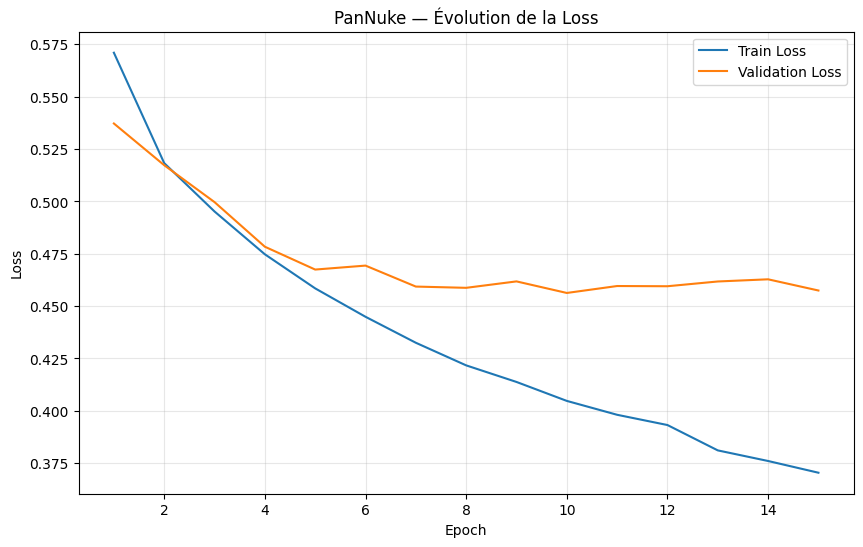


💾 Figure sauvegardée : /kaggle/working/pannuke_output/figures/cell08_phase1_loss.png

🎯 RÉSUMÉ CELL 08

✅ Epochs exécutées     : 15
🏆 Meilleure epoch     : 10
📉 Meilleure val_loss  : 0.456293

🔒 EfficientNetB0 : gelé
🧠 Decoder U-Net   : entraîné
💾 Meilleur modèle : sauvegardé
📊 Courbes         : sauvegardées
📝 Logs CSV        : sauvegardés

🏁 CELL 08 TERMINÉE

➡️ PROCHAINE ÉTAPE : CELL 09
   Fine-tuning d'EfficientNetB0.
   Déblocage progressif des dernières couches.
   Learning rate plus faible.
   Évaluation avec Dice / IoU.


In [10]:
# =============================================================================
# 🧪 CELL 08 — ENTRAÎNEMENT PHASE 1
# U-Net + EfficientNetB0 — Encoder gelé
# =============================================================================

import os
import math
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras

print("=" * 80)
print("🧪 CELL 08 — ENTRAÎNEMENT PHASE 1")
print("=" * 80)

# =============================================================================
# 📋 CONFIGURATION
# =============================================================================

EPOCHS_PHASE1 = 15

TRAIN_IMAGES = 2656
VAL_IMAGES   = 2523
TEST_IMAGES  = 2722

BATCH_SIZE = 8

STEPS_PER_EPOCH = math.ceil(TRAIN_IMAGES / BATCH_SIZE)
VALIDATION_STEPS = math.ceil(VAL_IMAGES / BATCH_SIZE)

OUTPUT_DIR = "/kaggle/working/pannuke_output"

MODEL_DIR = os.path.join(
    OUTPUT_DIR,
    "models"
)

FIGURE_DIR = os.path.join(
    OUTPUT_DIR,
    "figures"
)

LOG_DIR = os.path.join(
    OUTPUT_DIR,
    "training_logs"
)

os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(FIGURE_DIR, exist_ok=True)
os.makedirs(LOG_DIR, exist_ok=True)

print()
print("📋 Configuration :")
print(f"   Epochs              : {EPOCHS_PHASE1}")
print(f"   Batch size          : {BATCH_SIZE}")
print(f"   Train images       : {TRAIN_IMAGES}")
print(f"   Validation images  : {VAL_IMAGES}")
print(f"   Steps / epoch      : {STEPS_PER_EPOCH}")
print(f"   Validation steps   : {VALIDATION_STEPS}")
print(f"   Encoder            : EfficientNetB0")
print(f"   Encoder status     : 🔒 GELÉ")
print()


# =============================================================================
# 🔎 VÉRIFICATION DU MODÈLE
# =============================================================================

print("=" * 80)
print("🔎 VÉRIFICATION DU MODÈLE")
print("=" * 80)

print()

print(f"Nom du modèle : {model.name}")
print(f"Input         : {model.input_shape}")
print(f"Output        : {model.output_shape}")

print()
print(f"Paramètres totaux      : {model.count_params():,}")
print(
    f"Paramètres entraînables : "
    f"{np.sum([np.prod(v.shape) for v in model.trainable_weights]):,}"
)

print()


# =============================================================================
# 🔄 CORRECTION DU PROBLÈME "INPUT RAN OUT OF DATA"
# =============================================================================

print("=" * 80)
print("🔄 PRÉPARATION DES DATASETS POUR L'ENTRAÎNEMENT")
print("=" * 80)

# IMPORTANT :
# repeat() permet au dataset de fournir suffisamment de batches
# pendant toutes les epochs.

train_fit = train_dataset.repeat()
val_fit   = val_dataset.repeat()

print()
print("✅ train_dataset → repeat() activé")
print("✅ val_dataset   → repeat() activé")

print()
print(f"📦 Steps par epoch       : {STEPS_PER_EPOCH}")
print(f"📦 Validation steps      : {VALIDATION_STEPS}")


# =============================================================================
# 💾 CALLBACKS
# =============================================================================

print()
print("=" * 80)
print("⚙️ CALLBACKS")
print("=" * 80)

best_model_path = os.path.join(
    MODEL_DIR,
    "pannuke_unet_efficientnetb0_phase1_best.keras"
)

last_model_path = os.path.join(
    MODEL_DIR,
    "pannuke_unet_efficientnetb0_phase1_last.keras"
)

csv_log_path = os.path.join(
    LOG_DIR,
    "phase1_training.csv"
)

callbacks = [

    # -------------------------------------------------------------------------
    # Sauvegarde du meilleur modèle
    # -------------------------------------------------------------------------
    keras.callbacks.ModelCheckpoint(
        filepath=best_model_path,
        monitor="val_loss",
        mode="min",
        save_best_only=True,
        save_weights_only=False,
        verbose=1
    ),

    # -------------------------------------------------------------------------
    # Réduction automatique du learning rate
    # -------------------------------------------------------------------------
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-7,
        verbose=1
    ),

    # -------------------------------------------------------------------------
    # Arrêt si aucune amélioration
    # -------------------------------------------------------------------------
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        mode="min",
        restore_best_weights=True,
        verbose=1
    ),

    # -------------------------------------------------------------------------
    # Sauvegarde du dernier état
    # -------------------------------------------------------------------------
    keras.callbacks.BackupAndRestore(
        backup_dir=os.path.join(
            LOG_DIR,
            "backup_phase1"
        )
    ),

    # -------------------------------------------------------------------------
    # CSV des métriques
    # -------------------------------------------------------------------------
    keras.callbacks.CSVLogger(
        csv_log_path,
        append=False
    )
]

print()
print("✅ ModelCheckpoint")
print("✅ ReduceLROnPlateau")
print("✅ EarlyStopping")
print("✅ BackupAndRestore")
print("✅ CSVLogger")


# =============================================================================
# 🧪 TEST AVANT ENTRAÎNEMENT
# =============================================================================

print()
print("=" * 80)
print("🧪 TEST DU DATASET")
print("=" * 80)

test_x, test_y = next(iter(train_fit))

print()
print(f"Images batch : {test_x.shape} | {test_x.dtype}")
print(f"Masques batch : {test_y.shape} | {test_y.dtype}")

print()
print(
    "Labels batch :",
    np.unique(test_y.numpy())
)

print()
print("✅ Dataset accessible")
print("✅ repeat() fonctionne")


# =============================================================================
# 🚀 ENTRAÎNEMENT
# =============================================================================

print()
print("=" * 80)
print("🚀 DÉBUT DE L'ENTRAÎNEMENT — PHASE 1")
print("=" * 80)

print()
print("🔒 EfficientNetB0 : GELÉ")
print("🎯 Entraînement : uniquement du decoder U-Net")
print()
print(f"Epochs : {EPOCHS_PHASE1}")
print(f"Steps  : {STEPS_PER_EPOCH}")
print()

history = model.fit(

    train_fit,

    validation_data=val_fit,

    epochs=EPOCHS_PHASE1,

    steps_per_epoch=STEPS_PER_EPOCH,

    validation_steps=VALIDATION_STEPS,

    callbacks=callbacks,

    verbose=1
)


# =============================================================================
# 💾 SAUVEGARDE DU DERNIER MODÈLE
# =============================================================================

print()
print("=" * 80)
print("💾 SAUVEGARDE")
print("=" * 80)

model.save(last_model_path)

print()
print(f"✅ Dernier modèle :")
print(last_model_path)

print()
print(f"✅ Meilleur modèle :")
print(best_model_path)

print()
print(f"✅ Historique CSV :")
print(csv_log_path)


# =============================================================================
# 📊 COURBES D'ENTRAÎNEMENT
# =============================================================================

print()
print("=" * 80)
print("📊 GÉNÉRATION DES COURBES")
print("=" * 80)

history_dict = history.history

epochs_range = range(1, len(history_dict["loss"]) + 1)


# -----------------------------------------------------------------------------
# LOSS
# -----------------------------------------------------------------------------

plt.figure(figsize=(10, 6))

plt.plot(
    epochs_range,
    history_dict["loss"],
    label="Train Loss"
)

plt.plot(
    epochs_range,
    history_dict["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.title(
    "PanNuke — Évolution de la Loss"
)

plt.legend()
plt.grid(True, alpha=0.3)

loss_figure = os.path.join(
    FIGURE_DIR,
    "cell08_phase1_loss.png"
)

plt.savefig(
    loss_figure,
    dpi=150,
    bbox_inches="tight"
)

plt.show()

print()
print(f"💾 Figure sauvegardée : {loss_figure}")


# -----------------------------------------------------------------------------
# ACCURACY
# -----------------------------------------------------------------------------

if "accuracy" in history_dict:

    plt.figure(figsize=(10, 6))

    plt.plot(
        epochs_range,
        history_dict["accuracy"],
        label="Train Accuracy"
    )

    plt.plot(
        epochs_range,
        history_dict["val_accuracy"],
        label="Validation Accuracy"
    )

    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")

    plt.title(
        "PanNuke — Évolution de l'Accuracy"
    )

    plt.legend()
    plt.grid(True, alpha=0.3)

    accuracy_figure = os.path.join(
        FIGURE_DIR,
        "cell08_phase1_accuracy.png"
    )

    plt.savefig(
        accuracy_figure,
        dpi=150,
        bbox_inches="tight"
    )

    plt.show()

    print(
        f"💾 Figure sauvegardée : {accuracy_figure}"
    )


# =============================================================================
# 📈 RÉSUMÉ FINAL
# =============================================================================

print()
print("=" * 80)
print("🎯 RÉSUMÉ CELL 08")
print("=" * 80)

best_epoch = np.argmin(
    history_dict["val_loss"]
) + 1

best_val_loss = np.min(
    history_dict["val_loss"]
)

print()
print(f"✅ Epochs exécutées     : {len(history_dict['loss'])}")
print(f"🏆 Meilleure epoch     : {best_epoch}")
print(f"📉 Meilleure val_loss  : {best_val_loss:.6f}")

if "accuracy" in history_dict:
    print(
        f"📊 Dernière accuracy   : "
        f"{history_dict['accuracy'][-1]:.6f}"
    )

if "val_accuracy" in history_dict:
    print(
        f"📊 Dernière val_acc    : "
        f"{history_dict['val_accuracy'][-1]:.6f}"
    )

print()
print("🔒 EfficientNetB0 : gelé")
print("🧠 Decoder U-Net   : entraîné")
print("💾 Meilleur modèle : sauvegardé")
print("📊 Courbes         : sauvegardées")
print("📝 Logs CSV        : sauvegardés")

print()
print("=" * 80)
print("🏁 CELL 08 TERMINÉE")
print("=" * 80)

print()
print("➡️ PROCHAINE ÉTAPE : CELL 09")
print("   Fine-tuning d'EfficientNetB0.")
print("   Déblocage progressif des dernières couches.")
print("   Learning rate plus faible.")
print("   Évaluation avec Dice / IoU.")

🧪 CELL 09 — FINE-TUNING EFFICIENTNETB0

📋 Configuration :
   Classes              : 6
   Image size           : (256, 256)
   Batch size           : 8
   Fine-tuning epochs   : 15
   Learning rate        : 1e-05
   Dernières couches    : 30
   Ignore label         : 255

📥 CHARGEMENT DU MEILLEUR MODÈLE PHASE 1

📁 Modèle : /kaggle/working/pannuke_output/models/pannuke_unet_efficientnetb0_phase1_best.keras
✅ Meilleur modèle Phase 1 chargé

Nom : PanNuke_UNet_EfficientNetB0
Input : (None, 256, 256, 3)
Output : (None, 256, 256, 6)

🔎 RECHERCHE DE L'ENCODER EFFICIENTNETB0
✅ Encoder trouvé : EfficientNetB0_Encoder
📦 Nombre total de couches encoder : 238

🔓 DÉGEL PROGRESSIF DE L'ENCODER

🔓 Couches débloquées : 23

📌 Dernières couches entraînables :
   ✓ block6d_project_conv
   ✓ block6d_drop
   ✓ block6d_add
   ✓ block7a_expand_conv
   ✓ block7a_expand_activation
   ✓ block7a_dwconv
   ✓ block7a_activation
   ✓ block7a_se_squeeze
   ✓ block7a_se_reshape
   ✓ block7a_se_reduce
   ✓ block7a_se_

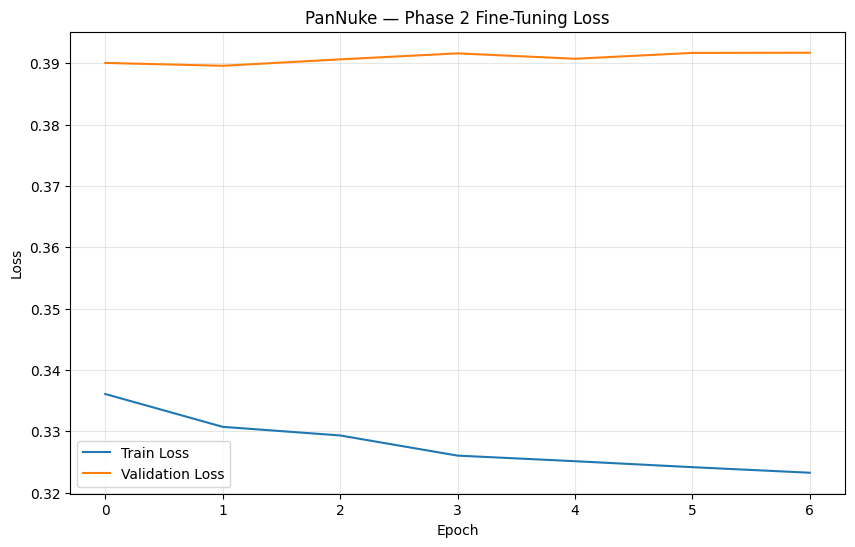

💾 Figure : /kaggle/working/pannuke_output/figures/cell09_phase2_loss.png


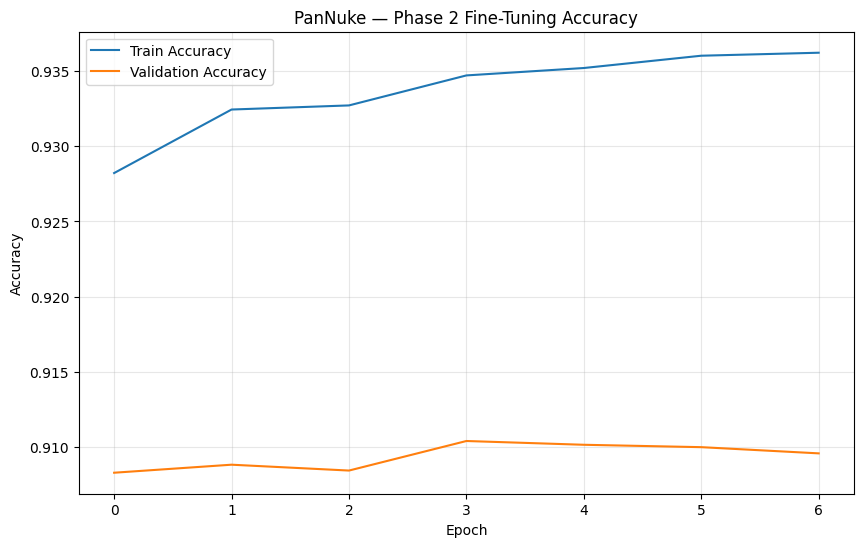

💾 Figure : /kaggle/working/pannuke_output/figures/cell09_phase2_accuracy.png

📊 DICE PAR CLASSE
background         : 0.9606
neoplastic         : 0.5188
inflammatory       : 0.4319
connective         : 0.5040
dead               : 0.3304
epithelial         : 0.2173

🧪 ÉVALUATION VALIDATION
316/316 ━━━━━━━━━━━━━━━━━━━━ 40s 90ms/step - accuracy: 0.9088 - loss: 0.3896 - masked_iou_metric: 0.5455

📊 Résultats validation :
loss                 : 0.389602
compile_metrics      : 0.908837

🎯 RÉSUMÉ CELL 09

✅ Epochs exécutées : 7
🏆 Meilleure epoch : 2
📉 Meilleure val_loss : 0.389602
📊 Dernière accuracy : 0.936212
📊 Dernière val_accuracy : 0.909590

🔓 EfficientNetB0 : partiellement dégelé
🧠 Dernières couches : 30
📉 Learning rate : 1e-05

💾 Meilleur modèle :
/kaggle/working/pannuke_output/models/pannuke_unet_efficientnetb0_phase2_best.keras

📊 Courbes :
/kaggle/working/pannuke_output/figures/cell09_phase2_loss.png
/kaggle/working/pannuke_output/figures/cell09_phase2_accuracy.png

📝 Logs :
/kaggle/

In [11]:
# =============================================================================
# 🧪 CELL 09 — FINE-TUNING EFFICIENTNETB0
# =============================================================================
#
# Phase 2 :
#   - Chargement du meilleur modèle de la Phase 1
#   - Dégel progressif des dernières couches EfficientNetB0
#   - BatchNormalization conservée gelée
#   - Learning rate faible
#   - Loss Weighted CE + Dice
#   - Évaluation Dice / IoU
#   - Sauvegarde du meilleur modèle
# =============================================================================

import os
import gc
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow import keras
from tensorflow.keras import backend as K

print("=" * 80)
print("🧪 CELL 09 — FINE-TUNING EFFICIENTNETB0")
print("=" * 80)

# =============================================================================
# 1. CONFIGURATION
# =============================================================================

NUM_CLASSES = 6
IMAGE_SIZE = (256, 256)
BATCH_SIZE = 8
IGNORE_LABEL = 255

FINE_TUNE_EPOCHS = 15

# Learning rate faible pour le fine-tuning
FINE_TUNE_LR = 1e-5

# Nombre de dernières couches à débloquer
UNFREEZE_LAST_N = 30

MODEL_DIR = "/kaggle/working/pannuke_output/models"
LOG_DIR = "/kaggle/working/pannuke_output/training_logs"
FIG_DIR = "/kaggle/working/pannuke_output/figures"

PHASE1_BEST = os.path.join(
    MODEL_DIR,
    "pannuke_unet_efficientnetb0_phase1_best.keras"
)

PHASE2_BEST = os.path.join(
    MODEL_DIR,
    "pannuke_unet_efficientnetb0_phase2_best.keras"
)

PHASE2_LAST = os.path.join(
    MODEL_DIR,
    "pannuke_unet_efficientnetb0_phase2_last.keras"
)

PHASE2_LOG = os.path.join(
    LOG_DIR,
    "phase2_finetuning.csv"
)

os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(LOG_DIR, exist_ok=True)
os.makedirs(FIG_DIR, exist_ok=True)

print("\n📋 Configuration :")
print(f"   Classes              : {NUM_CLASSES}")
print(f"   Image size           : {IMAGE_SIZE}")
print(f"   Batch size           : {BATCH_SIZE}")
print(f"   Fine-tuning epochs   : {FINE_TUNE_EPOCHS}")
print(f"   Learning rate        : {FINE_TUNE_LR}")
print(f"   Dernières couches    : {UNFREEZE_LAST_N}")
print(f"   Ignore label         : {IGNORE_LABEL}")

# =============================================================================
# 2. CHARGEMENT DU MEILLEUR MODÈLE PHASE 1
# =============================================================================

print("\n" + "=" * 80)
print("📥 CHARGEMENT DU MEILLEUR MODÈLE PHASE 1")
print("=" * 80)

if not os.path.exists(PHASE1_BEST):
    raise FileNotFoundError(
        f"\n❌ Modèle introuvable :\n{PHASE1_BEST}\n"
        "\nVérifie que la CELL 08 s'est terminée correctement."
    )

print(f"\n📁 Modèle : {PHASE1_BEST}")

model = keras.models.load_model(
    PHASE1_BEST,
    compile=False
)

print("✅ Meilleur modèle Phase 1 chargé")

print("\nNom :", model.name)
print("Input :", model.input_shape)
print("Output :", model.output_shape)

# =============================================================================
# 3. RECHERCHE DE L'ENCODER
# =============================================================================

print("\n" + "=" * 80)
print("🔎 RECHERCHE DE L'ENCODER EFFICIENTNETB0")
print("=" * 80)

encoder = None

for layer in model.layers:
    if "EfficientNetB0" in layer.name:
        encoder = layer
        break

if encoder is None:
    # Recherche récursive dans les sous-modèles
    for layer in model.layers:
        if isinstance(layer, keras.Model):
            if "EfficientNetB0" in layer.name:
                encoder = layer
                break

if encoder is None:
    raise ValueError(
        "❌ Impossible de trouver le sous-modèle EfficientNetB0."
    )

print(f"✅ Encoder trouvé : {encoder.name}")
print(f"📦 Nombre total de couches encoder : {len(encoder.layers)}")

# =============================================================================
# 4. GEL DES COUCHES
# =============================================================================

print("\n" + "=" * 80)
print("🔓 DÉGEL PROGRESSIF DE L'ENCODER")
print("=" * 80)

# Tout geler d'abord
for layer in encoder.layers:
    layer.trainable = False

# Débloquer seulement les dernières couches
trainable_count = 0
unfrozen_layers = []

for layer in encoder.layers[-UNFREEZE_LAST_N:]:

    # BatchNormalization reste gelée
    if isinstance(layer, keras.layers.BatchNormalization):
        layer.trainable = False
    else:
        layer.trainable = True
        trainable_count += 1
        unfrozen_layers.append(layer.name)

print(f"\n🔓 Couches débloquées : {trainable_count}")

print("\n📌 Dernières couches entraînables :")

for name in unfrozen_layers[-15:]:
    print(f"   ✓ {name}")

# =============================================================================
# 5. VÉRIFICATION BATCH NORMALIZATION
# =============================================================================

bn_total = 0
bn_trainable = 0

for layer in encoder.layers:

    if isinstance(layer, keras.layers.BatchNormalization):

        bn_total += 1

        if layer.trainable:
            bn_trainable += 1

print("\n📊 BatchNormalization :")
print(f"   Total      : {bn_total}")
print(f"   Trainable  : {bn_trainable}")

if bn_trainable == 0:
    print("✅ Toutes les BatchNormalization restent gelées")
else:
    print("⚠️ Certaines BatchNormalization sont entraînables")

# =============================================================================
# 6. PARAMÈTRES
# =============================================================================

trainable_params = np.sum([
    np.prod(v.shape)
    for v in model.trainable_weights
])

non_trainable_params = np.sum([
    np.prod(v.shape)
    for v in model.non_trainable_weights
])

total_params = trainable_params + non_trainable_params

print("\n" + "=" * 80)
print("📊 PARAMÈTRES APRÈS DÉGEL")
print("=" * 80)

print(f"\nTotal params       : {total_params:,}")
print(f"Trainable params   : {trainable_params:,}")
print(f"Non-trainable      : {non_trainable_params:,}")

# =============================================================================
# 7. LOSS
# =============================================================================

print("\n" + "=" * 80)
print("⚙️ RECONSTRUCTION DE LA LOSS")
print("=" * 80)


CLASS_WEIGHTS = tf.constant(
    [
        0.106797,   # background
        0.331160,   # neoplastic
        0.731730,   # inflammatory
        0.504203,   # connective
        3.706764,   # dead
        0.619346    # epithelial
    ],
    dtype=tf.float32
)


def weighted_categorical_crossentropy(
    y_true,
    y_pred
):
    """
    Weighted Cross Entropy avec support de IGNORE_LABEL=255.
    """

    y_true = tf.cast(y_true, tf.int32)

    valid = tf.not_equal(
        y_true,
        IGNORE_LABEL
    )

    safe_labels = tf.where(
        valid,
        y_true,
        tf.zeros_like(y_true)
    )

    y_one_hot = tf.one_hot(
        safe_labels,
        depth=NUM_CLASSES,
        dtype=tf.float32
    )

    weights = tf.gather(
        CLASS_WEIGHTS,
        safe_labels
    )

    ce = keras.losses.categorical_crossentropy(
        y_one_hot,
        y_pred
    )

    ce = ce * weights

    valid_float = tf.cast(
        valid,
        tf.float32
    )

    return tf.reduce_sum(
        ce * valid_float
    ) / (
        tf.reduce_sum(valid_float) + 1e-7
    )


def multiclass_dice_loss(
    y_true,
    y_pred
):
    """
    Dice Loss multiclasses avec IGNORE_LABEL.
    """

    y_true = tf.cast(
        y_true,
        tf.int32
    )

    valid = tf.not_equal(
        y_true,
        IGNORE_LABEL
    )

    safe_labels = tf.where(
        valid,
        y_true,
        tf.zeros_like(y_true)
    )

    y_true_one_hot = tf.one_hot(
        safe_labels,
        depth=NUM_CLASSES,
        dtype=tf.float32
    )

    valid_float = tf.cast(
        valid,
        tf.float32
    )

    valid_float = tf.expand_dims(
        valid_float,
        axis=-1
    )

    y_true_one_hot *= valid_float
    y_pred *= valid_float

    intersection = tf.reduce_sum(
        y_true_one_hot * y_pred,
        axis=[1, 2]
    )

    denominator = tf.reduce_sum(
        y_true_one_hot + y_pred,
        axis=[1, 2]
    )

    dice = (
        2.0 * intersection + 1e-6
    ) / (
        denominator + 1e-6
    )

    return 1.0 - tf.reduce_mean(dice)


def combined_loss(
    y_true,
    y_pred
):
    ce = weighted_categorical_crossentropy(
        y_true,
        y_pred
    )

    dice = multiclass_dice_loss(
        y_true,
        y_pred
    )

    return (
        0.5 * ce +
        0.5 * dice
    )


print("✅ Weighted Cross-Entropy")
print("✅ Multiclass Dice Loss")
print("✅ Combined Loss = 0.5 CE + 0.5 Dice")

# =============================================================================
# 8. MÉTRIQUES DICE
# =============================================================================

def masked_dice_metric(
    class_id
):

    def dice(
        y_true,
        y_pred
    ):

        y_true = tf.cast(
            y_true,
            tf.int32
        )

        valid = tf.not_equal(
            y_true,
            IGNORE_LABEL
        )

        safe_labels = tf.where(
            valid,
            y_true,
            tf.zeros_like(y_true)
        )

        true_class = tf.cast(
            tf.equal(
                safe_labels,
                class_id
            ),
            tf.float32
        )

        pred_class = tf.cast(
            tf.equal(
                tf.argmax(
                    y_pred,
                    axis=-1
                ),
                class_id
            ),
            tf.float32
        )

        valid = tf.cast(
            valid,
            tf.float32
        )

        true_class *= valid
        pred_class *= valid

        intersection = tf.reduce_sum(
            true_class * pred_class
        )

        denominator = (
            tf.reduce_sum(true_class)
            +
            tf.reduce_sum(pred_class)
        )

        return (
            2.0 * intersection + 1e-6
        ) / (
            denominator + 1e-6
        )

    dice.__name__ = f"dice_class_{class_id}"

    return dice


dice_metrics = [
    masked_dice_metric(i)
    for i in range(NUM_CLASSES)
]

# =============================================================================
# 9. MÉTRIQUE IOU
# =============================================================================

def masked_iou_metric(
    y_true,
    y_pred
):

    y_true = tf.cast(
        y_true,
        tf.int32
    )

    valid = tf.not_equal(
        y_true,
        IGNORE_LABEL
    )

    safe_labels = tf.where(
        valid,
        y_true,
        tf.zeros_like(y_true)
    )

    true_class = tf.one_hot(
        safe_labels,
        depth=NUM_CLASSES
    )

    pred_class = tf.one_hot(
        tf.argmax(
            y_pred,
            axis=-1
        ),
        depth=NUM_CLASSES
    )

    valid = tf.cast(
        valid,
        tf.float32
    )

    valid = tf.expand_dims(
        valid,
        axis=-1
    )

    true_class *= valid
    pred_class *= valid

    intersection = tf.reduce_sum(
        true_class * pred_class,
        axis=[1, 2]
    )

    union = (
        tf.reduce_sum(
            true_class,
            axis=[1, 2]
        )
        +
        tf.reduce_sum(
            pred_class,
            axis=[1, 2]
        )
        -
        intersection
    )

    iou = (
        intersection + 1e-6
    ) / (
        union + 1e-6
    )

    return tf.reduce_mean(iou)


# =============================================================================
# 10. COMPILATION
# =============================================================================

print("\n" + "=" * 80)
print("⚙️ COMPILATION DU MODÈLE FINE-TUNING")
print("=" * 80)

optimizer = keras.optimizers.Adam(
    learning_rate=FINE_TUNE_LR
)

model.compile(
    optimizer=optimizer,
    loss=combined_loss,
    metrics=[
        keras.metrics.SparseCategoricalAccuracy(
            name="accuracy"
        )
    ] + dice_metrics + [
        masked_iou_metric
    ]
)

print("\n✅ Modèle compilé")

print("🔧 Optimizer : Adam")
print(f"🔧 Learning rate : {FINE_TUNE_LR}")
print("🔧 Loss : 0.5 × Weighted CE + 0.5 × Dice")
print("🔧 Encoder : EfficientNetB0 partiellement dégelé")
print(f"🔧 Dernières couches : {UNFREEZE_LAST_N}")
print("🔧 BatchNormalization : gelée")

# =============================================================================
# 11. TEST FORWARD PASS
# =============================================================================

print("\n" + "=" * 80)
print("🔎 TEST FORWARD PASS")
print("=" * 80)

sample_images, sample_masks = next(
    iter(train_dataset)
)

sample_predictions = model(
    sample_images,
    training=False
)

print("\nImages       :", sample_images.shape)
print("Masks        :", sample_masks.shape)
print("Predictions  :", sample_predictions.shape)

print(
    f"Prediction min : "
    f"{tf.reduce_min(sample_predictions).numpy():.6f}"
)

print(
    f"Prediction max : "
    f"{tf.reduce_max(sample_predictions).numpy():.6f}"
)

prediction_sum = tf.reduce_mean(
    tf.reduce_sum(
        sample_predictions,
        axis=-1
    )
).numpy()

print(
    f"Somme softmax moyenne : "
    f"{prediction_sum:.6f}"
)

if abs(prediction_sum - 1.0) < 1e-4:
    print("✅ Softmax valide")
else:
    print("⚠️ Vérifier la sortie softmax")

# =============================================================================
# 12. CALLBACKS
# =============================================================================

print("\n" + "=" * 80)
print("⚙️ CALLBACKS")
print("=" * 80)

callbacks = [

    keras.callbacks.ModelCheckpoint(
        PHASE2_BEST,
        monitor="val_loss",
        mode="min",
        save_best_only=True,
        verbose=1
    ),

    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-7,
        verbose=1
    ),

    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        mode="min",
        restore_best_weights=True,
        verbose=1
    ),

    keras.callbacks.CSVLogger(
        PHASE2_LOG,
        append=False
    )
]

print("✅ ModelCheckpoint")
print("✅ ReduceLROnPlateau")
print("✅ EarlyStopping")
print("✅ CSVLogger")

# =============================================================================
# 13. DATASETS
# =============================================================================

print("\n" + "=" * 80)
print("🔄 PRÉPARATION DES DATASETS")
print("=" * 80)

# Sécurité : éviter de doubler repeat()
train_ds_phase2 = train_dataset.repeat()
val_ds_phase2 = val_dataset.repeat()

STEPS_PER_EPOCH = 332
VALIDATION_STEPS = 316

print("\n✅ train_dataset → repeat()")
print("✅ val_dataset   → repeat()")

print(f"📦 Steps / epoch : {STEPS_PER_EPOCH}")
print(f"📦 Validation steps : {VALIDATION_STEPS}")

# =============================================================================
# 14. ENTRAÎNEMENT
# =============================================================================

print("\n" + "=" * 80)
print("🚀 DÉBUT DU FINE-TUNING — PHASE 2")
print("=" * 80)

print("\n🔓 EfficientNetB0 : PARTIELLEMENT DÉGELÉ")
print(f"🎯 Dernières couches : {UNFREEZE_LAST_N}")
print(f"🎯 Learning rate : {FINE_TUNE_LR}")

print(f"\nEpochs : {FINE_TUNE_EPOCHS}")
print(f"Steps  : {STEPS_PER_EPOCH}")

history_phase2 = model.fit(
    train_ds_phase2,
    validation_data=val_ds_phase2,
    epochs=FINE_TUNE_EPOCHS,
    steps_per_epoch=STEPS_PER_EPOCH,
    validation_steps=VALIDATION_STEPS,
    callbacks=callbacks,
    verbose=1
)

# =============================================================================
# 15. SAUVEGARDE DERNIER MODÈLE
# =============================================================================

print("\n" + "=" * 80)
print("💾 SAUVEGARDE")
print("=" * 80)

model.save(
    PHASE2_LAST
)

print(f"\n✅ Dernier modèle :")
print(PHASE2_LAST)

print("\n✅ Meilleur modèle :")
print(PHASE2_BEST)

print("\n✅ Historique CSV :")
print(PHASE2_LOG)

# =============================================================================
# 16. COURBES D'ENTRAÎNEMENT
# =============================================================================

print("\n" + "=" * 80)
print("📊 GÉNÉRATION DES COURBES")
print("=" * 80)

history_df = pd.DataFrame(
    history_phase2.history
)

# -------------------------------------------------------------------------
# LOSS
# -------------------------------------------------------------------------

plt.figure(
    figsize=(10, 6)
)

plt.plot(
    history_df["loss"],
    label="Train Loss"
)

plt.plot(
    history_df["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title(
    "PanNuke — Phase 2 Fine-Tuning Loss"
)

plt.legend()
plt.grid(alpha=0.3)

loss_fig = os.path.join(
    FIG_DIR,
    "cell09_phase2_loss.png"
)

plt.savefig(
    loss_fig,
    dpi=200,
    bbox_inches="tight"
)

plt.show()
plt.close()

print(f"💾 Figure : {loss_fig}")

# -------------------------------------------------------------------------
# ACCURACY
# -------------------------------------------------------------------------

plt.figure(
    figsize=(10, 6)
)

plt.plot(
    history_df["accuracy"],
    label="Train Accuracy"
)

plt.plot(
    history_df["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title(
    "PanNuke — Phase 2 Fine-Tuning Accuracy"
)

plt.legend()
plt.grid(alpha=0.3)

accuracy_fig = os.path.join(
    FIG_DIR,
    "cell09_phase2_accuracy.png"
)

plt.savefig(
    accuracy_fig,
    dpi=200,
    bbox_inches="tight"
)

plt.show()
plt.close()

print(f"💾 Figure : {accuracy_fig}")

# =============================================================================
# 17. DICE PAR CLASSE
# =============================================================================

print("\n" + "=" * 80)
print("📊 DICE PAR CLASSE")
print("=" * 80)

class_names = [
    "background",
    "neoplastic",
    "inflammatory",
    "connective",
    "dead",
    "epithelial"
]

dice_columns = [
    f"dice_class_{i}"
    for i in range(NUM_CLASSES)
]

dice_val = {}

for i, name in enumerate(class_names):

    column = f"val_dice_class_{i}"

    if column in history_df.columns:
        dice_val[name] = history_df[column].iloc[-1]

for name, value in dice_val.items():

    print(
        f"{name:18s} : "
        f"{value:.4f}"
    )

# =============================================================================
# 18. ÉVALUATION FINALE VALIDATION
# =============================================================================

print("\n" + "=" * 80)
print("🧪 ÉVALUATION VALIDATION")
print("=" * 80)

best_phase2 = keras.models.load_model(
    PHASE2_BEST,
    compile=False
)

best_phase2.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=FINE_TUNE_LR
    ),
    loss=combined_loss,
    metrics=[
        keras.metrics.SparseCategoricalAccuracy(
            name="accuracy"
        )
    ] + [
        masked_iou_metric
    ]
)

validation_results = best_phase2.evaluate(
    val_ds_phase2,
    steps=VALIDATION_STEPS,
    verbose=1
)

print("\n📊 Résultats validation :")

for name, value in zip(
    best_phase2.metrics_names,
    validation_results
):

    print(
        f"{name:20s} : "
        f"{value:.6f}"
    )

# =============================================================================
# 19. RÉSUMÉ
# =============================================================================

print("\n" + "=" * 80)
print("🎯 RÉSUMÉ CELL 09")
print("=" * 80)

best_epoch = (
    np.argmin(
        history_df["val_loss"].values
    ) + 1
)

best_val_loss = history_df[
    "val_loss"
].min()

print(f"\n✅ Epochs exécutées : {len(history_df)}")
print(f"🏆 Meilleure epoch : {best_epoch}")
print(f"📉 Meilleure val_loss : {best_val_loss:.6f}")

print(
    f"📊 Dernière accuracy : "
    f"{history_df['accuracy'].iloc[-1]:.6f}"
)

print(
    f"📊 Dernière val_accuracy : "
    f"{history_df['val_accuracy'].iloc[-1]:.6f}"
)

print("\n🔓 EfficientNetB0 : partiellement dégelé")
print(f"🧠 Dernières couches : {UNFREEZE_LAST_N}")
print(f"📉 Learning rate : {FINE_TUNE_LR}")

print("\n💾 Meilleur modèle :")
print(PHASE2_BEST)

print("\n📊 Courbes :")
print(loss_fig)
print(accuracy_fig)

print("\n📝 Logs :")
print(PHASE2_LOG)

print("\n" + "=" * 80)
print("🏁 CELL 09 TERMINÉE")
print("=" * 80)

print("""
➡️ PROCHAINE ÉTAPE : CELL 10

Évaluation complète sur le TEST :
   • Dice global
   • Dice par classe
   • IoU global
   • IoU par classe
   • matrice de confusion
   • prédictions visuelles
   • comparaison image / vérité terrain / prédiction
   • analyse des erreurs
""")

🧪 CELL 10 — ÉVALUATION COMPLÈTE DU MODÈLE PANNUKE

📋 Configuration :
   Modèle              : /kaggle/working/pannuke_output/models/pannuke_unet_efficientnetb0_phase2_best.keras
   Image size          : (256, 256)
   Batch size          : 8
   Classes             : 6
   Ignore label        : 255

📥 CHARGEMENT DU MEILLEUR MODÈLE PHASE 2

📁 Chargement : /kaggle/working/pannuke_output/models/pannuke_unet_efficientnetb0_phase2_best.keras
✅ Modèle chargé

Nom       : PanNuke_UNet_EfficientNetB0
Input     : (None, 256, 256, 3)
Output    : (None, 256, 256, 6)

🔎 VÉRIFICATION DU DATASET DE VALIDATION
✅ Dataset validation préparé
📦 Nombre de batches : 316

🚀 ÉVALUATION DU MODÈLE
Batch   1/316 | pixels évalués : 524,288
Batch  25/316 | pixels évalués : 13,107,187
Batch  50/316 | pixels évalués : 26,214,211
Batch  75/316 | pixels évalués : 39,321,291
Batch 100/316 | pixels évalués : 52,428,395
Batch 125/316 | pixels évalués : 65,535,519
Batch 150/316 | pixels évalués : 78,642,584
Batch 175/316 | 

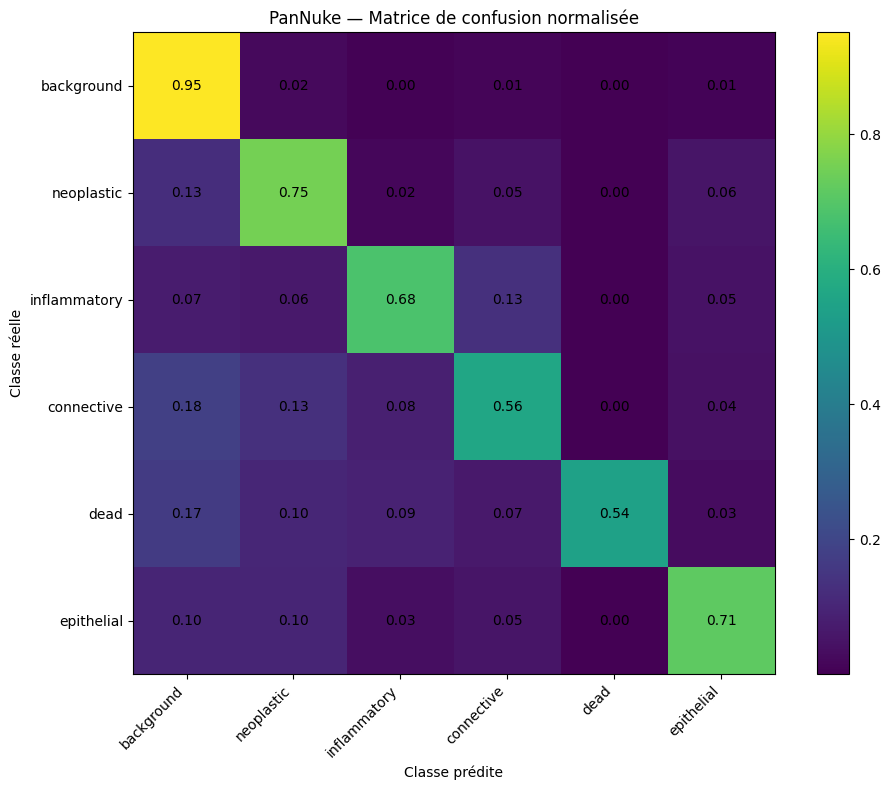


💾 Matrice sauvegardée : /kaggle/working/pannuke_output/figures/cell10_confusion_matrix.png


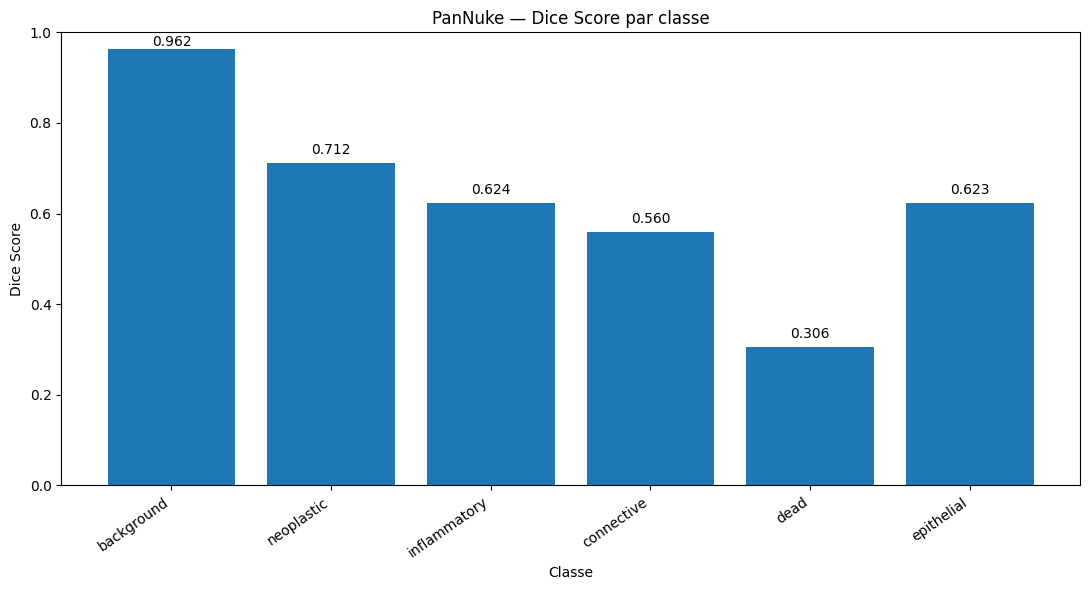


💾 Dice sauvegardé : /kaggle/working/pannuke_output/figures/cell10_dice_per_class.png


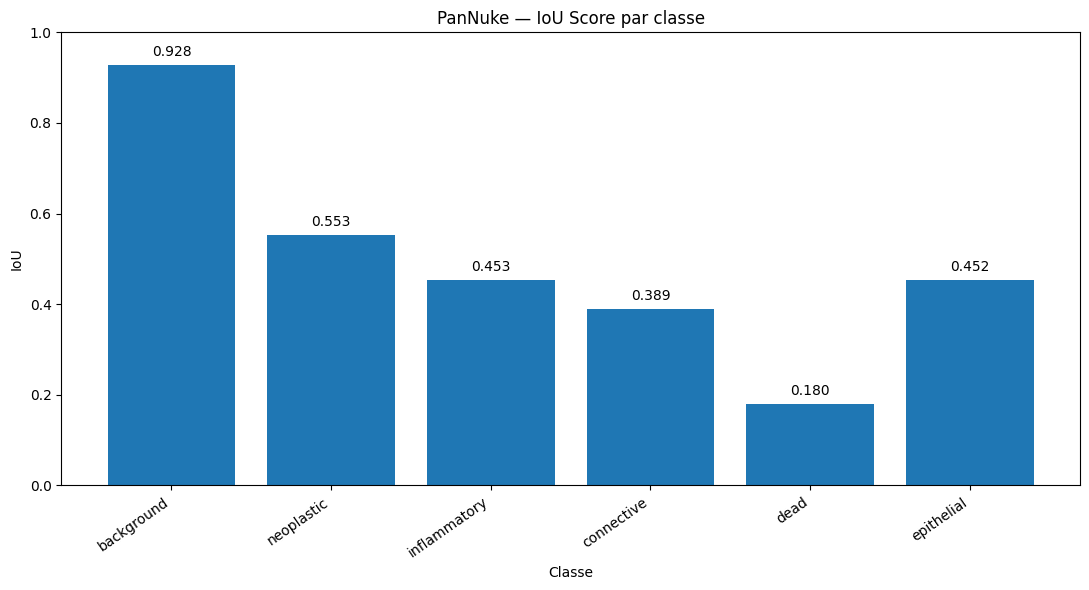


💾 IoU sauvegardé : /kaggle/working/pannuke_output/figures/cell10_iou_per_class.png

💾 RAPPORT

✅ Rapport CSV : /kaggle/working/pannuke_output/reports/cell10_segmentation_metrics.csv
✅ Métriques globales : /kaggle/working/pannuke_output/reports/cell10_global_metrics.csv

🎯 RÉSUMÉ CELL 10

📊 Macro Dice          : 0.6312
📊 Macro IoU           : 0.4926
📊 Foreground Dice     : 0.5649
📊 Foreground IoU      : 0.4056
📊 Foreground F1       : 0.5649

🏆 Dice par classe :
   background      : 0.9625
   neoplastic      : 0.7119
   inflammatory    : 0.6239
   connective      : 0.5600
   dead            : 0.3056
   epithelial      : 0.6230

📁 Fichiers générés :
   ✓ /kaggle/working/pannuke_output/reports/cell10_segmentation_metrics.csv
   ✓ /kaggle/working/pannuke_output/reports/cell10_global_metrics.csv
   ✓ /kaggle/working/pannuke_output/figures/cell10_confusion_matrix.png
   ✓ /kaggle/working/pannuke_output/figures/cell10_dice_per_class.png
   ✓ /kaggle/working/pannuke_output/figures/cell10_iou_p

In [12]:
# ==============================================================================
# 🧪 CELL 10 — ÉVALUATION COMPLÈTE DU MODÈLE PANNUKE
# ==============================================================================
print("=" * 80)
print("🧪 CELL 10 — ÉVALUATION COMPLÈTE DU MODÈLE PANNUKE")
print("=" * 80)

import os
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

# ==============================================================================
# 📋 CONFIGURATION
# ==============================================================================

MODEL_PATH = "/kaggle/working/pannuke_output/models/pannuke_unet_efficientnetb0_phase2_best.keras"

OUTPUT_DIR = "/kaggle/working/pannuke_output"

FIGURES_DIR = os.path.join(OUTPUT_DIR, "figures")
REPORTS_DIR = os.path.join(OUTPUT_DIR, "reports")

os.makedirs(FIGURES_DIR, exist_ok=True)
os.makedirs(REPORTS_DIR, exist_ok=True)

IMAGE_SIZE = (256, 256)
NUM_CLASSES = 6
IGNORE_LABEL = 255

CLASS_NAMES = [
    "background",
    "neoplastic",
    "inflammatory",
    "connective",
    "dead",
    "epithelial"
]

BATCH_SIZE = 8

print()
print("📋 Configuration :")
print(f"   Modèle              : {MODEL_PATH}")
print(f"   Image size          : {IMAGE_SIZE}")
print(f"   Batch size          : {BATCH_SIZE}")
print(f"   Classes             : {NUM_CLASSES}")
print(f"   Ignore label        : {IGNORE_LABEL}")

# ==============================================================================
# 📥 CHARGEMENT DU MEILLEUR MODÈLE
# ==============================================================================

print()
print("=" * 80)
print("📥 CHARGEMENT DU MEILLEUR MODÈLE PHASE 2")
print("=" * 80)

if not os.path.exists(MODEL_PATH):
    raise FileNotFoundError(
        f"❌ Modèle introuvable : {MODEL_PATH}"
    )

print(f"\n📁 Chargement : {MODEL_PATH}")

model = tf.keras.models.load_model(
    MODEL_PATH,
    compile=False
)

print("✅ Modèle chargé")

print()
print(f"Nom       : {model.name}")
print(f"Input     : {model.input_shape}")
print(f"Output    : {model.output_shape}")

# ==============================================================================
# 🔎 VÉRIFICATION DATASET
# ==============================================================================

print()
print("=" * 80)
print("🔎 VÉRIFICATION DU DATASET DE VALIDATION")
print("=" * 80)

val_eval_dataset = val_dataset.take(316)

print("✅ Dataset validation préparé")
print("📦 Nombre de batches :", 316)

# ==============================================================================
# 📊 VARIABLES POUR LES MÉTRIQUES
# ==============================================================================

dice_intersection = np.zeros(NUM_CLASSES, dtype=np.float64)
dice_pred_sum = np.zeros(NUM_CLASSES, dtype=np.float64)
dice_true_sum = np.zeros(NUM_CLASSES, dtype=np.float64)

iou_intersection = np.zeros(NUM_CLASSES, dtype=np.float64)
iou_union = np.zeros(NUM_CLASSES, dtype=np.float64)

true_positive = np.zeros(NUM_CLASSES, dtype=np.float64)
false_positive = np.zeros(NUM_CLASSES, dtype=np.float64)
false_negative = np.zeros(NUM_CLASSES, dtype=np.float64)

confusion = np.zeros(
    (NUM_CLASSES, NUM_CLASSES),
    dtype=np.int64
)

total_valid_pixels = 0

# ==============================================================================
# 🧮 FONCTION DICE
# ==============================================================================

def update_segmentation_metrics(
    y_true,
    y_pred,
    num_classes=NUM_CLASSES,
    ignore_label=IGNORE_LABEL
):
    global dice_intersection
    global dice_pred_sum
    global dice_true_sum
    global iou_intersection
    global iou_union
    global true_positive
    global false_positive
    global false_negative
    global confusion
    global total_valid_pixels

    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    # --------------------------------------------------------------------------
    # Masque des pixels valides
    # --------------------------------------------------------------------------

    valid_mask = (y_true != ignore_label)

    true_flat = y_true[valid_mask].astype(np.int32)
    pred_flat = y_pred[valid_mask].astype(np.int32)

    # Sécurité
    valid_range = (
        (true_flat >= 0) &
        (true_flat < num_classes) &
        (pred_flat >= 0) &
        (pred_flat < num_classes)
    )

    true_flat = true_flat[valid_range]
    pred_flat = pred_flat[valid_range]

    total_valid_pixels += len(true_flat)

    # --------------------------------------------------------------------------
    # Confusion matrix
    # --------------------------------------------------------------------------

    if len(true_flat) > 0:
        cm = confusion_matrix(
            true_flat,
            pred_flat,
            labels=np.arange(num_classes)
        )

        confusion += cm

    # --------------------------------------------------------------------------
    # Métriques par classe
    # --------------------------------------------------------------------------

    for class_id in range(num_classes):

        true_mask = (true_flat == class_id)
        pred_mask = (pred_flat == class_id)

        intersection = np.sum(true_mask & pred_mask)

        true_count = np.sum(true_mask)
        pred_count = np.sum(pred_mask)

        union = true_count + pred_count - intersection

        tp = intersection
        fp = np.sum(pred_mask & ~true_mask)
        fn = np.sum(true_mask & ~pred_mask)

        dice_intersection[class_id] += intersection
        dice_true_sum[class_id] += true_count
        dice_pred_sum[class_id] += pred_count

        iou_intersection[class_id] += intersection
        iou_union[class_id] += union

        true_positive[class_id] += tp
        false_positive[class_id] += fp
        false_negative[class_id] += fn


# ==============================================================================
# 🚀 ÉVALUATION
# ==============================================================================

print()
print("=" * 80)
print("🚀 ÉVALUATION DU MODÈLE")
print("=" * 80)

for batch_idx, batch in enumerate(val_eval_dataset):

    # --------------------------------------------------------------------------
    # Support tuple / dictionary dataset
    # --------------------------------------------------------------------------

    if isinstance(batch, (tuple, list)):
        images = batch[0]
        masks = batch[1]

    elif isinstance(batch, dict):

        if "image" in batch:
            images = batch["image"]
        elif "images" in batch:
            images = batch["images"]
        else:
            raise KeyError(
                "Impossible de trouver les images dans le batch."
            )

        if "mask" in batch:
            masks = batch["mask"]
        elif "masks" in batch:
            masks = batch["masks"]
        else:
            raise KeyError(
                "Impossible de trouver les masques dans le batch."
            )

    else:
        raise TypeError(
            f"Format dataset inattendu : {type(batch)}"
        )

    # --------------------------------------------------------------------------
    # Prédiction
    # --------------------------------------------------------------------------

    predictions = model.predict(
        images,
        verbose=0
    )

    # --------------------------------------------------------------------------
    # Conversion logits/probabilités → classe
    # --------------------------------------------------------------------------

    if predictions.ndim == 4:

        pred_classes = np.argmax(
            predictions,
            axis=-1
        )

    else:
        raise ValueError(
            f"Shape prédictions inattendue : {predictions.shape}"
        )

    # --------------------------------------------------------------------------
    # Conversion masks
    # --------------------------------------------------------------------------

    masks_np = masks.numpy() if tf.is_tensor(masks) else np.asarray(masks)

    # Si masque one-hot
    if masks_np.ndim == 4 and masks_np.shape[-1] == NUM_CLASSES:

        masks_np = np.argmax(
            masks_np,
            axis=-1
        )

    # --------------------------------------------------------------------------
    # Mise à jour métriques
    # --------------------------------------------------------------------------

    update_segmentation_metrics(
        masks_np,
        pred_classes
    )

    # --------------------------------------------------------------------------
    # Progression
    # --------------------------------------------------------------------------

    if (batch_idx + 1) % 25 == 0 or batch_idx == 0:

        print(
            f"Batch {batch_idx + 1:3d}/316 "
            f"| pixels évalués : {total_valid_pixels:,}"
        )

print()
print("✅ Évaluation terminée")

# ==============================================================================
# 📊 CALCUL DES MÉTRIQUES FINALES
# ==============================================================================

print()
print("=" * 80)
print("📊 CALCUL DES MÉTRIQUES")
print("=" * 80)

EPS = 1e-7

# ------------------------------------------------------------------------------
# Dice
# ------------------------------------------------------------------------------

dice_scores = (
    2.0 * dice_intersection
    /
    (
        dice_true_sum
        +
        dice_pred_sum
        +
        EPS
    )
)

# ------------------------------------------------------------------------------
# IoU
# ------------------------------------------------------------------------------

iou_scores = (
    iou_intersection
    /
    (
        iou_union
        +
        EPS
    )
)

# ------------------------------------------------------------------------------
# Precision
# ------------------------------------------------------------------------------

precision_scores = (
    true_positive
    /
    (
        true_positive
        +
        false_positive
        +
        EPS
    )
)

# ------------------------------------------------------------------------------
# Recall
# ------------------------------------------------------------------------------

recall_scores = (
    true_positive
    /
    (
        true_positive
        +
        false_negative
        +
        EPS
    )
)

# ------------------------------------------------------------------------------
# F1
# ------------------------------------------------------------------------------

f1_scores = (
    2.0
    *
    precision_scores
    *
    recall_scores
    /
    (
        precision_scores
        +
        recall_scores
        +
        EPS
    )
)

# ==============================================================================
# 📋 TABLEAU DES RÉSULTATS
# ==============================================================================

results_df = pd.DataFrame({
    "Class": CLASS_NAMES,
    "Dice": dice_scores,
    "IoU": iou_scores,
    "Precision": precision_scores,
    "Recall": recall_scores,
    "F1": f1_scores,
    "TP": true_positive.astype(np.int64),
    "FP": false_positive.astype(np.int64),
    "FN": false_negative.astype(np.int64)
})

print()
print(results_df.to_string(index=False))

# ==============================================================================
# 📈 MACRO / GLOBAL METRICS
# ==============================================================================

# Toutes les classes
macro_dice = np.mean(dice_scores)
macro_iou = np.mean(iou_scores)
macro_precision = np.mean(precision_scores)
macro_recall = np.mean(recall_scores)
macro_f1 = np.mean(f1_scores)

# Classes biologiques uniquement
foreground_indices = np.arange(1, NUM_CLASSES)

foreground_dice = np.mean(
    dice_scores[foreground_indices]
)

foreground_iou = np.mean(
    iou_scores[foreground_indices]
)

foreground_precision = np.mean(
    precision_scores[foreground_indices]
)

foreground_recall = np.mean(
    recall_scores[foreground_indices]
)

foreground_f1 = np.mean(
    f1_scores[foreground_indices]
)

print()
print("=" * 80)
print("🎯 MÉTRIQUES GLOBALES")
print("=" * 80)

print()
print("Toutes les classes :")
print(f"   Macro Dice       : {macro_dice:.4f}")
print(f"   Macro IoU        : {macro_iou:.4f}")
print(f"   Macro Precision  : {macro_precision:.4f}")
print(f"   Macro Recall     : {macro_recall:.4f}")
print(f"   Macro F1         : {macro_f1:.4f}")

print()
print("Classes biologiques uniquement :")
print(f"   Foreground Dice      : {foreground_dice:.4f}")
print(f"   Foreground IoU       : {foreground_iou:.4f}")
print(f"   Foreground Precision : {foreground_precision:.4f}")
print(f"   Foreground Recall    : {foreground_recall:.4f}")
print(f"   Foreground F1        : {foreground_f1:.4f}")

# ==============================================================================
# 📊 MATRICE DE CONFUSION
# ==============================================================================

print()
print("=" * 80)
print("📊 MATRICE DE CONFUSION PIXEL-WISE")
print("=" * 80)

print()

cm_df = pd.DataFrame(
    confusion,
    index=CLASS_NAMES,
    columns=CLASS_NAMES
)

print(cm_df)

# ==============================================================================
# 📊 NORMALISATION MATRICE
# ==============================================================================

cm_normalized = (
    confusion.astype(np.float64)
    /
    (
        confusion.sum(axis=1, keepdims=True)
        +
        EPS
    )
)

# ==============================================================================
# 🎨 VISUALISATION MATRICE DE CONFUSION
# ==============================================================================

plt.figure(figsize=(10, 8))

plt.imshow(
    cm_normalized,
    interpolation="nearest"
)

plt.title(
    "PanNuke — Matrice de confusion normalisée"
)

plt.colorbar()

plt.xticks(
    np.arange(NUM_CLASSES),
    CLASS_NAMES,
    rotation=45,
    ha="right"
)

plt.yticks(
    np.arange(NUM_CLASSES),
    CLASS_NAMES
)

plt.xlabel("Classe prédite")
plt.ylabel("Classe réelle")

for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):

        value = cm_normalized[i, j]

        plt.text(
            j,
            i,
            f"{value:.2f}",
            ha="center",
            va="center"
        )

plt.tight_layout()

cm_path = os.path.join(
    FIGURES_DIR,
    "cell10_confusion_matrix.png"
)

plt.savefig(
    cm_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print()
print(f"💾 Matrice sauvegardée : {cm_path}")

# ==============================================================================
# 📊 GRAPHIQUE DICE PAR CLASSE
# ==============================================================================

plt.figure(figsize=(11, 6))

bars = plt.bar(
    CLASS_NAMES,
    dice_scores
)

plt.title(
    "PanNuke — Dice Score par classe"
)

plt.ylabel("Dice Score")
plt.xlabel("Classe")

plt.ylim(0, 1)

plt.xticks(
    rotation=35,
    ha="right"
)

for bar, value in zip(bars, dice_scores):

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        min(value + 0.02, 0.97),
        f"{value:.3f}",
        ha="center"
    )

plt.tight_layout()

dice_path = os.path.join(
    FIGURES_DIR,
    "cell10_dice_per_class.png"
)

plt.savefig(
    dice_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print()
print(f"💾 Dice sauvegardé : {dice_path}")

# ==============================================================================
# 📊 GRAPHIQUE IOU PAR CLASSE
# ==============================================================================

plt.figure(figsize=(11, 6))

bars = plt.bar(
    CLASS_NAMES,
    iou_scores
)

plt.title(
    "PanNuke — IoU Score par classe"
)

plt.ylabel("IoU")
plt.xlabel("Classe")

plt.ylim(0, 1)

plt.xticks(
    rotation=35,
    ha="right"
)

for bar, value in zip(bars, iou_scores):

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        min(value + 0.02, 0.97),
        f"{value:.3f}",
        ha="center"
    )

plt.tight_layout()

iou_path = os.path.join(
    FIGURES_DIR,
    "cell10_iou_per_class.png"
)

plt.savefig(
    iou_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print()
print(f"💾 IoU sauvegardé : {iou_path}")

# ==============================================================================
# 💾 SAUVEGARDE DU RAPPORT CSV
# ==============================================================================

csv_path = os.path.join(
    REPORTS_DIR,
    "cell10_segmentation_metrics.csv"
)

results_df.to_csv(
    csv_path,
    index=False
)

print()
print("=" * 80)
print("💾 RAPPORT")
print("=" * 80)

print()
print(f"✅ Rapport CSV : {csv_path}")

# ==============================================================================
# 💾 SAUVEGARDE DES MÉTRIQUES GLOBALES
# ==============================================================================

global_metrics = pd.DataFrame({
    "Metric": [
        "Macro Dice",
        "Macro IoU",
        "Macro Precision",
        "Macro Recall",
        "Macro F1",
        "Foreground Dice",
        "Foreground IoU",
        "Foreground Precision",
        "Foreground Recall",
        "Foreground F1"
    ],
    "Value": [
        macro_dice,
        macro_iou,
        macro_precision,
        macro_recall,
        macro_f1,
        foreground_dice,
        foreground_iou,
        foreground_precision,
        foreground_recall,
        foreground_f1
    ]
})

global_csv_path = os.path.join(
    REPORTS_DIR,
    "cell10_global_metrics.csv"
)

global_metrics.to_csv(
    global_csv_path,
    index=False
)

print(f"✅ Métriques globales : {global_csv_path}")

# ==============================================================================
# 🎯 RÉSUMÉ
# ==============================================================================

print()
print("=" * 80)
print("🎯 RÉSUMÉ CELL 10")
print("=" * 80)

print()
print(f"📊 Macro Dice          : {macro_dice:.4f}")
print(f"📊 Macro IoU           : {macro_iou:.4f}")
print(f"📊 Foreground Dice     : {foreground_dice:.4f}")
print(f"📊 Foreground IoU      : {foreground_iou:.4f}")
print(f"📊 Foreground F1       : {foreground_f1:.4f}")

print()
print("🏆 Dice par classe :")

for class_name, dice in zip(CLASS_NAMES, dice_scores):

    print(
        f"   {class_name:<15} : {dice:.4f}"
    )

print()
print("📁 Fichiers générés :")
print(f"   ✓ {csv_path}")
print(f"   ✓ {global_csv_path}")
print(f"   ✓ {cm_path}")
print(f"   ✓ {dice_path}")
print(f"   ✓ {iou_path}")

print()
print("=" * 80)
print("🏁 CELL 10 TERMINÉE")
print("=" * 80)

🧪 CELL 11 — DIAGNOSTIC DES LABELS ET DES PRÉDICTIONS

📋 Configuration :
   Modèle          : /kaggle/working/pannuke_output/models/pannuke_unet_efficientnetb0_phase2_best.keras
   Classes         : 6
   Classes names   : ['background', 'neoplastic', 'inflammatory', 'connective', 'dead', 'epithelial']
   Ignore label    : 255
   Batches test    : 20

📥 CHARGEMENT DU MODÈLE
✅ Modèle chargé
Nom    : PanNuke_UNet_EfficientNetB0
Input  : (None, 256, 256, 3)
Output : (None, 256, 256, 6)

📊 DISTRIBUTION DES CLASSES — GROUND TRUTH
Batch 5/20
Batch 10/20
Batch 15/20
Batch 20/20

📌 Pixels valides analysés : 10,485,750

Classe réelle :
   0 — background      :    8,826,881 pixels (84.1798%)
   1 — neoplastic      :      547,415 pixels ( 5.2206%)
   2 — inflammatory    :       98,548 pixels ( 0.9398%)
   3 — connective      :      344,945 pixels ( 3.2897%)
   4 — dead            :          939 pixels ( 0.0090%)
   5 — epithelial      :      667,022 pixels ( 6.3612%)

🤖 DISTRIBUTION DES CLASSES — P

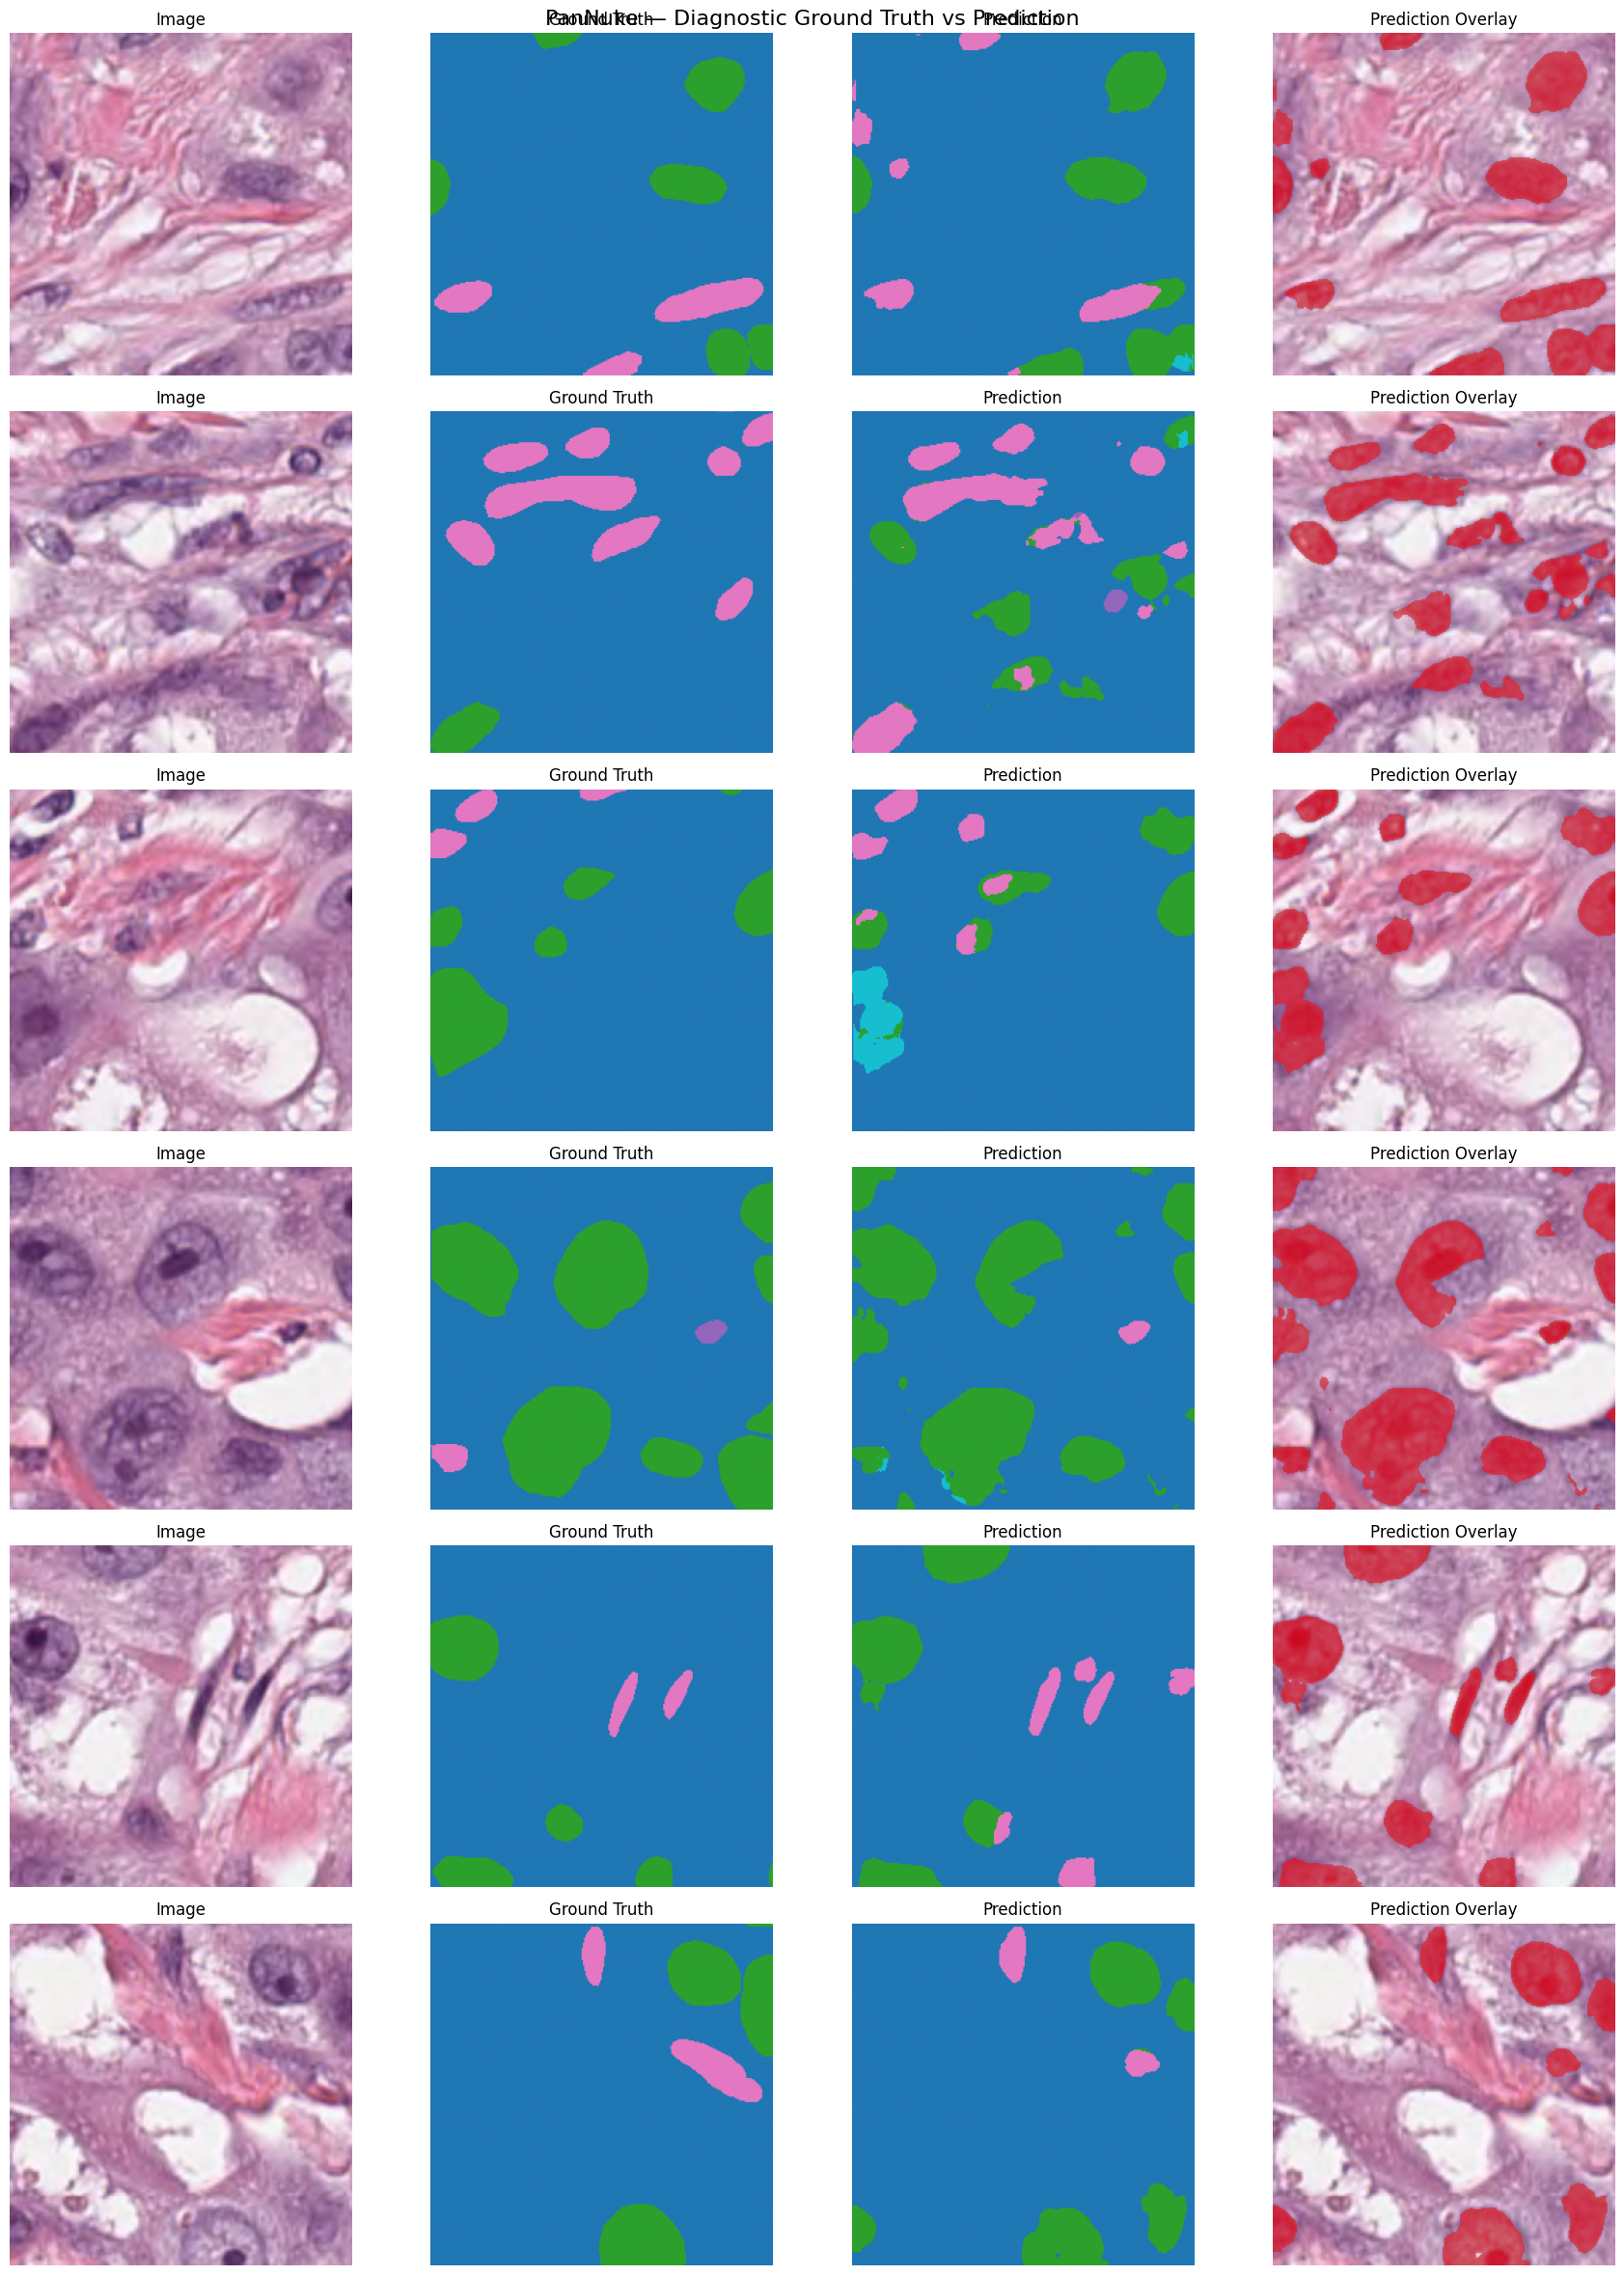


💾 Figure sauvegardée : /kaggle/working/pannuke_output/figures/cell11_diagnostic_visualization.png

🎯 RÉSUMÉ CELL 11

📊 Background prédit : 82.11%
📊 Foreground prédit : 17.89%

📌 Classes prédites :
   background      : 82.1128%
   neoplastic      : 5.4598%
   inflammatory    : 1.3416%
   connective      : 3.7000%
   dead            : 0.0010%
   epithelial      : 7.3848%

🏁 CELL 11 TERMINÉE


In [13]:
# ==============================================================================
# 🧪 CELL 11 — DIAGNOSTIC DES LABELS ET DES PRÉDICTIONS
# ==============================================================================

import os
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from collections import Counter

print("=" * 80)
print("🧪 CELL 11 — DIAGNOSTIC DES LABELS ET DES PRÉDICTIONS")
print("=" * 80)

# ------------------------------------------------------------------------------
# CONFIGURATION
# ------------------------------------------------------------------------------

MODEL_PATH = "/kaggle/working/pannuke_output/models/pannuke_unet_efficientnetb0_phase2_best.keras"

CLASS_NAMES = [
    "background",
    "neoplastic",
    "inflammatory",
    "connective",
    "dead",
    "epithelial"
]

NUM_CLASSES = len(CLASS_NAMES)
IGNORE_LABEL = 255

NUM_BATCHES_DIAGNOSTIC = 20
NUM_VISUALIZATIONS = 6

print("\n📋 Configuration :")
print(f"   Modèle          : {MODEL_PATH}")
print(f"   Classes         : {NUM_CLASSES}")
print(f"   Classes names   : {CLASS_NAMES}")
print(f"   Ignore label    : {IGNORE_LABEL}")
print(f"   Batches test    : {NUM_BATCHES_DIAGNOSTIC}")


# ==============================================================================
# 1. CHARGEMENT DU MODÈLE
# ==============================================================================

print("\n" + "=" * 80)
print("📥 CHARGEMENT DU MODÈLE")
print("=" * 80)

model_diag = tf.keras.models.load_model(
    MODEL_PATH,
    compile=False
)

print("✅ Modèle chargé")
print(f"Nom    : {model_diag.name}")
print(f"Input  : {model_diag.input_shape}")
print(f"Output : {model_diag.output_shape}")


# ==============================================================================
# 2. FONCTION DE RÉCUPÉRATION DES LABELS
# ==============================================================================

def extract_mask(y):
    """
    Supporte plusieurs formats de masques :
      (B,H,W)
      (B,H,W,1)
      (B,H,W,C) one-hot
    """
    
    y = tf.convert_to_tensor(y)

    # Masque (B,H,W,1)
    if len(y.shape) == 4 and y.shape[-1] == 1:
        y = tf.squeeze(y, axis=-1)

    # Masque one-hot (B,H,W,C)
    elif len(y.shape) == 4 and y.shape[-1] == NUM_CLASSES:
        y = tf.argmax(y, axis=-1)

    return tf.cast(y, tf.int32)


# ==============================================================================
# 3. DISTRIBUTION DES CLASSES DANS LES MASQUES RÉELS
# ==============================================================================

print("\n" + "=" * 80)
print("📊 DISTRIBUTION DES CLASSES — GROUND TRUTH")
print("=" * 80)

gt_counter = Counter()

total_valid_pixels = 0

for batch_idx, batch in enumerate(val_dataset.take(NUM_BATCHES_DIAGNOSTIC)):

    images, masks = batch

    masks = extract_mask(masks).numpy()

    valid = masks != IGNORE_LABEL
    labels = masks[valid]

    unique, counts = np.unique(labels, return_counts=True)

    for cls_id, count in zip(unique, counts):
        gt_counter[int(cls_id)] += int(count)

    total_valid_pixels += len(labels)

    if (batch_idx + 1) % 5 == 0:
        print(
            f"Batch {batch_idx + 1}/{NUM_BATCHES_DIAGNOSTIC}"
        )


print("\n📌 Pixels valides analysés :", f"{total_valid_pixels:,}")

print("\nClasse réelle :")

for cls_id in range(NUM_CLASSES):

    count = gt_counter.get(cls_id, 0)

    percentage = (
        100.0 * count / total_valid_pixels
        if total_valid_pixels > 0
        else 0
    )

    print(
        f"   {cls_id} — {CLASS_NAMES[cls_id]:15s} : "
        f"{count:12,} pixels ({percentage:7.4f}%)"
    )


# ==============================================================================
# 4. DISTRIBUTION DES CLASSES PRÉDITES
# ==============================================================================

print("\n" + "=" * 80)
print("🤖 DISTRIBUTION DES CLASSES — PRÉDICTIONS")
print("=" * 80)

pred_counter = Counter()

total_pred_pixels = 0

for batch_idx, batch in enumerate(val_dataset.take(NUM_BATCHES_DIAGNOSTIC)):

    images, masks = batch

    predictions = model_diag.predict(
        images,
        verbose=0
    )

    pred_labels = np.argmax(
        predictions,
        axis=-1
    )

    unique, counts = np.unique(
        pred_labels,
        return_counts=True
    )

    for cls_id, count in zip(unique, counts):
        pred_counter[int(cls_id)] += int(count)

    total_pred_pixels += pred_labels.size

    if (batch_idx + 1) % 5 == 0:
        print(
            f"Batch {batch_idx + 1}/{NUM_BATCHES_DIAGNOSTIC}"
        )


print("\nClasse prédite :")

for cls_id in range(NUM_CLASSES):

    count = pred_counter.get(cls_id, 0)

    percentage = (
        100.0 * count / total_pred_pixels
        if total_pred_pixels > 0
        else 0
    )

    print(
        f"   {cls_id} — {CLASS_NAMES[cls_id]:15s} : "
        f"{count:12,} pixels ({percentage:7.4f}%)"
    )


# ==============================================================================
# 5. COMPARAISON GROUND TRUTH VS PRÉDICTION
# ==============================================================================

print("\n" + "=" * 80)
print("⚖️ COMPARAISON GROUND TRUTH VS PRÉDICTION")
print("=" * 80)

print(
    f"\n{'Classe':15s} | {'GT %':>10s} | {'Pred %':>10s} | {'Écart':>10s}"
)
print("-" * 55)

for cls_id in range(NUM_CLASSES):

    gt_count = gt_counter.get(cls_id, 0)
    pred_count = pred_counter.get(cls_id, 0)

    gt_pct = (
        100.0 * gt_count / total_valid_pixels
        if total_valid_pixels > 0
        else 0
    )

    pred_pct = (
        100.0 * pred_count / total_pred_pixels
        if total_pred_pixels > 0
        else 0
    )

    diff = pred_pct - gt_pct

    print(
        f"{CLASS_NAMES[cls_id]:15s} | "
        f"{gt_pct:9.4f}% | "
        f"{pred_pct:9.4f}% | "
        f"{diff:+9.4f}%"
    )


# ==============================================================================
# 6. VISUALISATION
# ==============================================================================

print("\n" + "=" * 80)
print("🖼️ VISUALISATION IMAGE / GT / PREDICTION")
print("=" * 80)

visual_images = []
visual_masks = []
visual_predictions = []

for batch in val_dataset.take(1):

    images, masks = batch

    predictions = model_diag.predict(
        images,
        verbose=0
    )

    pred_labels = np.argmax(
        predictions,
        axis=-1
    )

    masks = extract_mask(masks).numpy()

    for i in range(
        min(NUM_VISUALIZATIONS, images.shape[0])
    ):

        visual_images.append(
            images[i].numpy()
        )

        visual_masks.append(
            masks[i]
        )

        visual_predictions.append(
            pred_labels[i]
        )

        if len(visual_images) >= NUM_VISUALIZATIONS:
            break


# ------------------------------------------------------------------------------
# AFFICHAGE
# ------------------------------------------------------------------------------

fig, axes = plt.subplots(
    NUM_VISUALIZATIONS,
    4,
    figsize=(18, 4 * NUM_VISUALIZATIONS)
)

if NUM_VISUALIZATIONS == 1:
    axes = np.expand_dims(axes, axis=0)


for i in range(NUM_VISUALIZATIONS):

    image = visual_images[i]
    gt = visual_masks[i]
    pred = visual_predictions[i]

    # Normalisation image
    image_display = image.astype(np.float32)

    if image_display.min() < 0 or image_display.max() > 1:
        image_display -= image_display.min()

        if image_display.max() > 0:
            image_display /= image_display.max()

    # Overlay
    overlay = image_display.copy()

    foreground = pred != 0

    # Rouge pour prédictions foreground
    overlay[foreground, 0] = np.maximum(
        overlay[foreground, 0],
        0.8
    )

    overlay[foreground, 1] *= 0.5
    overlay[foreground, 2] *= 0.5

    # Image
    axes[i, 0].imshow(image_display)
    axes[i, 0].set_title("Image")
    axes[i, 0].axis("off")

    # Ground truth
    axes[i, 1].imshow(
        gt,
        vmin=0,
        vmax=NUM_CLASSES - 1,
        cmap="tab10"
    )

    axes[i, 1].set_title("Ground Truth")
    axes[i, 1].axis("off")

    # Prediction
    axes[i, 2].imshow(
        pred,
        vmin=0,
        vmax=NUM_CLASSES - 1,
        cmap="tab10"
    )

    axes[i, 2].set_title("Prediction")
    axes[i, 2].axis("off")

    # Overlay
    axes[i, 3].imshow(overlay)
    axes[i, 3].set_title("Prediction Overlay")
    axes[i, 3].axis("off")


plt.suptitle(
    "PanNuke — Diagnostic Ground Truth vs Prediction",
    fontsize=16
)

plt.tight_layout()

diagnostic_path = (
    "/kaggle/working/"
    "pannuke_output/figures/"
    "cell11_diagnostic_visualization.png"
)

plt.savefig(
    diagnostic_path,
    dpi=150,
    bbox_inches="tight"
)

plt.show()

print(
    f"\n💾 Figure sauvegardée : {diagnostic_path}"
)


# ==============================================================================
# 7. RÉSULTAT DU DIAGNOSTIC
# ==============================================================================

print("\n" + "=" * 80)
print("🎯 RÉSUMÉ CELL 11")
print("=" * 80)

background_pred_pct = (
    100.0 * pred_counter.get(0, 0) / total_pred_pixels
    if total_pred_pixels > 0
    else 0
)

foreground_pred_pct = 100.0 - background_pred_pct

print(
    f"\n📊 Background prédit : {background_pred_pct:.2f}%"
)

print(
    f"📊 Foreground prédit : {foreground_pred_pct:.2f}%"
)

print("\n📌 Classes prédites :")

for cls_id in range(NUM_CLASSES):

    pred_pct = (
        100.0 *
        pred_counter.get(cls_id, 0) /
        total_pred_pixels
        if total_pred_pixels > 0
        else 0
    )

    print(
        f"   {CLASS_NAMES[cls_id]:15s} : "
        f"{pred_pct:.4f}%"
    )

print("\n" + "=" * 80)
print("🏁 CELL 11 TERMINÉE")
print("=" * 80)

🧪 CELL 12 — DIAGNOSTIC DU COLLAPSE BACKGROUND

📋 Configuration :
   Modèle       : /kaggle/working/pannuke_output/models/pannuke_unet_efficientnetb0_phase2_best.keras
   Classes      : 6
   Ignore label : 255

📥 CHARGEMENT DU MODÈLE
✅ Modèle chargé
   Nom    : PanNuke_UNet_EfficientNetB0
   Input  : (None, 256, 256, 3)
   Output : (None, 256, 256, 6)

🔎 ANALYSE DES PRÉDICTIONS

Images      : (8, 256, 256, 3)
GT masks    : (8, 256, 256)
Predictions : (8, 256, 256, 6)

📊 SOFTMAX
   Min somme : 1.000000
   Max somme : 1.000000
   Moyenne   : 1.000000

📊 PROBABILITÉS MOYENNES PAR CLASSE
0 — background     : 0.821753 (82.1753%)
1 — neoplastic     : 0.131678 (13.1678%)
2 — inflammatory   : 0.001724 (0.1724%)
3 — connective     : 0.031818 (3.1818%)
4 — dead           : 0.001457 (0.1457%)
5 — epithelial     : 0.013503 (1.3503%)

🎯 PROBABILITÉ MAXIMALE OBSERVÉE PAR CLASSE
0 — background     : 0.999361
1 — neoplastic     : 0.999989
2 — inflammatory   : 0.992230
3 — connective     : 0.999905
4 — 

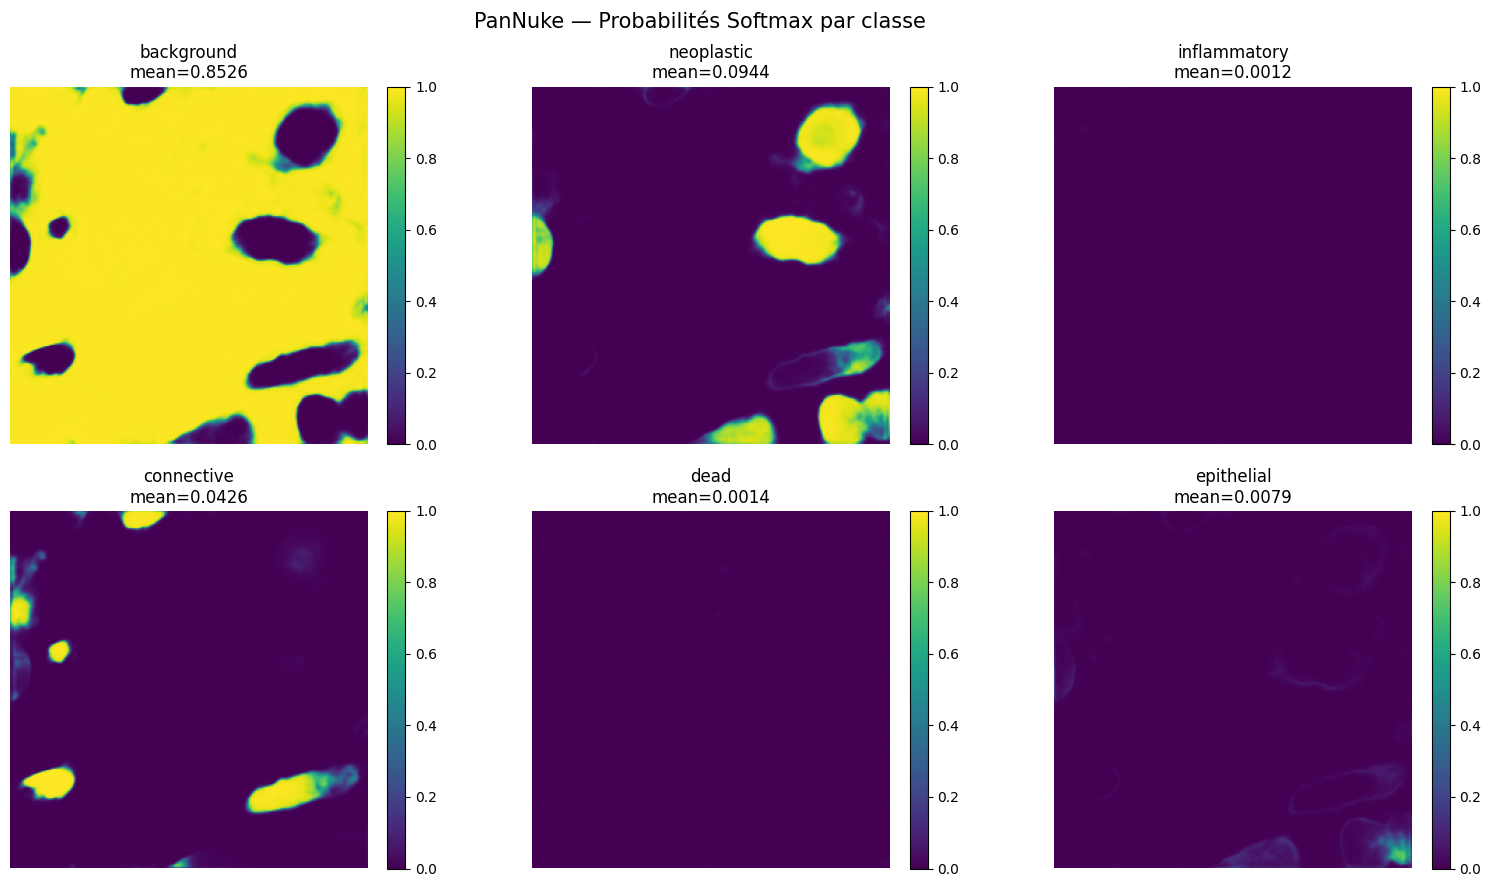


💾 Figure sauvegardée : /kaggle/working/pannuke_output/figures/cell12_class_probabilities.png
💾 Rapport CSV : /kaggle/working/pannuke_output/reports/cell12_diagnostic_background_collapse.csv

🚨 DIAGNOSTIC AUTOMATIQUE

📊 Background prédit : 82.9870%
📊 Foreground prédit : 17.0130%

✅ Pas de collapse background sévère.

Le modèle produit une quantité significative de foreground.
L'analyse peut continuer vers l'optimisation des classes.


🏁 CELL 12 TERMINÉE

➡️ PROCHAINE ÉTAPE :

CELL 13 — CORRECTION DU DÉSÉQUILIBRE DES CLASSES

Objectifs :
   1. recalculer les poids de classes à partir des pixels GT ;
   2. vérifier les labels 0..5 ;
   3. renforcer les classes foreground ;
   4. modifier la loss de segmentation ;
   5. entraîner avec une stratégie anti-background-collapse ;
   6. comparer avec le modèle Phase 2.



In [14]:
# =============================================================================
# 🧪 CELL 12 — DIAGNOSTIC DU COLLAPSE BACKGROUND
# =============================================================================

import os
import numpy as np
import tensorflow as tf
import pandas as pd
import matplotlib.pyplot as plt

print("=" * 80)
print("🧪 CELL 12 — DIAGNOSTIC DU COLLAPSE BACKGROUND")
print("=" * 80)

# =============================================================================
# 1. CONFIGURATION
# =============================================================================

MODEL_PATH = (
    "/kaggle/working/pannuke_output/models/"
    "pannuke_unet_efficientnetb0_phase2_best.keras"
)

CLASS_NAMES = [
    "background",
    "neoplastic",
    "inflammatory",
    "connective",
    "dead",
    "epithelial"
]

NUM_CLASSES = len(CLASS_NAMES)
IGNORE_LABEL = 255

print("\n📋 Configuration :")
print(f"   Modèle       : {MODEL_PATH}")
print(f"   Classes      : {NUM_CLASSES}")
print(f"   Ignore label : {IGNORE_LABEL}")

# =============================================================================
# 2. CHARGEMENT DU MODÈLE
# =============================================================================

print("\n" + "=" * 80)
print("📥 CHARGEMENT DU MODÈLE")
print("=" * 80)

model = tf.keras.models.load_model(
    MODEL_PATH,
    compile=False
)

print("✅ Modèle chargé")
print(f"   Nom    : {model.name}")
print(f"   Input  : {model.input_shape}")
print(f"   Output : {model.output_shape}")

# =============================================================================
# 3. ANALYSE D'UN BATCH
# =============================================================================

print("\n" + "=" * 80)
print("🔎 ANALYSE DES PRÉDICTIONS")
print("=" * 80)

batch_images, batch_masks = next(iter(val_dataset))

predictions = model.predict(
    batch_images,
    verbose=0
)

print(f"\nImages      : {batch_images.shape}")
print(f"GT masks    : {batch_masks.shape}")
print(f"Predictions : {predictions.shape}")

# =============================================================================
# 4. VÉRIFICATION SOFTMAX
# =============================================================================

softmax_sum = np.sum(predictions, axis=-1)

print("\n📊 SOFTMAX")
print(f"   Min somme : {softmax_sum.min():.6f}")
print(f"   Max somme : {softmax_sum.max():.6f}")
print(f"   Moyenne   : {softmax_sum.mean():.6f}")

# =============================================================================
# 5. PROBABILITÉ MOYENNE PAR CLASSE
# =============================================================================

print("\n" + "=" * 80)
print("📊 PROBABILITÉS MOYENNES PAR CLASSE")
print("=" * 80)

mean_probabilities = predictions.mean(axis=(0, 1, 2))

for i, class_name in enumerate(CLASS_NAMES):
    print(
        f"{i} — {class_name:<15}: "
        f"{mean_probabilities[i]:.6f} "
        f"({mean_probabilities[i] * 100:.4f}%)"
    )

# =============================================================================
# 6. PROBABILITÉ MAXIMALE PAR CLASSE
# =============================================================================

print("\n" + "=" * 80)
print("🎯 PROBABILITÉ MAXIMALE OBSERVÉE PAR CLASSE")
print("=" * 80)

max_probabilities = predictions.reshape(-1, NUM_CLASSES).max(axis=0)

for i, class_name in enumerate(CLASS_NAMES):
    print(
        f"{i} — {class_name:<15}: "
        f"{max_probabilities[i]:.6f}"
    )

# =============================================================================
# 7. DISTRIBUTION GT DU BATCH
# =============================================================================

print("\n" + "=" * 80)
print("📌 DISTRIBUTION GROUND TRUTH — BATCH")
print("=" * 80)

gt = batch_masks.numpy()

gt_valid = gt[gt != IGNORE_LABEL]

gt_counts = np.bincount(
    gt_valid.astype(np.int32),
    minlength=NUM_CLASSES
)

gt_total = gt_counts.sum()

for i, class_name in enumerate(CLASS_NAMES):
    percentage = (
        100.0 * gt_counts[i] / gt_total
        if gt_total > 0
        else 0.0
    )

    print(
        f"{i} — {class_name:<15}: "
        f"{gt_counts[i]:>10,} pixels "
        f"({percentage:>8.4f}%)"
    )

# =============================================================================
# 8. DISTRIBUTION DES PRÉDICTIONS
# =============================================================================

print("\n" + "=" * 80)
print("📌 DISTRIBUTION DES PRÉDICTIONS — BATCH")
print("=" * 80)

pred_classes = np.argmax(
    predictions,
    axis=-1
)

pred_counts = np.bincount(
    pred_classes.reshape(-1),
    minlength=NUM_CLASSES
)

pred_total = pred_counts.sum()

for i, class_name in enumerate(CLASS_NAMES):
    percentage = (
        100.0 * pred_counts[i] / pred_total
        if pred_total > 0
        else 0.0
    )

    print(
        f"{i} — {class_name:<15}: "
        f"{pred_counts[i]:>10,} pixels "
        f"({percentage:>8.4f}%)"
    )

# =============================================================================
# 9. FOREGROUND ANALYSIS
# =============================================================================

print("\n" + "=" * 80)
print("🔬 ANALYSE FOREGROUND")
print("=" * 80)

foreground_prob = 1.0 - predictions[..., 0]

print(
    f"Foreground probability moyenne : "
    f"{foreground_prob.mean():.8f}"
)

print(
    f"Foreground probability max     : "
    f"{foreground_prob.max():.8f}"
)

print(
    f"Pixels avec foreground > 0.10 : "
    f"{np.sum(foreground_prob > 0.10):,}"
)

print(
    f"Pixels avec foreground > 0.25 : "
    f"{np.sum(foreground_prob > 0.25):,}"
)

print(
    f"Pixels avec foreground > 0.50 : "
    f"{np.sum(foreground_prob > 0.50):,}"
)

print(
    f"Pixels avec foreground > 0.75 : "
    f"{np.sum(foreground_prob > 0.75):,}"
)

# =============================================================================
# 10. ANALYSE DES PIXELS FOREGROUND GT
# =============================================================================

print("\n" + "=" * 80)
print("🎯 CONFIANCE DU MODÈLE SUR LES PIXELS FOREGROUND RÉELS")
print("=" * 80)

foreground_mask = (
    (gt != 0) &
    (gt != IGNORE_LABEL)
)

foreground_indices = np.where(foreground_mask)

if len(foreground_indices[0]) > 0:

    foreground_predictions = predictions[
        foreground_indices[0],
        foreground_indices[1],
        foreground_indices[2]
    ]

    foreground_gt = gt[foreground_indices]

    gt_class_probabilities = (
        foreground_predictions[
            np.arange(len(foreground_gt)),
            foreground_gt
        ]
    )

    print(
        f"Nombre pixels foreground GT : "
        f"{len(foreground_gt):,}"
    )

    print(
        f"Probabilité moyenne de la vraie classe : "
        f"{gt_class_probabilities.mean():.6f}"
    )

    print(
        f"Probabilité médiane de la vraie classe : "
        f"{np.median(gt_class_probabilities):.6f}"
    )

    print(
        f"Probabilité max de la vraie classe : "
        f"{gt_class_probabilities.max():.6f}"
    )

    print(
        f"Pixels où P(vraie classe) > 0.5 : "
        f"{np.sum(gt_class_probabilities > 0.5):,}"
    )

else:

    print("⚠️ Aucun pixel foreground dans ce batch.")

# =============================================================================
# 11. CONFUSION DU BATCH
# =============================================================================

print("\n" + "=" * 80)
print("📊 MATRICE DE CONFUSION — BATCH")
print("=" * 80)

valid_mask = (
    (gt != IGNORE_LABEL) &
    (gt >= 0) &
    (gt < NUM_CLASSES)
)

gt_flat = gt[valid_mask].astype(np.int32)
pred_flat = pred_classes[valid_mask].astype(np.int32)

cm = tf.math.confusion_matrix(
    gt_flat,
    pred_flat,
    num_classes=NUM_CLASSES
).numpy()

cm_df = pd.DataFrame(
    cm,
    index=CLASS_NAMES,
    columns=CLASS_NAMES
)

print(cm_df)

# =============================================================================
# 12. TAUX DE RECONNAISSANCE PAR CLASSE
# =============================================================================

print("\n" + "=" * 80)
print("🎯 RECALL PAR CLASSE — BATCH")
print("=" * 80)

for i, class_name in enumerate(CLASS_NAMES):

    tp = cm[i, i]
    total_real = cm[i].sum()

    recall = (
        tp / total_real
        if total_real > 0
        else 0.0
    )

    print(
        f"{class_name:<15}: "
        f"{recall:.6f}"
    )

# =============================================================================
# 13. VISUALISATION DES PROBABILITÉS
# =============================================================================

print("\n" + "=" * 80)
print("📊 GÉNÉRATION DU DIAGNOSTIC")
print("=" * 80)

fig, axes = plt.subplots(
    2,
    3,
    figsize=(16, 9)
)

axes = axes.flatten()

for i, class_name in enumerate(CLASS_NAMES):

    im = axes[i].imshow(
        predictions[0, :, :, i],
        vmin=0,
        vmax=1
    )

    axes[i].set_title(
        f"{class_name}\n"
        f"mean={predictions[0, :, :, i].mean():.4f}"
    )

    axes[i].axis("off")

    plt.colorbar(
        im,
        ax=axes[i],
        fraction=0.046,
        pad=0.04
    )

plt.suptitle(
    "PanNuke — Probabilités Softmax par classe",
    fontsize=15
)

plt.tight_layout()

probability_path = (
    "/kaggle/working/pannuke_output/figures/"
    "cell12_class_probabilities.png"
)

plt.savefig(
    probability_path,
    dpi=150,
    bbox_inches="tight"
)

plt.show()

print(
    f"\n💾 Figure sauvegardée : {probability_path}"
)

# =============================================================================
# 14. SAUVEGARDE DU RAPPORT
# =============================================================================

diagnostic = pd.DataFrame({
    "class": CLASS_NAMES,
    "gt_pixels": gt_counts,
    "gt_percent": 100.0 * gt_counts / gt_total,
    "pred_pixels": pred_counts,
    "pred_percent": 100.0 * pred_counts / pred_total,
    "mean_probability": mean_probabilities,
    "max_probability": max_probabilities
})

diagnostic_path = (
    "/kaggle/working/pannuke_output/reports/"
    "cell12_diagnostic_background_collapse.csv"
)

os.makedirs(
    os.path.dirname(diagnostic_path),
    exist_ok=True
)

diagnostic.to_csv(
    diagnostic_path,
    index=False
)

print(
    f"💾 Rapport CSV : {diagnostic_path}"
)

# =============================================================================
# 15. DIAGNOSTIC AUTOMATIQUE
# =============================================================================

background_percentage = (
    100.0 * pred_counts[0] / pred_total
)

foreground_percentage = (
    100.0 - background_percentage
)

print("\n" + "=" * 80)
print("🚨 DIAGNOSTIC AUTOMATIQUE")
print("=" * 80)

print(
    f"\n📊 Background prédit : "
    f"{background_percentage:.4f}%"
)

print(
    f"📊 Foreground prédit : "
    f"{foreground_percentage:.4f}%"
)

if background_percentage > 99.0:

    print("""
❌ COLLAPSE BACKGROUND CONFIRMÉ

Le modèle prédit presque exclusivement la classe background.

Conséquences :
   • Dice foreground très faible
   • IoU foreground très faible
   • classes neoplastic/connective/dead/epithelial non détectées
   • accuracy globale trompeuse

⛔ NE PAS lancer immédiatement un nouveau fine-tuning.

La prochaine étape doit corriger le déséquilibre d'apprentissage
et vérifier la construction des labels / loss.
""")

elif background_percentage > 95.0:

    print("""
⚠️ FORTE DOMINATION DU BACKGROUND

Le modèle commence à apprendre le foreground mais reste fortement
biaisé vers background.

Une correction de la stratégie de loss et de l'échantillonnage
est nécessaire avant de poursuivre.
""")

else:

    print("""
✅ Pas de collapse background sévère.

Le modèle produit une quantité significative de foreground.
L'analyse peut continuer vers l'optimisation des classes.
""")

print("\n" + "=" * 80)
print("🏁 CELL 12 TERMINÉE")
print("=" * 80)

print("""
➡️ PROCHAINE ÉTAPE :

CELL 13 — CORRECTION DU DÉSÉQUILIBRE DES CLASSES

Objectifs :
   1. recalculer les poids de classes à partir des pixels GT ;
   2. vérifier les labels 0..5 ;
   3. renforcer les classes foreground ;
   4. modifier la loss de segmentation ;
   5. entraîner avec une stratégie anti-background-collapse ;
   6. comparer avec le modèle Phase 2.
""")

In [ ]:
# =============================================================================
# 🧪 CELL 13 — CORRECTION DU DÉSÉQUILIBRE DES CLASSES
# =============================================================================

import os
import csv
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras

print("=" * 80)
print("🧪 CELL 13 — CORRECTION DU DÉSÉQUILIBRE DES CLASSES")
print("=" * 80)

# =============================================================================
# 📋 CONFIGURATION
# =============================================================================

MODEL_PATH = (
    "/kaggle/working/pannuke_output/models/"
    "pannuke_unet_efficientnetb0_phase2_best.keras"
)

OUTPUT_DIR = "/kaggle/working/pannuke_output"

REPORT_DIR = os.path.join(
    OUTPUT_DIR,
    "reports"
)

MODEL_DIR = os.path.join(
    OUTPUT_DIR,
    "models"
)

LOG_DIR = os.path.join(
    OUTPUT_DIR,
    "training_logs"
)

os.makedirs(REPORT_DIR, exist_ok=True)
os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(LOG_DIR, exist_ok=True)

NUM_CLASSES = 6
IMAGE_SIZE = (256, 256)
BATCH_SIZE = 8
EPOCHS = 15

LEARNING_RATE = 2e-6
IGNORE_LABEL = 255

CLASS_NAMES = [
    "background",
    "neoplastic",
    "inflammatory",
    "connective",
    "dead",
    "epithelial"
]

TRAIN_STEPS = 332
VAL_STEPS = 316

print("\n📋 Configuration :")
print(f"Modèle initial      : {MODEL_PATH}")
print(f"Classes             : {NUM_CLASSES}")
print(f"Image size          : {IMAGE_SIZE}")
print(f"Batch size          : {BATCH_SIZE}")
print(f"Epochs              : {EPOCHS}")
print(f"Learning rate       : {LEARNING_RATE}")
print(f"Ignore label        : {IGNORE_LABEL}")
print(f"Train steps         : {TRAIN_STEPS}")
print(f"Validation steps    : {VAL_STEPS}")


# =============================================================================
# 📥 CHARGEMENT DU MODÈLE PHASE 2
# =============================================================================

print("\n" + "=" * 80)
print("📥 CHARGEMENT DU MODÈLE PHASE 2")
print("=" * 80)

model = keras.models.load_model(
    MODEL_PATH,
    compile=False
)

print("✅ Modèle Phase 2 chargé")

print(f"Nom    : {model.name}")
print(f"Input  : {model.input_shape}")
print(f"Output : {model.output_shape}")


# =============================================================================
# 🔎 VÉRIFICATION DES LABELS
# =============================================================================

print("\n" + "=" * 80)
print("🔎 VÉRIFICATION DES LABELS")
print("=" * 80)

sample_images, sample_masks = next(iter(train_dataset))

unique_labels = np.unique(sample_masks.numpy())

print("\nLabels trouvés dans un batch :")
print(unique_labels)

invalid_labels = unique_labels[
    ~np.isin(unique_labels, list(range(NUM_CLASSES)) + [IGNORE_LABEL])
]

if len(invalid_labels) > 0:
    print("❌ Labels invalides :", invalid_labels)
    raise ValueError(
        f"Labels invalides détectés : {invalid_labels}"
    )

print("✅ Aucun label invalide")


# =============================================================================
# 📊 CALCUL DE LA DISTRIBUTION DES CLASSES
# =============================================================================

print("\n" + "=" * 80)
print("📊 CALCUL DE LA DISTRIBUTION DES CLASSES")
print("=" * 80)

class_counts = np.zeros(
    NUM_CLASSES,
    dtype=np.int64
)

print(
    f"\nAnalyse de {TRAIN_STEPS} batches du dataset "
    "d'entraînement..."
)

for batch_idx, (_, masks) in enumerate(train_dataset.take(TRAIN_STEPS)):

    masks_np = masks.numpy().astype(np.int32)

    valid_mask = masks_np != IGNORE_LABEL

    valid_labels = masks_np[valid_mask]

    counts = np.bincount(
        valid_labels,
        minlength=NUM_CLASSES
    )

    class_counts += counts

    if (batch_idx + 1) % 50 == 0:
        print(f"Batch {batch_idx + 1}/{TRAIN_STEPS}")


# =============================================================================
# 📈 DISTRIBUTION
# =============================================================================

total_valid_pixels = np.sum(class_counts)

class_frequencies = (
    class_counts / total_valid_pixels
)

print("\n📌 Distribution finale :")

for i in range(NUM_CLASSES):

    print(
        f"{i} — {CLASS_NAMES[i]:14s} : "
        f"{class_counts[i]:10d} pixels "
        f"({class_frequencies[i] * 100:7.4f}%)"
    )


# =============================================================================
# ⚖️ CALCUL DES POIDS
# =============================================================================
#
# Formule :
#
# weight_i = median_frequency / frequency_i
#
# Puis plafonnement pour éviter des gradients trop agressifs.
#
# =============================================================================

median_frequency = np.median(
    class_frequencies[class_frequencies > 0]
)

raw_weights = (
    median_frequency /
    np.maximum(class_frequencies, 1e-8)
)

# Plafonnement
MAX_CLASS_WEIGHT = 4.0
MIN_CLASS_WEIGHT = 0.25

class_weights = np.clip(
    raw_weights,
    MIN_CLASS_WEIGHT,
    MAX_CLASS_WEIGHT
)

# Background volontairement limité
class_weights[0] = 0.25


print("\n⚖️ Poids calculés :")

for i in range(NUM_CLASSES):

    print(
        f"{CLASS_NAMES[i]:14s} : "
        f"frequency={class_frequencies[i]:.8f} "
        f"weight={class_weights[i]:.4f}"
    )


# =============================================================================
# 💾 SAUVEGARDE DES POIDS
# =============================================================================

weights_df = pd.DataFrame({
    "class_id": np.arange(NUM_CLASSES),
    "class_name": CLASS_NAMES,
    "pixel_count": class_counts,
    "frequency": class_frequencies,
    "class_weight": class_weights
})

weights_path = os.path.join(
    REPORT_DIR,
    "cell13_class_weights.csv"
)

weights_df.to_csv(
    weights_path,
    index=False
)

print(
    f"\n💾 Poids sauvegardés : {weights_path}"
)


# =============================================================================
# 🔥 TENSOR DES POIDS
# =============================================================================

CLASS_WEIGHTS_TF = tf.constant(
    class_weights,
    dtype=tf.float32
)


# =============================================================================
# 🧠 OUTILS LOSS
# =============================================================================

def prepare_labels(y_true):
    """
    Prépare les labels pour éviter que 255
    ne soit utilisé dans tf.gather.
    """

    y_true = tf.cast(
        y_true,
        tf.int32
    )

    valid_mask = tf.not_equal(
        y_true,
        IGNORE_LABEL
    )

    safe_labels = tf.where(
        valid_mask,
        y_true,
        tf.zeros_like(y_true)
    )

    return safe_labels, valid_mask


# =============================================================================
# ⚖️ WEIGHTED CROSS ENTROPY
# =============================================================================

def weighted_cross_entropy(
    y_true,
    y_pred
):

    safe_labels, valid_mask = prepare_labels(
        y_true
    )

    # ---------------------------------------------------------
    # Sparse CE
    # Résultat : (B,H,W)
    # ---------------------------------------------------------

    ce = tf.keras.losses.sparse_categorical_crossentropy(
        safe_labels,
        y_pred,
        from_logits=False
    )

    # ---------------------------------------------------------
    # Poids de classe
    # Résultat : (B,H,W)
    # ---------------------------------------------------------

    pixel_weights = tf.gather(
        CLASS_WEIGHTS_TF,
        safe_labels
    )

    # ---------------------------------------------------------
    # Masque
    # ---------------------------------------------------------

    valid_mask_f = tf.cast(
        valid_mask,
        tf.float32
    )

    weighted_ce = (
        ce *
        pixel_weights *
        valid_mask_f
    )

    denominator = tf.reduce_sum(
        valid_mask_f
    ) + 1e-7

    return (
        tf.reduce_sum(weighted_ce)
        / denominator
    )


# =============================================================================
# 🔥 WEIGHTED FOCAL LOSS
# =============================================================================

def weighted_focal_loss(
    y_true,
    y_pred,
    gamma=2.0
):

    safe_labels, valid_mask = prepare_labels(
        y_true
    )

    # ---------------------------------------------------------
    # CE PAR PIXEL
    # Shape : (B,H,W)
    # ---------------------------------------------------------

    ce = tf.keras.losses.sparse_categorical_crossentropy(
        safe_labels,
        y_pred,
        from_logits=False
    )

    # ---------------------------------------------------------
    # PROBABILITÉ DE LA VRAIE CLASSE
    #
    # IMPORTANT :
    # on récupère UNE probabilité par pixel.
    #
    # Shape : (B,H,W)
    # ---------------------------------------------------------

    one_hot = tf.one_hot(
        safe_labels,
        depth=NUM_CLASSES,
        dtype=tf.float32
    )

    p_t = tf.reduce_sum(
        y_pred * one_hot,
        axis=-1
    )

    p_t = tf.clip_by_value(
        p_t,
        1e-7,
        1.0
    )

    # ---------------------------------------------------------
    # FOCAL FACTOR
    #
    # Shape : (B,H,W)
    # ---------------------------------------------------------

    focal_factor = tf.pow(
        1.0 - p_t,
        gamma
    )

    # ---------------------------------------------------------
    # POIDS DE CLASSE
    #
    # Shape : (B,H,W)
    # ---------------------------------------------------------

    pixel_weights = tf.gather(
        CLASS_WEIGHTS_TF,
        safe_labels
    )

    valid_mask_f = tf.cast(
        valid_mask,
        tf.float32
    )

    # ---------------------------------------------------------
    # LOSS
    # ---------------------------------------------------------

    focal = (
        focal_factor
        * ce
        * pixel_weights
        * valid_mask_f
    )

    denominator = (
        tf.reduce_sum(valid_mask_f)
        + 1e-7
    )

    return (
        tf.reduce_sum(focal)
        / denominator
    )


# =============================================================================
# 🎯 FOREGROUND MULTICLASS DICE LOSS
# =============================================================================

def foreground_dice_loss(
    y_true,
    y_pred
):

    safe_labels, valid_mask = prepare_labels(
        y_true
    )

    y_true_one_hot = tf.one_hot(
        safe_labels,
        depth=NUM_CLASSES,
        dtype=tf.float32
    )

    valid_mask_f = tf.cast(
        valid_mask,
        tf.float32
    )

    valid_mask_f = tf.expand_dims(
        valid_mask_f,
        axis=-1
    )

    # ---------------------------------------------------------
    # Ignore pixels
    # ---------------------------------------------------------

    y_true_one_hot *= valid_mask_f
    y_pred_masked = y_pred * valid_mask_f

    # ---------------------------------------------------------
    # FOREGROUND UNIQUEMENT
    # Classes 1..5
    # ---------------------------------------------------------

    y_true_fg = y_true_one_hot[..., 1:]
    y_pred_fg = y_pred_masked[..., 1:]

    intersection = tf.reduce_sum(
        y_true_fg * y_pred_fg,
        axis=[0, 1, 2]
    )

    denominator = (
        tf.reduce_sum(
            y_true_fg,
            axis=[0, 1, 2]
        )
        +
        tf.reduce_sum(
            y_pred_fg,
            axis=[0, 1, 2]
        )
    )

    dice = (
        (2.0 * intersection + 1e-6)
        /
        (denominator + 1e-6)
    )

    # ---------------------------------------------------------
    # Dice loss
    # ---------------------------------------------------------

    return 1.0 - tf.reduce_mean(dice)


# =============================================================================
# 🧠 LOSS COMBINÉE ANTI-BACKGROUND-COLLAPSE
# =============================================================================

def anti_collapse_loss(
    y_true,
    y_pred
):

    weighted_ce = weighted_cross_entropy(
        y_true,
        y_pred
    )

    focal = weighted_focal_loss(
        y_true,
        y_pred,
        gamma=2.0
    )

    dice = foreground_dice_loss(
        y_true,
        y_pred
    )

    total_loss = (
        0.40 * weighted_ce
        +
        0.30 * focal
        +
        0.30 * dice
    )

    return total_loss


print("\n" + "=" * 80)
print("⚙️ LOSS ANTI-BACKGROUND-COLLAPSE")
print("=" * 80)

print("✅ Weighted Cross-Entropy")
print("✅ Weighted Focal Loss")
print("✅ Foreground Multiclass Dice")
print("✅ Combined Anti-Collapse Loss")

print("0.40 × Weighted CE")
print("0.30 × Focal")
print("0.30 × Foreground Dice")


# =============================================================================
# 📊 MÉTRIQUE FOREGROUND DICE
# =============================================================================

def foreground_dice_metric(
    y_true,
    y_pred
):

    safe_labels, valid_mask = prepare_labels(
        y_true
    )

    y_true_one_hot = tf.one_hot(
        safe_labels,
        depth=NUM_CLASSES,
        dtype=tf.float32
    )

    valid_mask_f = tf.cast(
        valid_mask,
        tf.float32
    )

    valid_mask_f = tf.expand_dims(
        valid_mask_f,
        axis=-1
    )

    y_true_one_hot *= valid_mask_f
    y_pred *= valid_mask_f

    # foreground uniquement
    y_true_fg = y_true_one_hot[..., 1:]
    y_pred_fg = y_pred[..., 1:]

    intersection = tf.reduce_sum(
        y_true_fg * y_pred_fg,
        axis=[0, 1, 2]
    )

    denominator = (
        tf.reduce_sum(
            y_true_fg,
            axis=[0, 1, 2]
        )
        +
        tf.reduce_sum(
            y_pred_fg,
            axis=[0, 1, 2]
        )
    )

    dice = (
        2.0 * intersection + 1e-6
    ) / (
        denominator + 1e-6
    )

    return tf.reduce_mean(dice)


# =============================================================================
# 📊 FOREGROUND PIXEL RECALL
# =============================================================================

def foreground_recall_metric(
    y_true,
    y_pred
):

    safe_labels, valid_mask = prepare_labels(
        y_true
    )

    pred_labels = tf.argmax(
        y_pred,
        axis=-1,
        output_type=tf.int32
    )

    true_fg = tf.logical_and(
        tf.not_equal(
            safe_labels,
            0
        ),
        valid_mask
    )

    pred_fg = tf.not_equal(
        pred_labels,
        0
    )

    tp = tf.reduce_sum(
        tf.cast(
            tf.logical_and(
                true_fg,
                pred_fg
            ),
            tf.float32
        )
    )

    fn = tf.reduce_sum(
        tf.cast(
            tf.logical_and(
                true_fg,
                tf.logical_not(pred_fg)
            ),
            tf.float32
        )
    )

    return tp / (
        tp + fn + 1e-7
    )


# =============================================================================
# ⚙️ COMPILATION
# =============================================================================

print("\n" + "=" * 80)
print("⚙️ COMPILATION DU MODÈLE")
print("=" * 80)

optimizer = keras.optimizers.Adam(
    learning_rate=LEARNING_RATE
)

model.compile(
    optimizer=optimizer,
    loss=anti_collapse_loss,
    metrics=[
        foreground_dice_metric,
        foreground_recall_metric
    ]
)

print("✅ Modèle compilé")
print(f"Optimizer : Adam")
print(f"LR        : {LEARNING_RATE}")
print("Loss      : Anti-Background-Collapse")
print("Dice      : Foreground only")
print("Recall    : Foreground only")


# =============================================================================
# 🧪 TEST DE LA LOSS AVANT TRAINING
# =============================================================================

print("\n" + "=" * 80)
print("🧪 TEST DE LA LOSS")
print("=" * 80)

test_images, test_masks = next(
    iter(train_dataset)
)

test_predictions = model(
    test_images,
    training=False
)

print(
    f"Images       : {test_images.shape}"
)

print(
    f"Masks        : {test_masks.shape}"
)

print(
    f"Predictions  : {test_predictions.shape}"
)

test_loss = anti_collapse_loss(
    test_masks,
    test_predictions
)

test_dice = foreground_dice_metric(
    test_masks,
    test_predictions
)

test_recall = foreground_recall_metric(
    test_masks,
    test_predictions
)

print(
    f"\nLoss test             : "
    f"{float(test_loss):.6f}"
)

print(
    f"Foreground Dice test  : "
    f"{float(test_dice):.6f}"
)

print(
    f"Foreground Recall     : "
    f"{float(test_recall):.6f}"
)

print("✅ Test de loss réussi")


# =============================================================================
# 🔎 TEST PRÉDICTIONS AVANT TRAINING
# =============================================================================

pred_labels = tf.argmax(
    test_predictions,
    axis=-1
)

pred_counts = np.bincount(
    pred_labels.numpy().reshape(-1),
    minlength=NUM_CLASSES
)

pred_total = np.sum(pred_counts)

print("\n📊 Distribution prédite AVANT correction :")

for i in range(NUM_CLASSES):

    print(
        f"{CLASS_NAMES[i]:14s} : "
        f"{pred_counts[i]:10d} pixels "
        f"({100 * pred_counts[i] / pred_total:7.4f}%)"
    )


# =============================================================================
# 💾 CALLBACKS
# =============================================================================

print("\n" + "=" * 80)
print("⚙️ CALLBACKS")
print("=" * 80)

best_model_path = os.path.join(
    MODEL_DIR,
    "pannuke_unet_efficientnetb0_phase3_anticollapse_best.keras"
)

last_model_path = os.path.join(
    MODEL_DIR,
    "pannuke_unet_efficientnetb0_phase3_anticollapse_last.keras"
)

csv_log_path = os.path.join(
    LOG_DIR,
    "phase3_anticollapse.csv"
)

checkpoint = keras.callbacks.ModelCheckpoint(
    best_model_path,
    monitor="val_foreground_dice_metric",
    mode="max",
    save_best_only=True,
    verbose=1
)

reduce_lr = keras.callbacks.ReduceLROnPlateau(
    monitor="val_foreground_dice_metric",
    mode="max",
    factor=0.5,
    patience=2,
    min_lr=1e-7,
    verbose=1
)

early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_foreground_dice_metric",
    mode="max",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

csv_logger = keras.callbacks.CSVLogger(
    csv_log_path,
    append=False
)

print("✅ ModelCheckpoint")
print("✅ ReduceLROnPlateau")
print("✅ EarlyStopping")
print("✅ CSVLogger")


# =============================================================================
# 🔄 DATASETS
# =============================================================================

print("\n" + "=" * 80)
print("🔄 PRÉPARATION DES DATASETS")
print("=" * 80)

print("✅ train_dataset → repeat() attendu")
print("✅ val_dataset   → repeat() attendu")

print(
    f"📦 Steps / epoch      : {TRAIN_STEPS}"
)

print(
    f"📦 Validation steps   : {VAL_STEPS}"
)


# =============================================================================
# 🚀 FINE-TUNING PHASE 3
# =============================================================================

print("\n" + "=" * 80)
print("🚀 DÉBUT PHASE 3 — ANTI-BACKGROUND-COLLAPSE")
print("=" * 80)

print("🎯 Objectif :")
print(
    "Empêcher le modèle de minimiser la loss "
    "simplement en prédisant background."
)

print("\n🎯 Stratégie :")
print("• Weighted Cross Entropy")
print("• Weighted Focal Loss")
print("• Foreground Dice")
print("• Poids de classes plafonnés")
print("• Learning rate très faible")
print("• Checkpoint basé sur Foreground Dice")

history = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=EPOCHS,
    steps_per_epoch=TRAIN_STEPS,
    validation_steps=VAL_STEPS,
    callbacks=[
        checkpoint,
        reduce_lr,
        early_stopping,
        csv_logger
    ],
    verbose=1
)


# =============================================================================
# 💾 SAUVEGARDE DU DERNIER MODÈLE
# =============================================================================

model.save(
    last_model_path
)

print("\n" + "=" * 80)
print("💾 SAUVEGARDE")
print("=" * 80)

print(
    f"✅ Dernier modèle : {last_model_path}"
)

print(
    f"🏆 Meilleur modèle : {best_model_path}"
)

print(
    f"📝 Historique CSV  : {csv_log_path}"
)


# =============================================================================
# 📊 RÉSUMÉ
# =============================================================================

print("\n" + "=" * 80)
print("📊 RÉSUMÉ CELL 13")
print("=" * 80)

best_epoch = (
    np.argmax(
        history.history[
            "val_foreground_dice_metric"
        ]
    ) + 1
)

best_val_dice = np.max(
    history.history[
        "val_foreground_dice_metric"
    ]
)

print(
    f"🏆 Meilleure epoch : {best_epoch}"
)

print(
    f"🎯 Meilleur val_foreground_dice : "
    f"{best_val_dice:.6f}"
)

print(
    f"💾 Meilleur modèle : "
    f"{best_model_path}"
)

print(
    f"📝 Logs : "
    f"{csv_log_path}"
)

print("\n" + "=" * 80)
print("🏁 CELL 13 TERMINÉE")
print("=" * 80)

## CELL 14 — Validation croisée 3-fold (protocole PanNuke)

Le papier PanNuke recommande d'évaluer sur les **3 rotations** possibles des folds plutôt que sur un seul split fixe, car les folds n'ont pas exactement la même distribution de tissus (Fold 3 en particulier diffère de Fold 1/2) :

| Rotation | Train | Val | Test |
|---|---|---|---|
| Split A | Fold 1 | Fold 2 | Fold 3 |
| Split B | Fold 2 | Fold 1 | Fold 3 |
| Split C | Fold 3 | Fold 2 | Fold 1 |

Chaque fold sert donc une fois de test → l'estimation finale (Dice/IoU moyen ± écart-type sur les 3 rotations) est beaucoup moins dépendante d'un split particulier que ton entraînement actuel (qui n'utilise que Split A).

**Choix faits pour rester réalisable en temps de calcul :**
- Un modèle **entraîné depuis zéro** à chaque rotation (aucune fuite de poids entre folds).
- Un pipeline **2 phases** (encoder gelé → fine-tuning) plutôt que les 3 phases complètes (Phase 1/2/3 anti-collapse) de ton notebook original, avec un nombre d'epochs réduit par défaut (`EPOCHS_PHASE1_CV = 8`, `EPOCHS_PHASE2_CV = 8`) et `EarlyStopping`.
- Les poids de classes sont **recalculés à chaque rotation** sur le fold d'entraînement correspondant (la distribution change légèrement d'un fold à l'autre).

👉 Augmente `EPOCHS_PHASE1_CV` / `EPOCHS_PHASE2_CV` (et éventuellement réintègre ta Phase 3 anti-collapse) une fois que tu as vérifié que la cellule tourne correctement de bout en bout — compte alors un temps d'entraînement ≈ 3× ton entraînement actuel.


🧪 CELL 14 — VALIDATION CROISÉE 3-FOLD (PROTOCOLE PANNUKE)

📁 Sortie CV : /kaggle/working/pannuke_output/cross_validation

📋 Rotations :
   split_A : train=Fold1 val=Fold2 test=Fold3
   split_B : train=Fold2 val=Fold1 test=Fold3
   split_C : train=Fold3 val=Fold2 test=Fold1

🔁 ROTATION SPLIT_A — train=Fold1 val=Fold2 test=Fold3

⚖️ Calcul des poids de classes du fold d'entraînement...
   [0] background      → 0.2500
   [1] neoplastic      → 0.3372
   [2] inflammatory    → 1.8284
   [3] connective      → 0.8380
   [4] dead            → 4.0000
   [5] epithelial      → 1.2396

🚀 Phase 1 (encoder gelé)...
Epoch 1/8
332/332 ━━━━━━━━━━━━━━━━━━━━ 108s 225ms/step - foreground_dice_metric: 0.2494 - loss: 0.3540 - val_foreground_dice_metric: 0.2727 - val_loss: 0.2852
Epoch 2/8
332/332 ━━━━━━━━━━━━━━━━━━━━ 59s 177ms/step - foreground_dice_metric: 0.3651 - loss: 0.2387 - val_foreground_dice_metric: 0.3662 - val_loss: 0.2155
Epoch 3/8
332/332 ━━━━━━━━━━━━━━━━━━━━ 58s 176ms/step - foreground_dice_met

2026-08-10 23:29:42.042829: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-08-10 23:29:42.177322: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-08-10 23:29:42.486497: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-08-10 23:29:42.626926: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-08-10 23:29:43.390936: E external/local_xla/xla/stream_

   [0] background      Dice=0.9548  IoU=0.9136
   [1] neoplastic      Dice=0.6956  IoU=0.5333
   [2] inflammatory    Dice=0.5698  IoU=0.3984
   [3] connective      Dice=0.5559  IoU=0.3849
   [4] dead            Dice=0.2613  IoU=0.1503
   [5] epithelial      Dice=0.5749  IoU=0.4034

🔁 ROTATION SPLIT_B — train=Fold2 val=Fold1 test=Fold3

⚖️ Calcul des poids de classes du fold d'entraînement...
   [0] background      → 0.2500
   [1] neoplastic      → 0.3896
   [2] inflammatory    → 1.7477
   [3] connective      → 0.8242
   [4] dead            → 4.0000
   [5] epithelial      → 1.2710

🚀 Phase 1 (encoder gelé)...
Epoch 1/8
316/316 ━━━━━━━━━━━━━━━━━━━━ 606s 2s/step - foreground_dice_metric: 0.2428 - loss: 0.4450 - val_foreground_dice_metric: 0.2266 - val_loss: 0.3393
Epoch 2/8
316/316 ━━━━━━━━━━━━━━━━━━━━ 81s 257ms/step - foreground_dice_metric: 0.3829 - loss: 0.2968 - val_foreground_dice_metric: 0.4336 - val_loss: 0.2593
Epoch 3/8
316/316 ━━━━━━━━━━━━━━━━━━━━ 719s 2s/step - foreground_dice_

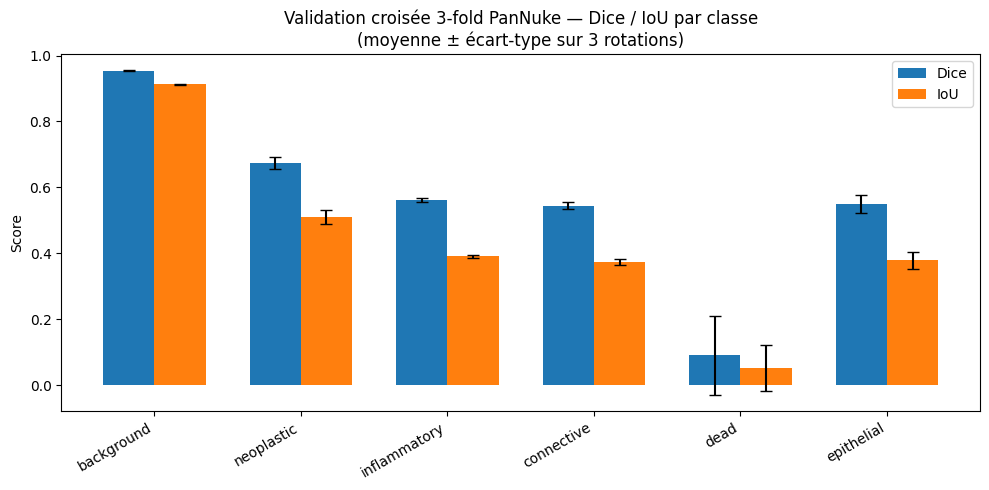

💾 Figure sauvegardée : /kaggle/working/pannuke_output/cross_validation/figures/cross_validation_3fold_dice_iou.png

✅ Validation croisée 3-fold terminée
🏁 CELL 14 TERMINÉE


In [15]:
# ==============================================================================
# 🧪 CELL 14 — VALIDATION CROISÉE 3-FOLD (PROTOCOLE PANNUKE)
# ==============================================================================
#
# Le papier PanNuke (Gamper et al., 2020) recommande d'évaluer sur les
# 3 rotations possibles des folds, et non sur un seul split fixe :
#
#   Split A : Fold1 → train | Fold2 → val | Fold3 → test
#   Split B : Fold2 → train | Fold3 → val | Fold1 → test
#   Split C : Fold3 → train | Fold1 → val | Fold2 → test
#
# Chaque fold sert donc une fois de test, ce qui donne une estimation
# de performance moins dépendante d'un split particulier.
#
# ⚠️ IMPORTANT :
#   - Cette cellule réentraîne un modèle DEPUIS ZÉRO à chaque rotation
#     (aucune fuite de poids entre les folds).
#   - Pour rester réalisable en temps de calcul, on utilise un entraînement
#     à 2 phases (encoder gelé, puis fine-tuning), avec un nombre d'epochs
#     réduit par défaut. Augmente EPOCHS_PHASE1_CV / EPOCHS_PHASE2_CV pour
#     le résultat "final" de ton mémoire.
#   - Les poids de classes sont recalculés à chaque rotation, sur le fold
#     d'entraînement correspondant.
#
# ==============================================================================

import os
import gc
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow import keras
from tensorflow.keras import layers, Model
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras import backend as K

print("=" * 80)
print("🧪 CELL 14 — VALIDATION CROISÉE 3-FOLD (PROTOCOLE PANNUKE)")
print("=" * 80)

# ==============================================================================
# 1. CONFIGURATION
# ==============================================================================

IMAGE_SIZE = (256, 256)
BATCH_SIZE = 8
NUM_CLASSES = 6
IGNORE_LABEL = 255

CLASS_NAMES = [
    "background",
    "neoplastic",
    "inflammatory",
    "connective",
    "dead",
    "epithelial",
]

EPOCHS_PHASE1_CV = 8      # encoder gelé — augmenter pour le résultat final
EPOCHS_PHASE2_CV = 8      # fine-tuning — augmenter pour le résultat final
UNFREEZE_LAST_N_CV = 30

CV_OUTPUT_DIR = os.path.join(OUTPUT_DIR, "cross_validation")
CV_MODELS_DIR = os.path.join(CV_OUTPUT_DIR, "models")
CV_REPORTS_DIR = os.path.join(CV_OUTPUT_DIR, "reports")
CV_FIGURES_DIR = os.path.join(CV_OUTPUT_DIR, "figures")

for d in [CV_OUTPUT_DIR, CV_MODELS_DIR, CV_REPORTS_DIR, CV_FIGURES_DIR]:
    os.makedirs(d, exist_ok=True)

print(f"\n📁 Sortie CV : {CV_OUTPUT_DIR}")

# Les 3 rotations recommandées par le papier PanNuke
SPLITS = [
    {"name": "split_A", "train": 1, "val": 2, "test": 3},
    {"name": "split_B", "train": 2, "val": 1, "test": 3},
    {"name": "split_C", "train": 3, "val": 2, "test": 1},
]

print("\n📋 Rotations :")
for s in SPLITS:
    print(f"   {s['name']} : train=Fold{s['train']} val=Fold{s['val']} test=Fold{s['test']}")


# ==============================================================================
# 2. CHEMINS DES FOLDS (identiques à CELL 05 / CELL 07)
# ==============================================================================

FOLD_PATHS = {
    1: {
        "images": os.path.join(DATASET_ROOT, "fold_1/Fold 1/images/fold1/images.npy"),
        "masks": os.path.join(DATASET_ROOT, "fold_1/Fold 1/masks/fold1/masks.npy"),
    },
    2: {
        "images": os.path.join(DATASET_ROOT, "fold_2/Fold 2/images/fold2/images.npy"),
        "masks": os.path.join(DATASET_ROOT, "fold_2/Fold 2/masks/fold2/masks.npy"),
    },
    3: {
        "images": os.path.join(DATASET_ROOT, "fold_3/Fold 3/images/fold3/images.npy"),
        "masks": os.path.join(DATASET_ROOT, "fold_3/Fold 3/masks/fold3/masks.npy"),
    },
}


# ==============================================================================
# 3. CONVERSION MASQUE PANNUKE → MASQUE SÉMANTIQUE (identique à CELL 07)
# ==============================================================================

def pannuke_to_label_mask(mask):
    mask = np.asarray(mask)
    cell_mask = mask[..., :5]
    overlap = np.sum(cell_mask > 0, axis=-1) > 1
    labels = np.argmax(cell_mask, axis=-1).astype(np.uint8) + 1
    foreground = np.any(cell_mask > 0, axis=-1)
    labels[~foreground] = 0
    labels[overlap] = IGNORE_LABEL
    return labels


def create_tf_dataset(images, masks, training=False):

    def generator():
        for i in range(len(images)):
            image = images[i].astype(np.float32) / 255.0
            image = np.clip(image, 0.0, 1.0)
            mask = pannuke_to_label_mask(masks[i])
            yield image, mask

    output_signature = (
        tf.TensorSpec(shape=(256, 256, 3), dtype=tf.float32),
        tf.TensorSpec(shape=(256, 256), dtype=tf.uint8),
    )

    dataset = tf.data.Dataset.from_generator(generator, output_signature=output_signature)

    if training:
        dataset = dataset.shuffle(buffer_size=512, reshuffle_each_iteration=True)

    dataset = dataset.batch(BATCH_SIZE, drop_remainder=training)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)

    return dataset


# ==============================================================================
# 4. CALCUL DES POIDS DE CLASSES (spécifique à chaque split)
# ==============================================================================

def compute_class_weights(masks, max_samples=600):
    """
    Estime les poids de classes sur un sous-échantillon du fold
    d'entraînement (pour rester rapide), même logique que CELL 13.
    """

    n = min(len(masks), max_samples)
    idx = np.linspace(0, len(masks) - 1, n).astype(int)

    pixel_counts = np.zeros(NUM_CLASSES, dtype=np.float64)

    for i in idx:
        label = pannuke_to_label_mask(masks[i])
        valid = label != IGNORE_LABEL
        vals, counts = np.unique(label[valid], return_counts=True)
        for v, c in zip(vals, counts):
            pixel_counts[int(v)] += c

    freqs = pixel_counts / pixel_counts.sum()

    # Même formule que CELL 13 : poids = fréquence médiane / fréquence de la
    # classe, clippé à [0.25, 4.0]. Une normalisation par la MOYENNE (comme
    # dans une version précédente de cette cellule) écrase presque tous les
    # poids au clip minimum dès qu'une classe est un outlier extrême (ex:
    # "dead"), ce qui annule la pondération pour les autres classes rares.
    # La médiane est beaucoup plus robuste à ce genre d'outlier.
    median_freq = np.median(freqs)
    weights = median_freq / (freqs + 1e-8)
    weights = np.clip(weights, 0.25, 4.0)

    return tf.constant(weights, dtype=tf.float32)


# ==============================================================================
# 5. LOSS ET MÉTRIQUE (Weighted CE, même logique que CELL 13)
# ==============================================================================

def make_weighted_ce_loss(class_weights):

    def loss_fn(y_true, y_pred):
        y_true = tf.cast(y_true, tf.int32)
        mask = tf.not_equal(y_true, IGNORE_LABEL)

        y_true_safe = tf.where(mask, y_true, tf.zeros_like(y_true))
        y_true_oh = tf.one_hot(y_true_safe, NUM_CLASSES)

        ce = tf.keras.losses.categorical_crossentropy(y_true_oh, y_pred)
        sample_weights = tf.gather(class_weights, y_true_safe)

        ce = ce * sample_weights
        mask_f = tf.cast(mask, tf.float32)

        return tf.reduce_sum(ce * mask_f) / (tf.reduce_sum(mask_f) + 1e-6)

    return loss_fn


def foreground_dice_metric(y_true, y_pred):
    y_true = tf.cast(y_true, tf.int32)
    mask = tf.not_equal(y_true, IGNORE_LABEL)

    y_true_safe = tf.where(mask, y_true, tf.zeros_like(y_true))
    y_pred_labels = tf.argmax(y_pred, axis=-1, output_type=tf.int32)

    dices = []
    for c in range(1, NUM_CLASSES):  # on saute background
        true_c = tf.cast(tf.equal(y_true_safe, c), tf.float32) * tf.cast(mask, tf.float32)
        pred_c = tf.cast(tf.equal(y_pred_labels, c), tf.float32) * tf.cast(mask, tf.float32)

        inter = tf.reduce_sum(true_c * pred_c)
        denom = tf.reduce_sum(true_c) + tf.reduce_sum(pred_c)

        dices.append((2.0 * inter + 1e-6) / (denom + 1e-6))

    return tf.reduce_mean(tf.stack(dices))


# ==============================================================================
# 6. CONSTRUCTION DU MODÈLE (identique à CELL 07 — U-Net + EfficientNetB0)
# ==============================================================================

def decoder_block(x, skip, filters, name):
    x = layers.UpSampling2D(size=(2, 2), interpolation="bilinear", name=f"{name}_upsample")(x)
    if skip is not None:
        x = layers.Concatenate(name=f"{name}_concat")([x, skip])
    x = layers.Conv2D(filters, 3, padding="same", use_bias=False, name=f"{name}_conv1")(x)
    x = layers.BatchNormalization(name=f"{name}_bn1")(x)
    x = layers.Activation("relu", name=f"{name}_relu1")(x)
    x = layers.Conv2D(filters, 3, padding="same", use_bias=False, name=f"{name}_conv2")(x)
    x = layers.BatchNormalization(name=f"{name}_bn2")(x)
    x = layers.Activation("relu", name=f"{name}_relu2")(x)
    return x


def build_unet_efficientnetb0(freeze_encoder=True):

    encoder = EfficientNetB0(
        include_top=False,
        weights="imagenet",
        input_shape=(256, 256, 3),
    )
    encoder.trainable = not freeze_encoder

    skip_layer_names = [
        "block2a_expand_activation",
        "block3a_expand_activation",
        "block4a_expand_activation",
        "block6a_expand_activation",
        "top_activation",
    ]
    skip_outputs = [encoder.get_layer(name).output for name in skip_layer_names]
    encoder_model = Model(inputs=encoder.input, outputs=skip_outputs, name="EfficientNetB0_Encoder")

    inputs = layers.Input(shape=(256, 256, 3), name="image_input")
    encoder_input = layers.Rescaling(255.0, name="encoder_rescaling")(inputs)
    features = encoder_model(encoder_input)
    skip1, skip2, skip3, skip4, bottleneck = features

    x = decoder_block(bottleneck, skip4, 256, "decoder4")
    x = decoder_block(x, skip3, 128, "decoder3")
    x = decoder_block(x, skip2, 64, "decoder2")
    x = decoder_block(x, skip1, 32, "decoder1")

    x = layers.UpSampling2D(size=(2, 2), interpolation="bilinear", name="final_upsample")(x)
    x = layers.Conv2D(32, 3, padding="same", use_bias=False, name="final_conv")(x)
    x = layers.BatchNormalization(name="final_bn")(x)
    x = layers.Activation("relu", name="final_relu")(x)

    outputs = layers.Conv2D(NUM_CLASSES, 1, activation="softmax", name="segmentation_output")(x)

    model = Model(inputs=inputs, outputs=outputs, name="PanNuke_UNet_EfficientNetB0")

    return model, encoder_model


# ==============================================================================
# 7. ÉVALUATION SUR LE FOLD DE TEST (Dice / IoU par classe, comme CELL 10)
# ==============================================================================

def evaluate_on_test(model, test_ds):

    dice_inter = np.zeros(NUM_CLASSES, dtype=np.float64)
    dice_pred_sum = np.zeros(NUM_CLASSES, dtype=np.float64)
    dice_true_sum = np.zeros(NUM_CLASSES, dtype=np.float64)

    iou_inter = np.zeros(NUM_CLASSES, dtype=np.float64)
    iou_union = np.zeros(NUM_CLASSES, dtype=np.float64)

    for images, masks in test_ds:

        preds = model.predict(images, verbose=0)
        pred_labels = np.argmax(preds, axis=-1)
        true_labels = masks.numpy()

        valid = true_labels != IGNORE_LABEL

        for c in range(NUM_CLASSES):
            true_c = (true_labels == c) & valid
            pred_c = (pred_labels == c) & valid

            inter = np.sum(true_c & pred_c)

            dice_inter[c] += inter
            dice_pred_sum[c] += np.sum(pred_c)
            dice_true_sum[c] += np.sum(true_c)

            iou_inter[c] += inter
            iou_union[c] += np.sum(true_c | pred_c)

    dice_per_class = (2 * dice_inter + 1e-6) / (dice_pred_sum + dice_true_sum + 1e-6)
    iou_per_class = (iou_inter + 1e-6) / (iou_union + 1e-6)

    return dice_per_class, iou_per_class


# ==============================================================================
# 8. BOUCLE DE VALIDATION CROISÉE
# ==============================================================================

cv_results = []

for split in SPLITS:

    print("\n" + "=" * 80)
    print(f"🔁 ROTATION {split['name'].upper()} — "
          f"train=Fold{split['train']} val=Fold{split['val']} test=Fold{split['test']}")
    print("=" * 80)

    # --- Chargement memmap -------------------------------------------------
    train_images = np.load(FOLD_PATHS[split["train"]]["images"], mmap_mode="r")
    train_masks = np.load(FOLD_PATHS[split["train"]]["masks"], mmap_mode="r")

    val_images = np.load(FOLD_PATHS[split["val"]]["images"], mmap_mode="r")
    val_masks = np.load(FOLD_PATHS[split["val"]]["masks"], mmap_mode="r")

    test_images = np.load(FOLD_PATHS[split["test"]]["images"], mmap_mode="r")
    test_masks = np.load(FOLD_PATHS[split["test"]]["masks"], mmap_mode="r")

    # --- Datasets tf.data ----------------------------------------------
    train_ds_cv = create_tf_dataset(train_images, train_masks, training=True)
    val_ds_cv = create_tf_dataset(val_images, val_masks, training=False)
    test_ds_cv = create_tf_dataset(test_images, test_masks, training=False)

    steps_per_epoch = int(np.ceil(len(train_images) / BATCH_SIZE))
    val_steps = int(np.ceil(len(val_images) / BATCH_SIZE))

    train_fit_cv = train_ds_cv.repeat()
    val_fit_cv = val_ds_cv.repeat()

    # --- Poids de classes spécifiques au split --------------------------
    print("\n⚖️ Calcul des poids de classes du fold d'entraînement...")
    class_weights_cv = compute_class_weights(train_masks)
    for i, name in enumerate(CLASS_NAMES):
        print(f"   [{i}] {name:15s} → {float(class_weights_cv[i]):.4f}")

    loss_fn_cv = make_weighted_ce_loss(class_weights_cv)

    # --- PHASE 1 : encoder gelé ------------------------------------------
    print("\n🚀 Phase 1 (encoder gelé)...")

    model, encoder_model = build_unet_efficientnetb0(freeze_encoder=True)

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-4),
        loss=loss_fn_cv,
        metrics=[foreground_dice_metric],
    )

    ckpt_phase1 = os.path.join(CV_MODELS_DIR, f"{split['name']}_phase1_best.keras")

    callbacks_phase1 = [
        keras.callbacks.ModelCheckpoint(
            ckpt_phase1, monitor="val_foreground_dice_metric",
            mode="max", save_best_only=True, verbose=0,
        ),
        keras.callbacks.EarlyStopping(
            monitor="val_foreground_dice_metric", mode="max",
            patience=4, restore_best_weights=True, verbose=0,
        ),
    ]

    model.fit(
        train_fit_cv,
        validation_data=val_fit_cv,
        steps_per_epoch=steps_per_epoch,
        validation_steps=val_steps,
        epochs=EPOCHS_PHASE1_CV,
        callbacks=callbacks_phase1,
        verbose=1,
    )

    # --- PHASE 2 : fine-tuning -------------------------------------------
    print("\n🚀 Phase 2 (fine-tuning)...")

    encoder_model.trainable = True
    for layer in encoder_model.layers[:-UNFREEZE_LAST_N_CV]:
        layer.trainable = False
    for layer in encoder_model.layers:
        if isinstance(layer, layers.BatchNormalization):
            layer.trainable = False  # BN reste gelée, comme CELL 09

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-5),
        loss=loss_fn_cv,
        metrics=[foreground_dice_metric],
    )

    ckpt_phase2 = os.path.join(CV_MODELS_DIR, f"{split['name']}_phase2_best.keras")

    callbacks_phase2 = [
        keras.callbacks.ModelCheckpoint(
            ckpt_phase2, monitor="val_foreground_dice_metric",
            mode="max", save_best_only=True, verbose=0,
        ),
        keras.callbacks.EarlyStopping(
            monitor="val_foreground_dice_metric", mode="max",
            patience=4, restore_best_weights=True, verbose=0,
        ),
        keras.callbacks.ReduceLROnPlateau(
            monitor="val_foreground_dice_metric", mode="max",
            factor=0.5, patience=2, verbose=0,
        ),
    ]

    model.fit(
        train_fit_cv,
        validation_data=val_fit_cv,
        steps_per_epoch=steps_per_epoch,
        validation_steps=val_steps,
        epochs=EPOCHS_PHASE2_CV,
        callbacks=callbacks_phase2,
        verbose=1,
    )

    # --- Évaluation sur le fold de test (jamais vu à l'entraînement) -----
    print(f"\n📊 Évaluation sur Fold {split['test']}...")

    dice_per_class, iou_per_class = evaluate_on_test(model, test_ds_cv)

    for i, name in enumerate(CLASS_NAMES):
        print(f"   [{i}] {name:15s} Dice={dice_per_class[i]:.4f}  IoU={iou_per_class[i]:.4f}")

    cv_results.append({
        "split": split["name"],
        "train_fold": split["train"],
        "val_fold": split["val"],
        "test_fold": split["test"],
        "dice_per_class": dice_per_class,
        "iou_per_class": iou_per_class,
        "dice_mean_fg": float(np.mean(dice_per_class[1:])),
        "iou_mean_fg": float(np.mean(iou_per_class[1:])),
    })

    # --- Nettoyage mémoire avant la rotation suivante ---------------------
    del model, encoder_model
    del train_images, train_masks, val_images, val_masks, test_images, test_masks
    del train_ds_cv, val_ds_cv, test_ds_cv, train_fit_cv, val_fit_cv
    K.clear_session()
    gc.collect()


# ==============================================================================
# 9. AGRÉGATION DES RÉSULTATS (moyenne ± écart-type sur les 3 rotations)
# ==============================================================================

print("\n" + "=" * 80)
print("📊 RÉSULTATS AGRÉGÉS — VALIDATION CROISÉE 3-FOLD")
print("=" * 80)

dice_matrix = np.stack([r["dice_per_class"] for r in cv_results])  # (3, 6)
iou_matrix = np.stack([r["iou_per_class"] for r in cv_results])    # (3, 6)

dice_mean = dice_matrix.mean(axis=0)
dice_std = dice_matrix.std(axis=0)

iou_mean = iou_matrix.mean(axis=0)
iou_std = iou_matrix.std(axis=0)

print("\n📌 Par classe (moyenne ± écart-type sur les 3 folds) :\n")
for i, name in enumerate(CLASS_NAMES):
    print(
        f"   [{i}] {name:15s} "
        f"Dice = {dice_mean[i]:.4f} ± {dice_std[i]:.4f}   "
        f"IoU = {iou_mean[i]:.4f} ± {iou_std[i]:.4f}"
    )

fg_dice_scores = [r["dice_mean_fg"] for r in cv_results]
fg_iou_scores = [r["iou_mean_fg"] for r in cv_results]

print("\n📌 Dice / IoU foreground moyen (hors background), par rotation :")
for r in cv_results:
    print(f"   {r['split']} (test=Fold{r['test_fold']}) : "
          f"Dice_fg={r['dice_mean_fg']:.4f}  IoU_fg={r['iou_mean_fg']:.4f}")

print(f"\n🎯 Dice foreground global : {np.mean(fg_dice_scores):.4f} ± {np.std(fg_dice_scores):.4f}")
print(f"🎯 IoU  foreground global : {np.mean(fg_iou_scores):.4f} ± {np.std(fg_iou_scores):.4f}")


# ==============================================================================
# 10. SAUVEGARDE DES RÉSULTATS (CSV + figure)
# ==============================================================================

rows = []
for r in cv_results:
    for i, name in enumerate(CLASS_NAMES):
        rows.append({
            "split": r["split"],
            "train_fold": r["train_fold"],
            "val_fold": r["val_fold"],
            "test_fold": r["test_fold"],
            "class": name,
            "dice": r["dice_per_class"][i],
            "iou": r["iou_per_class"][i],
        })

cv_df = pd.DataFrame(rows)
cv_csv_path = os.path.join(CV_REPORTS_DIR, "cross_validation_3fold_results.csv")
cv_df.to_csv(cv_csv_path, index=False)
print(f"\n💾 Résultats détaillés sauvegardés : {cv_csv_path}")

summary_df = pd.DataFrame({
    "class": CLASS_NAMES,
    "dice_mean": dice_mean,
    "dice_std": dice_std,
    "iou_mean": iou_mean,
    "iou_std": iou_std,
})
summary_csv_path = os.path.join(CV_REPORTS_DIR, "cross_validation_3fold_summary.csv")
summary_df.to_csv(summary_csv_path, index=False)
print(f"💾 Résumé sauvegardé : {summary_csv_path}")

fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(NUM_CLASSES)
width = 0.35

ax.bar(x - width / 2, dice_mean, width, yerr=dice_std, capsize=4, label="Dice")
ax.bar(x + width / 2, iou_mean, width, yerr=iou_std, capsize=4, label="IoU")

ax.set_xticks(x)
ax.set_xticklabels(CLASS_NAMES, rotation=30, ha="right")
ax.set_ylabel("Score")
ax.set_title(
    "Validation croisée 3-fold PanNuke — Dice / IoU par classe\n"
    "(moyenne ± écart-type sur 3 rotations)"
)
ax.legend()
plt.tight_layout()

fig_path = os.path.join(CV_FIGURES_DIR, "cross_validation_3fold_dice_iou.png")
plt.savefig(fig_path, dpi=150)
plt.show()

print(f"💾 Figure sauvegardée : {fig_path}")

print("\n✅ Validation croisée 3-fold terminée")
print("=" * 80)
print("🏁 CELL 14 TERMINÉE")
print("=" * 80)
